# 💎 다이아몬드 가격 회귀분석 — 등급의 역설과 '도메인 지식 vs 기계적 변수 제거'

> 5.4만 건의 다이아몬드 데이터로 **품질 점검 → EDA → 전처리 조합 비교 → 도메인 지식 모델**을 하나의 흐름으로 수행했습니다.
> EDA에서는 **"등급이 나쁠수록 더 비싸다"는 역설**이 나타났고, 회귀모델로 중량을 통제하자 등급 순서가 정확히 복원됐습니다.

| 항목 | 내용 |
|---|---|
| **데이터** | Diamonds · 53,940행 → 중복 146행 · 불가능한 치수 22행 제거 후 53,772행 |
| **종속변수** | `price` 가격 ($) |
| **분석 질문** | ① 가격은 무엇으로 결정되는가? ② 등급(컷·색상·투명도)은 정말 가격을 올리는가? ③ VIF에게 변수 선택을 맡겨도 되는가? |
| **주요 기법** | Spearman 상관 · Welch ANOVA · Games-Howell · 로그-로그 회귀(탄력성) · VIF · 후진소거 OLS · HC3 |

### 📑 목차
0. **준비** — 라이브러리, 데이터 로드(1회), 분석 설정(등급 순서)
1. **PART 1. 데이터 품질 점검** — `my_qtcheck` + 물리적으로 불가능한 값 제거
2. **PART 2. EDA** — 단변량 → 이변량(등급의 역설) → 다변량
3. **PART 3. 회귀모델링** — 기계적 전처리 vs 도메인 지식 모델, EDA 판정 vs 모델 결과, 최종 보고
4. **📌 종합 인사이트**

> ⚙️ **사용 모듈** : `my_qtcheck` · `my_plot` · `my_stats` · `my_prep` · `my_ols` (helpers) · 데이터 로더 `jussam`

---
# 0. 준비

### (1) 라이브러리 참조

In [1]:
# ----- 라이브러리 참조
import numpy as np
from pandas import DataFrame, concat, set_option
from IPython.display import display, Markdown

from jussam import load_data      # 실습 데이터 로더
from helpers import *             # my_qtcheck · my_plot · my_stats · my_prep · my_ols

# ----- 출력 형식 (소수점 3자리, 컬럼 생략 없이)
set_option("display.float_format", "{:,.3f}".format)
set_option("display.max_columns", 50)

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: develop


### (2) 데이터 로드

- 데이터는 **이 셀에서 단 한 번만** 불러온다.

In [2]:
origin = load_data("diamonds")
print(origin.shape)
origin.head()

📚 다이아몬드를 커팅, 색상, 투명도, 가격 및 기타 속성 조사한 데이터 셋 (출처: https://www.kaggle.com/datasets/shivam2503/diamonds)

    field    description
--  -------  -------------------------------------------------------------------
 0  price    다이아몬드 가격 (USD, $326 ~ $18,823)
 1  carat    중량 (0.2~5.01)
 2  cut      컷 품질 (Fair, Good, Very Good, Premium, Ideal)
 3  color    색상 등급 - J (worst) to D (best)
 4  clarity  투명도 등급 (I1 (worst), SI2, SI1, VS2, VS1, VVS2, VVS1, IF (best))
 5  x        길이 mm (0~10.74)
 6  y        너비 mm (0--58.9)
 7  z        두께 mm (0--31.8)
 8  depth    비율 정보 = z / mean(x, y) = 2 * z / (x + y) (43--79)
 9  table    다이아몬드의 가장 넓은 지점에 비해 상단(테이블)의 너비 (43--95)

(53940, 10)


,price,carat,cut,color,clarity,x,y,z,depth,table
0,326,0.230,Ideal,E,SI2,3.950,3.980,2.430,61.500,55.000
1,326,0.210,Premium,E,SI1,3.890,3.840,2.310,59.800,61.000
2,327,0.230,Good,E,VS1,4.050,4.070,2.310,56.900,65.000
3,334,0.290,Premium,I,VS2,4.200,4.230,2.630,62.400,58.000
4,335,0.310,Good,J,SI2,4.340,4.350,2.750,63.300,58.000


### (3) 분석 설정

- 다이아몬드 가격은 보통 **4C**로 정해진다.

| 4C | 의미 | 변수 | 좋은 쪽 |
|---|---|---|---|
| Carat | 무게 (1캐럿 = 0.2g) | `carat` | 클수록 비쌈 (품질 등급이 아니라 **크기**) |
| Cut | 연마 품질 | `cut` | Fair → **Ideal** |
| Color | 색 (무색에 가까울수록 좋음) | `color` | J → **D** |
| Clarity | 투명도 (내부 흠이 적을수록 좋음) | `clarity` | I1 → **IF** |

- `cut` · `color` · `clarity`는 **품질 등급**, `carat`은 **크기**다. 크지만 등급이 낮은 돌도, 작지만 등급이 높은 돌도 있다.
- `ordinal_map` : 등급 변수의 **낮은 등급 → 높은 등급** 순서 (GIA 기준)

In [3]:
target = "price"
as_category = ["cut", "color", "clarity"]

ordinal_map = {
    "cut":     ["Fair", "Good", "Very Good", "Premium", "Ideal"],
    "color":   ["J", "I", "H", "G", "F", "E", "D"],
    "clarity": ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"],
}

column_means = {
    "price": "가격($)", "carat": "중량", "cut": "컷 등급", "color": "색상 등급",
    "clarity": "투명도 등급", "x": "길이(mm)", "y": "너비(mm)", "z": "깊이(mm)",
    "depth": "깊이 비율(%)", "table": "테이블 비율(%)",
}

---
# PART 1. 데이터 품질 점검

### (1) 자료형 변환 + 등급 순서 지정

In [4]:
df = my_qtcheck.set_type(origin, as_category=as_category)

# 등급 순서 지정 (시각화·집계 순서를 등급 순서와 맞춘다)
for col, order in ordinal_map.items(): # 인덱스, 값
    df[col] = df[col].cat.reorder_categories(order, ordered=True)

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   price    53940 non-null  int32   
 1   carat    53940 non-null  float32 
 2   cut      53940 non-null  category
 3   color    53940 non-null  category
 4   clarity  53940 non-null  category
 5   x        53940 non-null  float32 
 6   y        53940 non-null  float32 
 7   z        53940 non-null  float32 
 8   depth    53940 non-null  float32 
 9   table    53940 non-null  float32 
dtypes: category(3), float32(6), int32(1)
memory usage: 1.6 MB


### (2) 중복 · 결측치 점검

In [5]:
df = my_qtcheck.check_duplicates(df)
my_qtcheck.check_missing_values(df)

중복된 행의 수: 146
중복된 행이 제거되었습니다.


,Missing Count,Missing Ratio (%)
price,0,0.000
carat,0,0.000
cut,0,0.000
color,0,0.000
clarity,0,0.000
x,0,0.000
y,0,0.000
z,0,0.000
depth,0,0.000
table,0,0.000


### (3) 명목형 변수 기술통계

In [6]:
cat_desc = my_qtcheck.categorical_summary(df)
cat_desc

컬럼 'cut'의 value_counts( ):


,count
cut,
Fair,1598
Good,4891
Very Good,12069
Premium,13748
Ideal,21488


컬럼 'color'의 value_counts( ):


,count
color,
J,2802
I,5407
H,8272
G,11262
F,9520
E,9776
D,6755


컬럼 'clarity'의 value_counts( ):


,count
clarity,
I1,740
SI2,9150
SI1,13032
VS2,12229
VS1,8156
VVS2,5056
VVS1,3647
IF,1784


,cut,color,clarity
count,53794,53794,53794
unique,5,7,8
top,Ideal,G,SI1
freq,21488,11262,13032


### (4) 연속형 변수 기술통계 · 이상치 · 왜도/첨도 · 로그변환 판정

In [7]:
num_desc = my_qtcheck.numerical_summary(df)
num_desc

,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,iqr,upper_bound,lower_bound,upper_outliers,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,total_outliers,total_outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
price,"53,794.000","3,933.065","3,988.114",326.000,951.000,"2,401.000","5,326.750","18,823.000",0.638,large_diff,"4,375.750","11,890.375","-5,612.625",3523,0.065,0,0.000,3523,0.065,1.618,right tail,2.178,leptokurtic,log
carat,"53,794.000",0.798,0.473,0.200,0.400,0.700,1.040,5.010,0.140,diff,0.640,2.000,-0.560,2136,0.040,0,0.000,2136,0.040,1.114,right tail,1.247,leptokurtic,log
x,"53,794.000",5.731,1.121,0.000,4.710,5.700,6.540,10.740,0.005,similar,1.830,9.285,1.965,24,0.000,7,0.000,31,0.001,0.380,symmetric,-0.629,platykurtic,none
y,"53,794.000",5.735,1.141,0.000,4.720,5.710,6.540,58.900,0.004,similar,1.820,9.270,1.990,22,0.000,6,0.000,28,0.001,2.446,right tail,91.752,leptokurtic,log1p
z,"53,794.000",3.539,0.705,0.000,2.910,3.530,4.030,31.800,0.002,similar,1.120,5.710,1.230,28,0.001,20,0.000,48,0.001,1.529,right tail,47.384,leptokurtic,log1p
depth,"53,794.000",61.748,1.430,43.000,61.000,61.800,62.500,79.000,0.001,similar,1.500,64.750,58.750,1027,0.019,1498,0.028,2525,0.047,-0.114,symmetric,5.413,leptokurtic,none
table,"53,794.000",57.458,2.234,43.000,56.000,57.000,59.000,95.000,0.008,similar,3.000,63.500,51.500,588,0.011,16,0.000,604,0.011,0.792,right tail,2.775,leptokurtic,log


### (5) 값의 유효성 점검 — 물리적으로 불가능한 값 제거

- 기술통계에서 `x`·`y`·`z`의 **최솟값 0**, `y`·`z`의 **비정상적으로 큰 최댓값**이 보인다.
- 길이·너비·깊이가 0mm인 다이아몬드는 존재할 수 없다.
- 너비 58.9mm(약 6cm)는 이 데이터의 최대 다이아몬드(5캐럿, 약 11mm)보다 5배 넘게 크다. 기록된 무게(캐럿)와 크기가 맞지 않아 **측정·입력 오류**로 보고 제거한다.

In [8]:
print("정제 전:", df.shape)

# 길이·너비·깊이가 0mm인 행 제거 (존재할 수 없는 다이아몬드)
df = df[(df["x"] > 0) & (df["y"] > 0) & (df["z"] > 0)]

# 너비·깊이가 20mm를 넘는 행 제거 (수백 캐럿 크기, 입력 오류)
df = df[(df["y"] <= 20) & (df["z"] <= 20)]

print("정제 후:", df.shape)

정제 전: (53794, 10)
정제 후: (53772, 10)


### (6) 기술통계량 재확인

In [9]:
num_desc2 = my_qtcheck.numerical_summary(df)
num_desc2

,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,iqr,upper_bound,lower_bound,upper_outliers,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,total_outliers,total_outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
price,"53,772.000","3,931.137","3,985.853",326.000,951.000,"2,401.000","5,324.000","18,823.000",0.637,large_diff,"4,373.000","11,883.500","-5,608.500",3519,0.065,0,0.000,3519,0.065,1.618,right tail,2.180,leptokurtic,log
carat,"53,772.000",0.798,0.473,0.200,0.400,0.700,1.040,5.010,0.139,diff,0.640,2.000,-0.560,2129,0.040,0,0.000,2129,0.040,1.113,right tail,1.246,leptokurtic,log
x,"53,772.000",5.732,1.119,3.730,4.710,5.700,6.540,10.740,0.006,similar,1.830,9.285,1.965,24,0.000,0,0.000,24,0.000,0.397,symmetric,-0.704,platykurtic,none
y,"53,772.000",5.733,1.111,3.680,4.720,5.710,6.540,10.540,0.004,similar,1.820,9.270,1.990,20,0.000,0,0.000,20,0.000,0.391,symmetric,-0.717,platykurtic,none
z,"53,772.000",3.539,0.691,1.070,2.910,3.530,4.030,6.980,0.003,similar,1.120,5.710,1.230,26,0.000,1,0.000,27,0.001,0.392,symmetric,-0.695,platykurtic,none
depth,"53,772.000",61.748,1.430,43.000,61.000,61.800,62.500,79.000,0.001,similar,1.500,64.750,58.750,1027,0.019,1496,0.028,2523,0.047,-0.114,symmetric,5.420,leptokurtic,none
table,"53,772.000",57.458,2.233,43.000,56.000,57.000,59.000,95.000,0.008,similar,3.000,63.500,51.500,587,0.011,16,0.000,603,0.011,0.792,right tail,2.775,leptokurtic,log


> 💡 **인사이트 — 품질 점검**
>
> - 결측은 없지만 **완전 중복 146행**이 있어 제거했다.
> - 기술통계가 '불가능한 값'을 잡아냈다. `y`의 **첨도 91.8**, `z`의 첨도 47.4는 분포가 아니라 **오류값**의 신호였다.
>   - `x`·`y`·`z`의 최솟값 0mm : 크기가 0인 다이아몬드는 존재할 수 없다.
>   - `y` 최댓값 58.9mm, `z` 최댓값 31.8mm : 최대 다이아몬드(약 11mm)의 3~5배라 무게와 맞지 않는다.
> - 두 조건으로 **22행(0.04%)** 을 제거했다(53,794행 → 53,772행). 비율이 매우 작아 분석에 영향이 없고, 남겨 두면 크기 변수의 계수를 왜곡한다.
> - 5개 변수에 로그변환을 판정했다.
>   - `price`(왜도 1.62) · `carat`(1.11) · `table`(0.79) : 우편향이라 **log**
>   - `y` · `z` : **log1p** 판정을 받았지만, 이는 앞의 오류값(0mm, 58.9mm · 31.8mm) 때문이다. 오류값을 제거하면 대칭에 가까워져 변환이 필요 없어진다.

---
# PART 2. 탐색적 데이터 분석(EDA)

### (1) 변수 유형 분류

In [10]:
nominal_cols = my_qtcheck.get_categorical_column_names(df)
continuous_cols = my_qtcheck.get_number_column_names(df)
continuous_cols.remove(target)
print("명목형 :", nominal_cols)
print("연속형 :", continuous_cols)

명목형 : ['cut', 'color', 'clarity']
연속형 : ['carat', 'x', 'y', 'z', 'depth', 'table']


## 2-1. 단변량 분석

### (1) 종속변수 분포

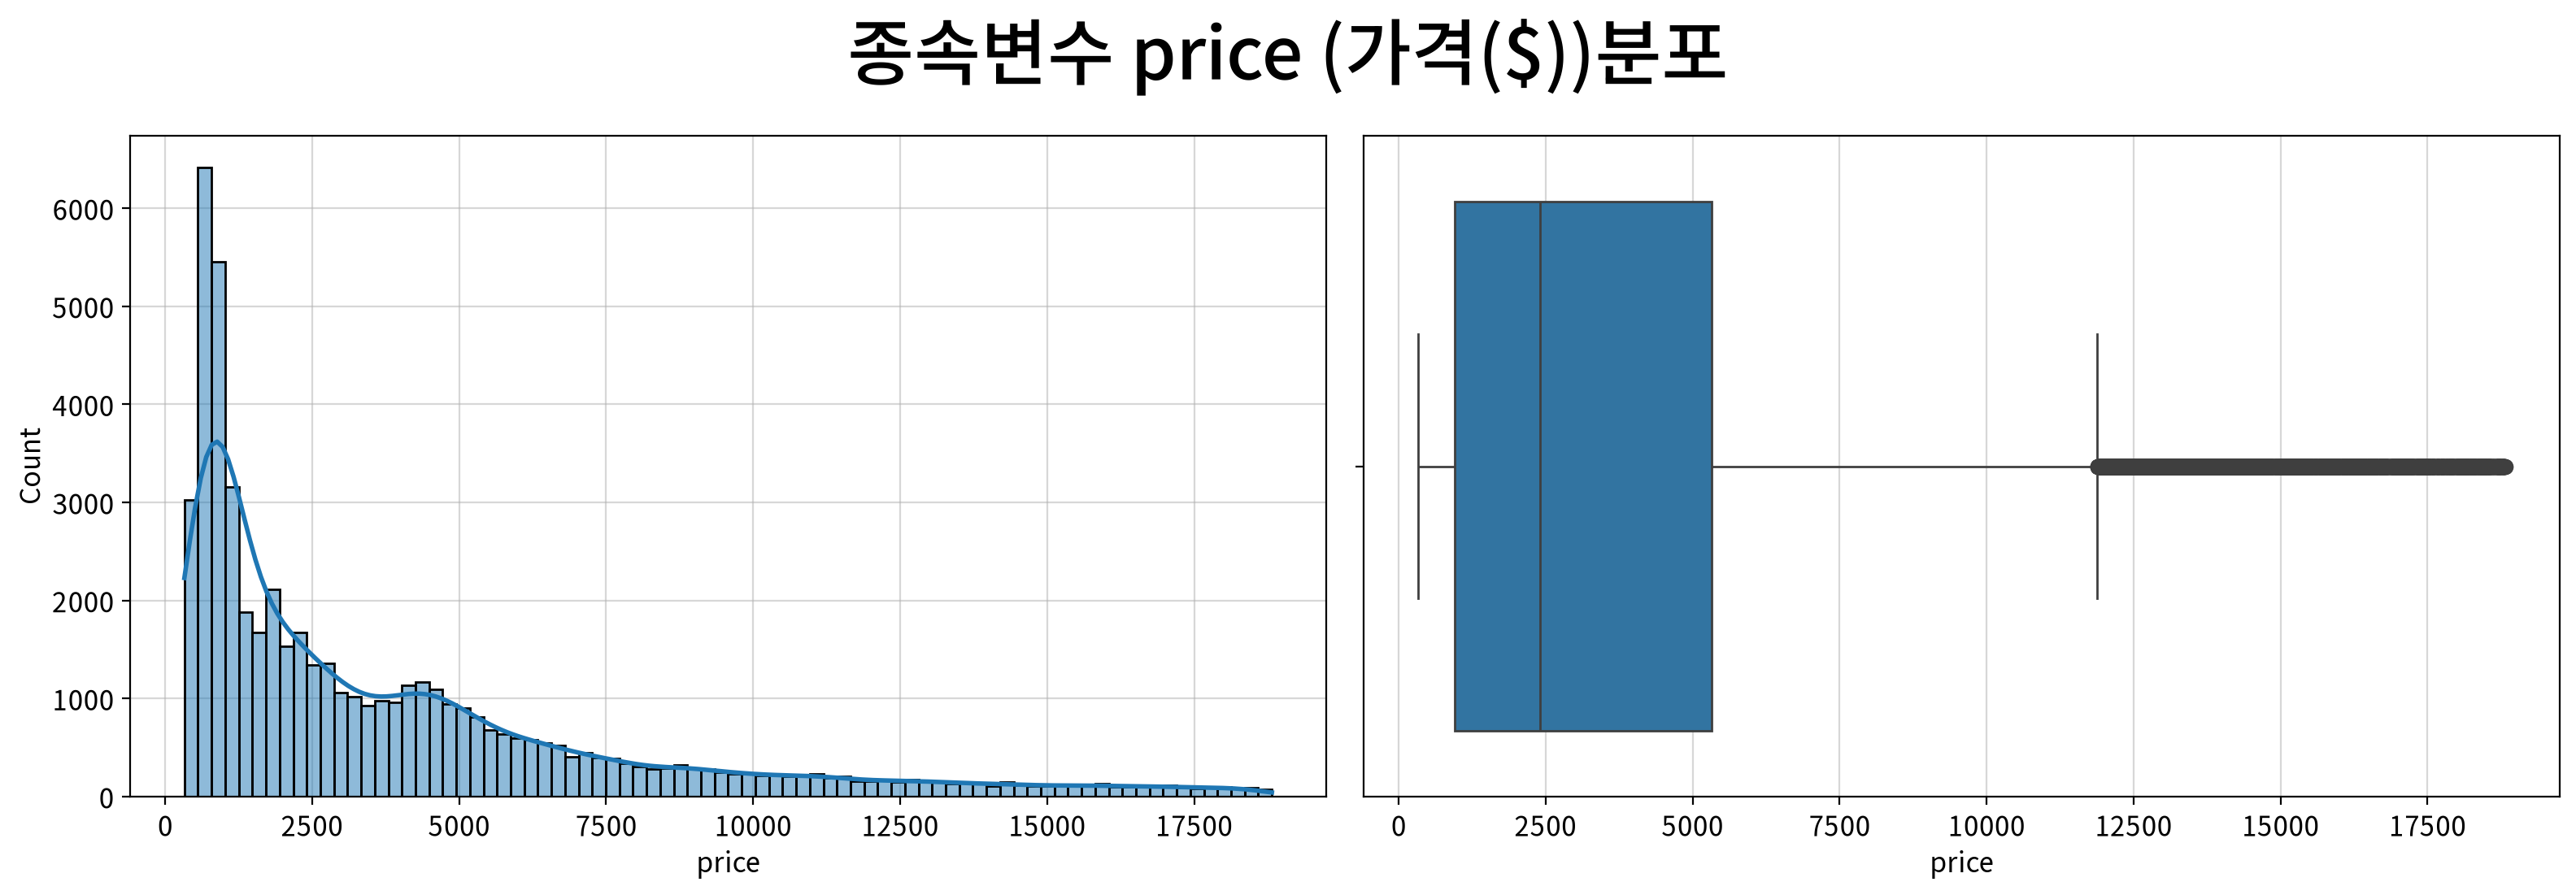

In [11]:
fig, ax = my_plot.init(rows=1, cols=2, width=800, height=560, title=f"종속변수 {target} ({column_means[target]})분포")
my_plot.histplot(data=df, x=target, kde=True, ax=ax[0])
my_plot.boxplot(data=df, x=target, ax=ax[1])
my_plot.show()

### (2) 연속형 독립변수 분포

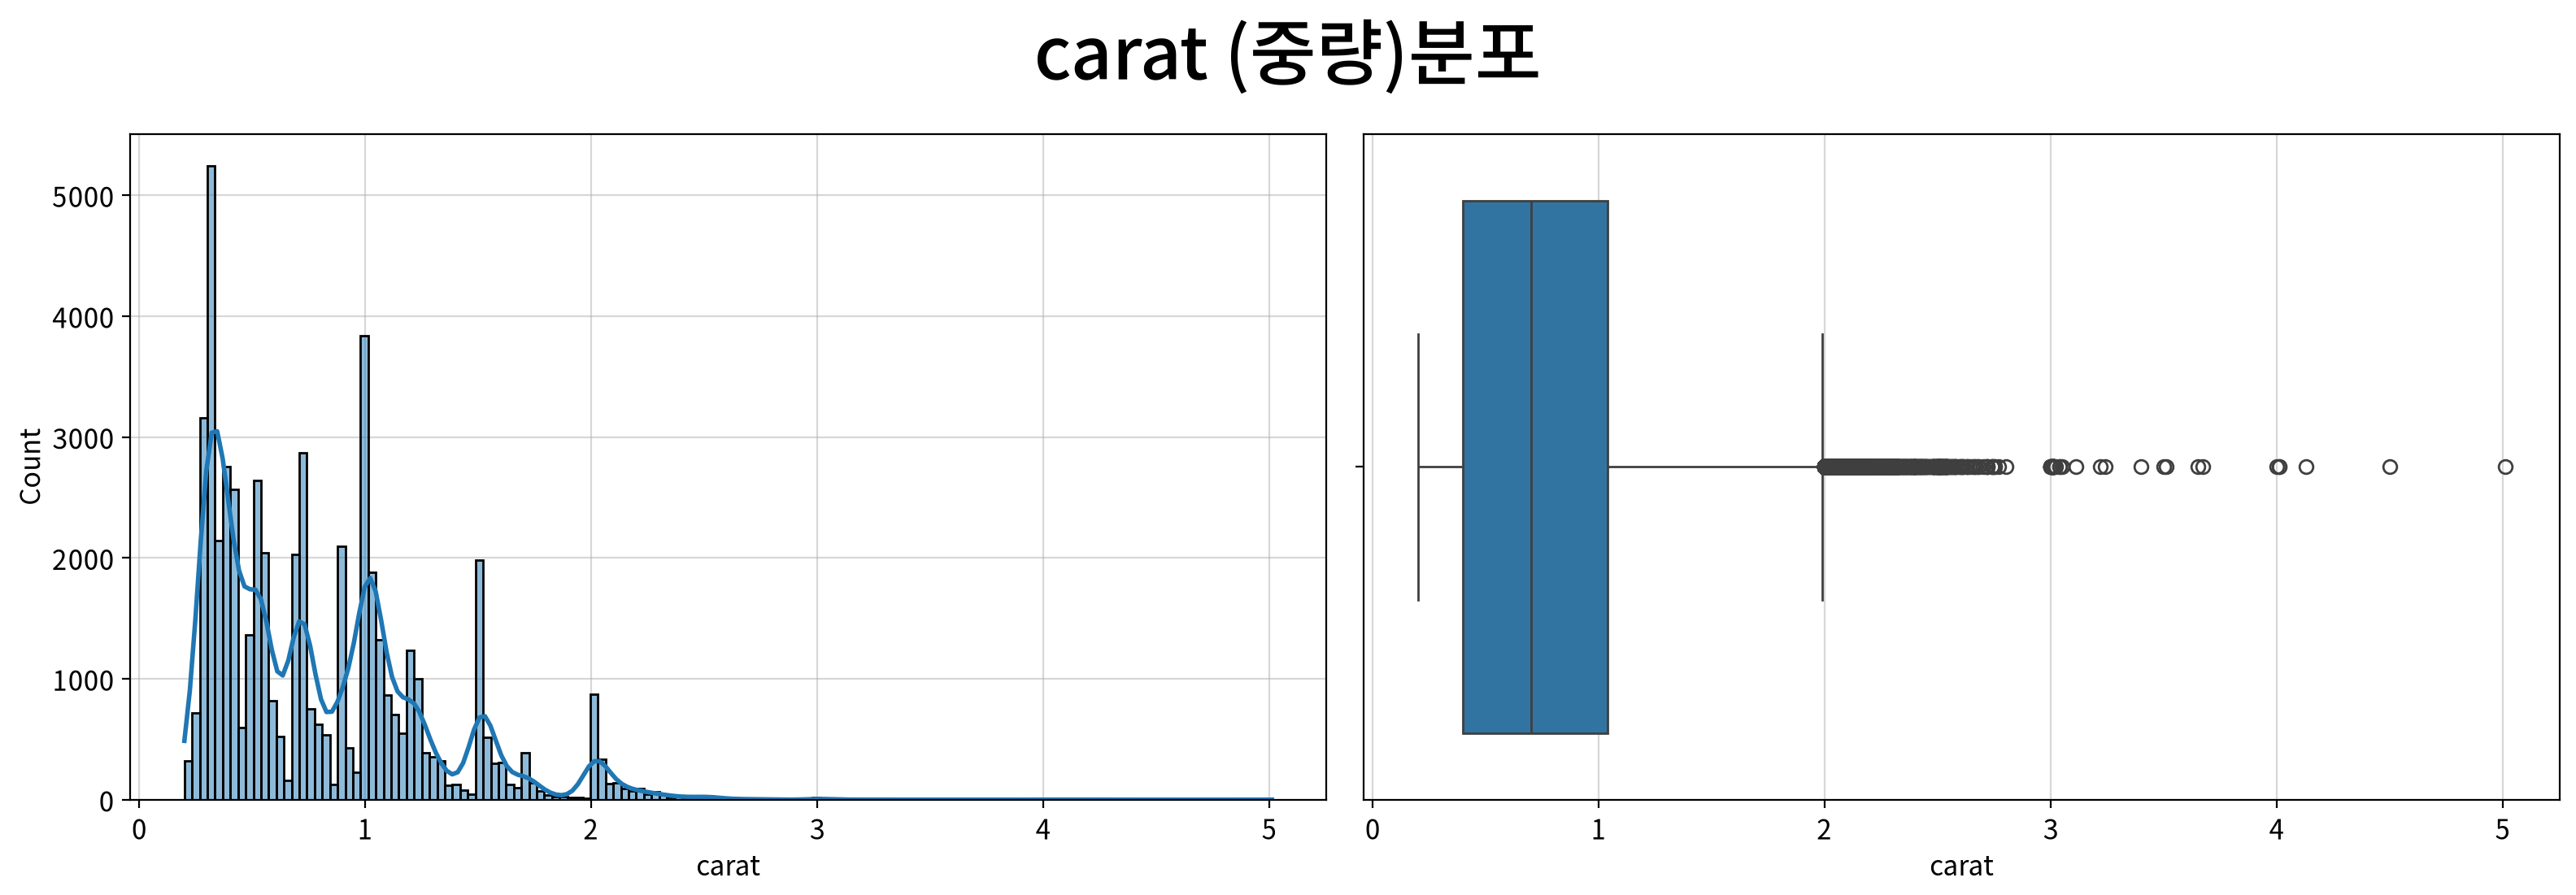

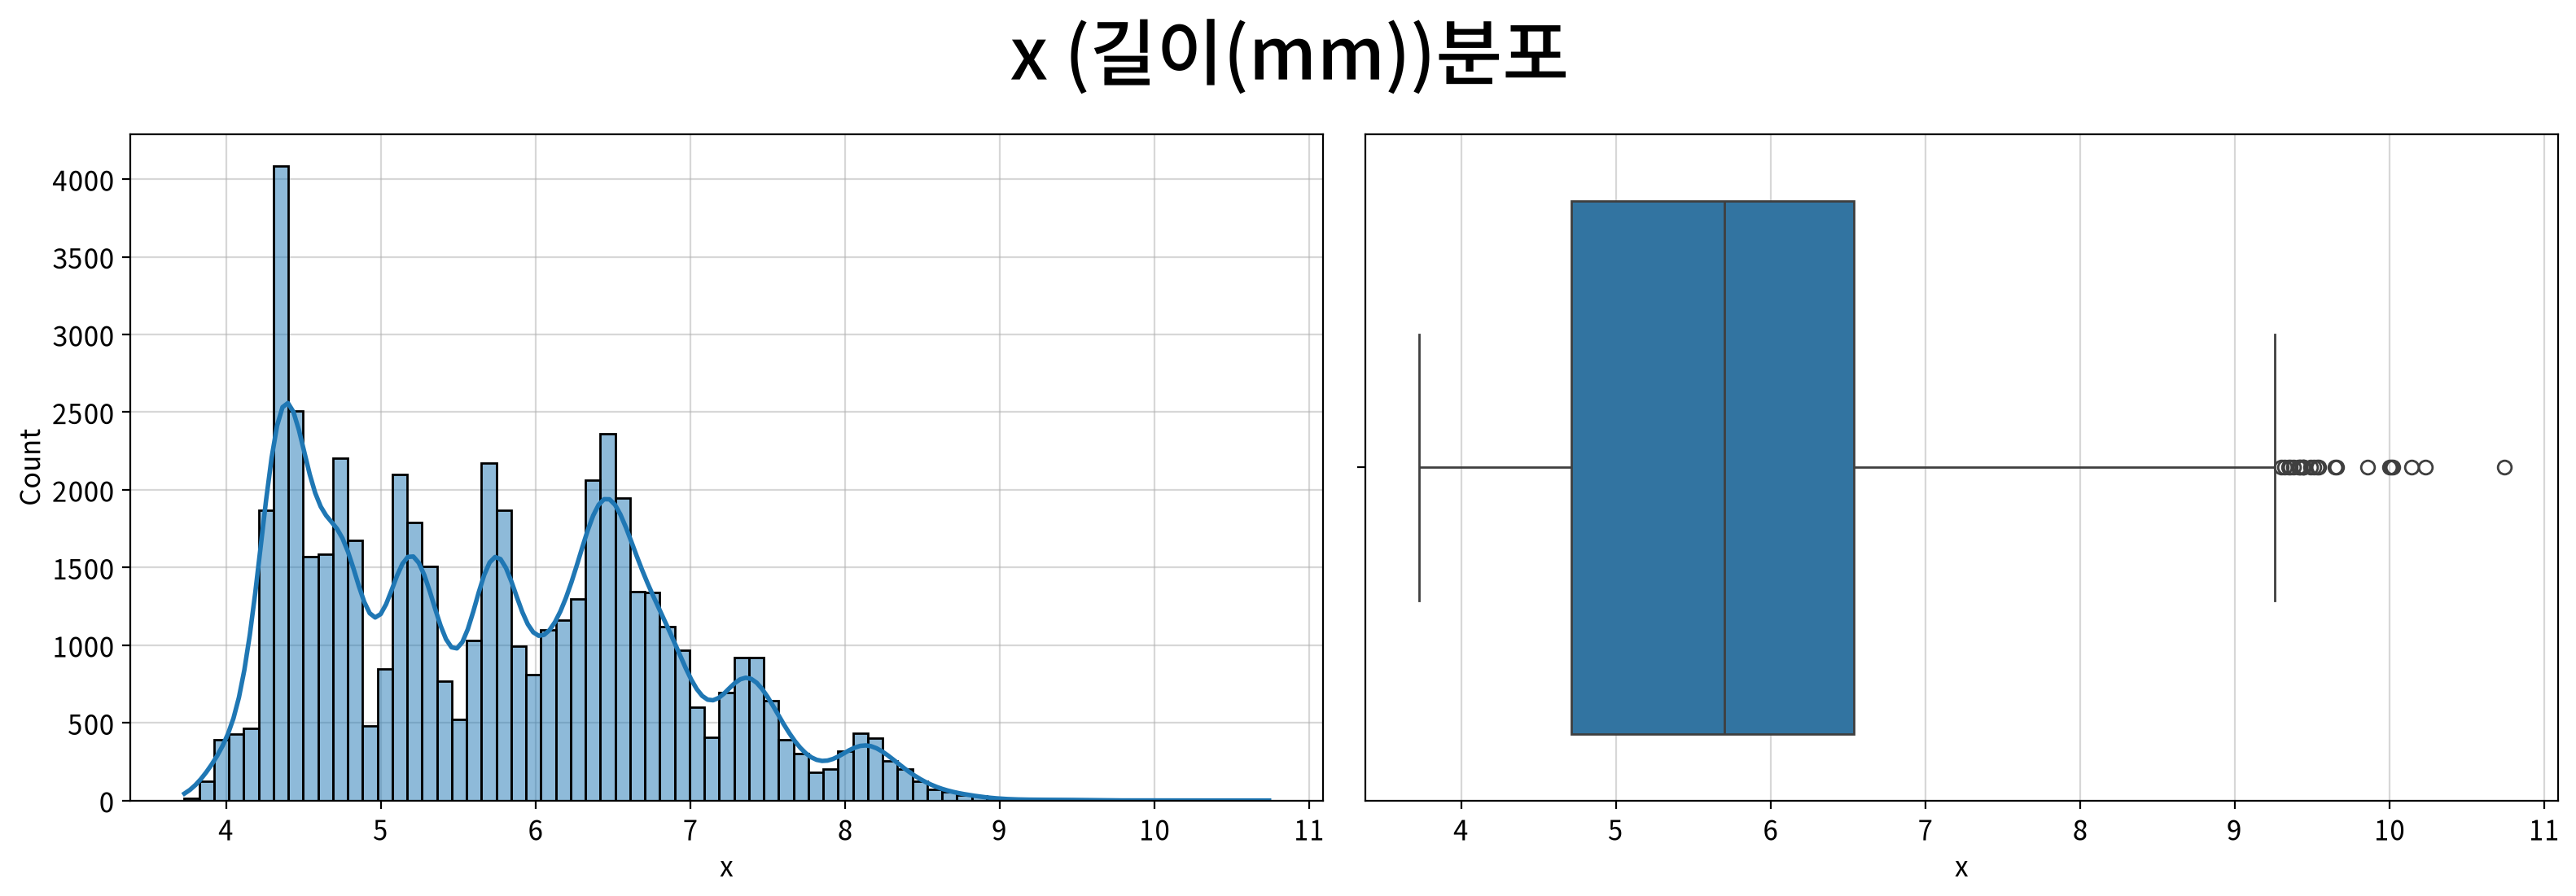

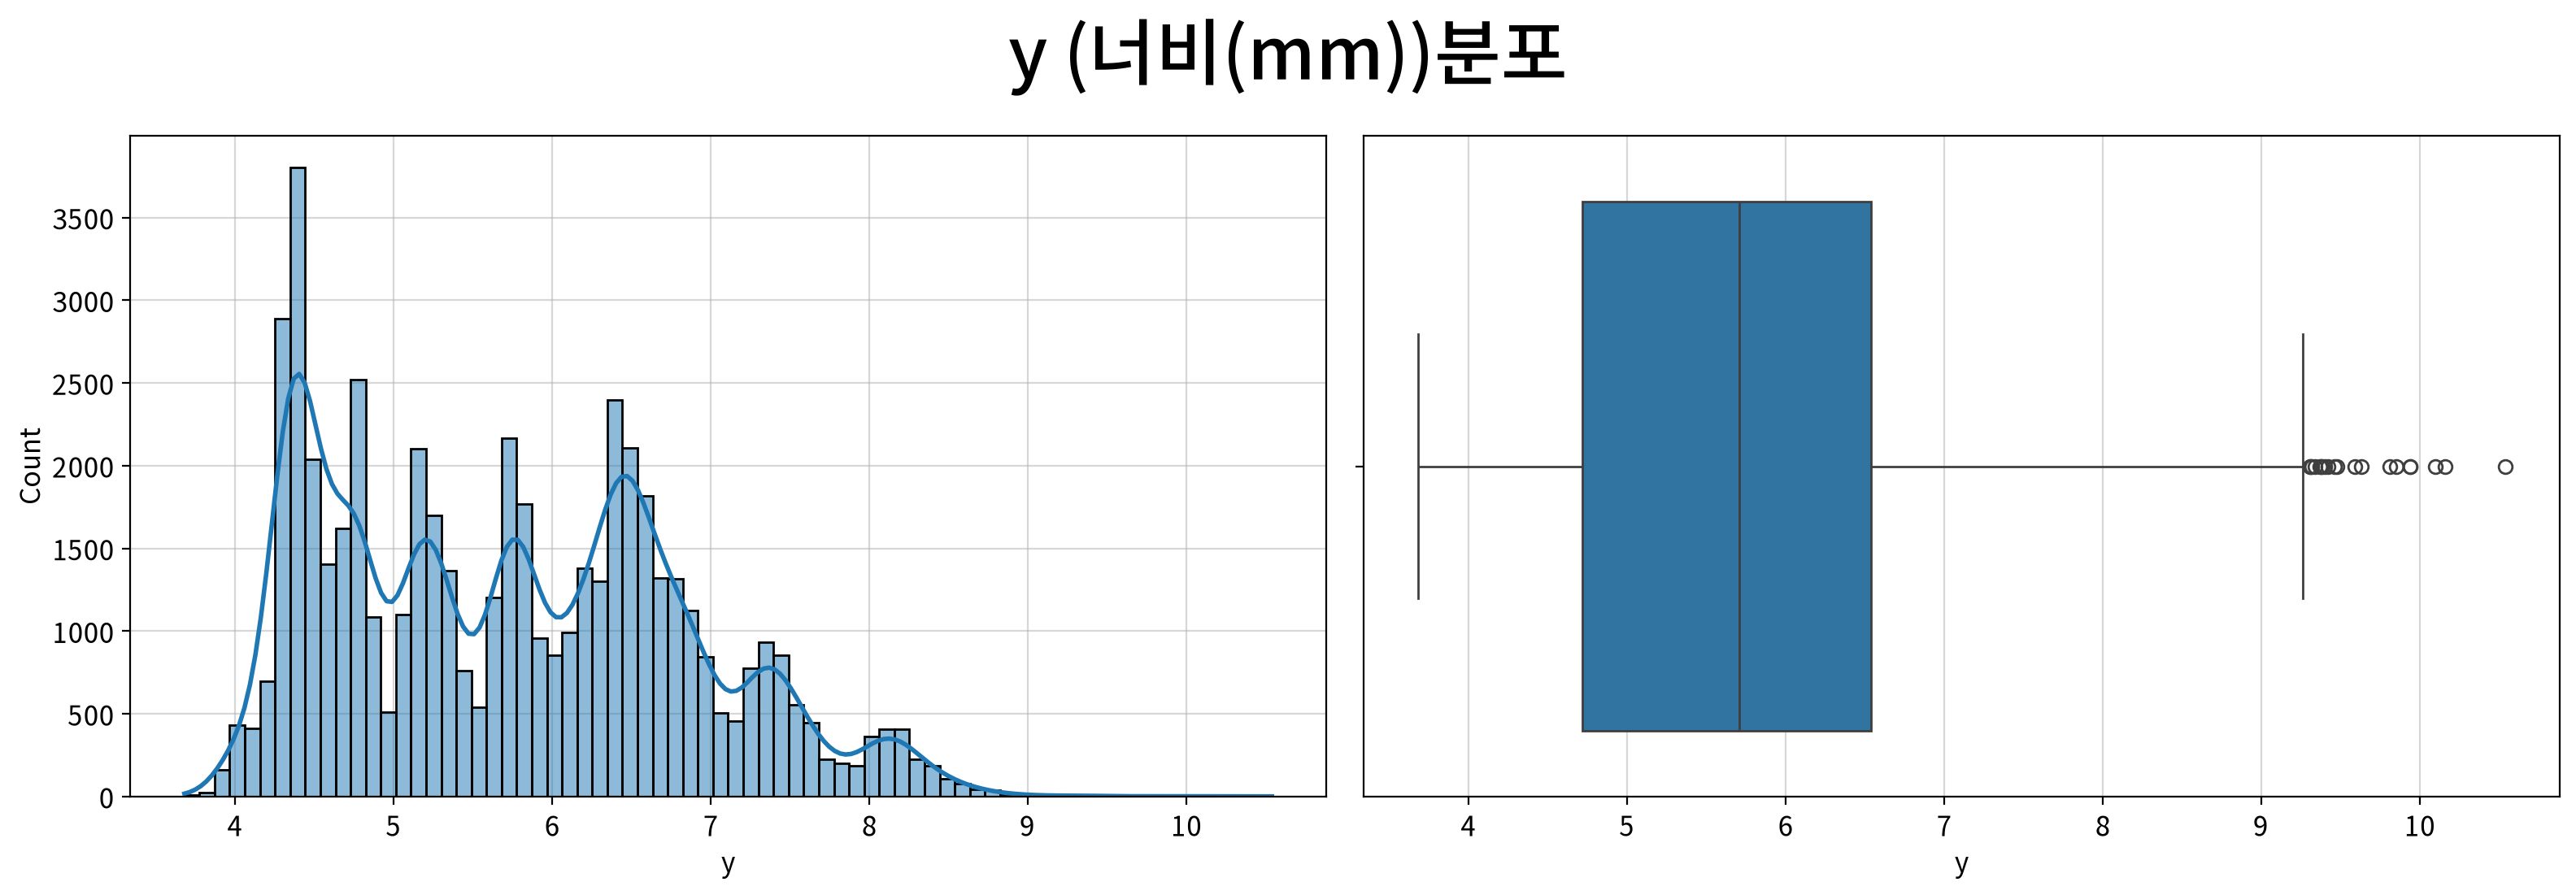

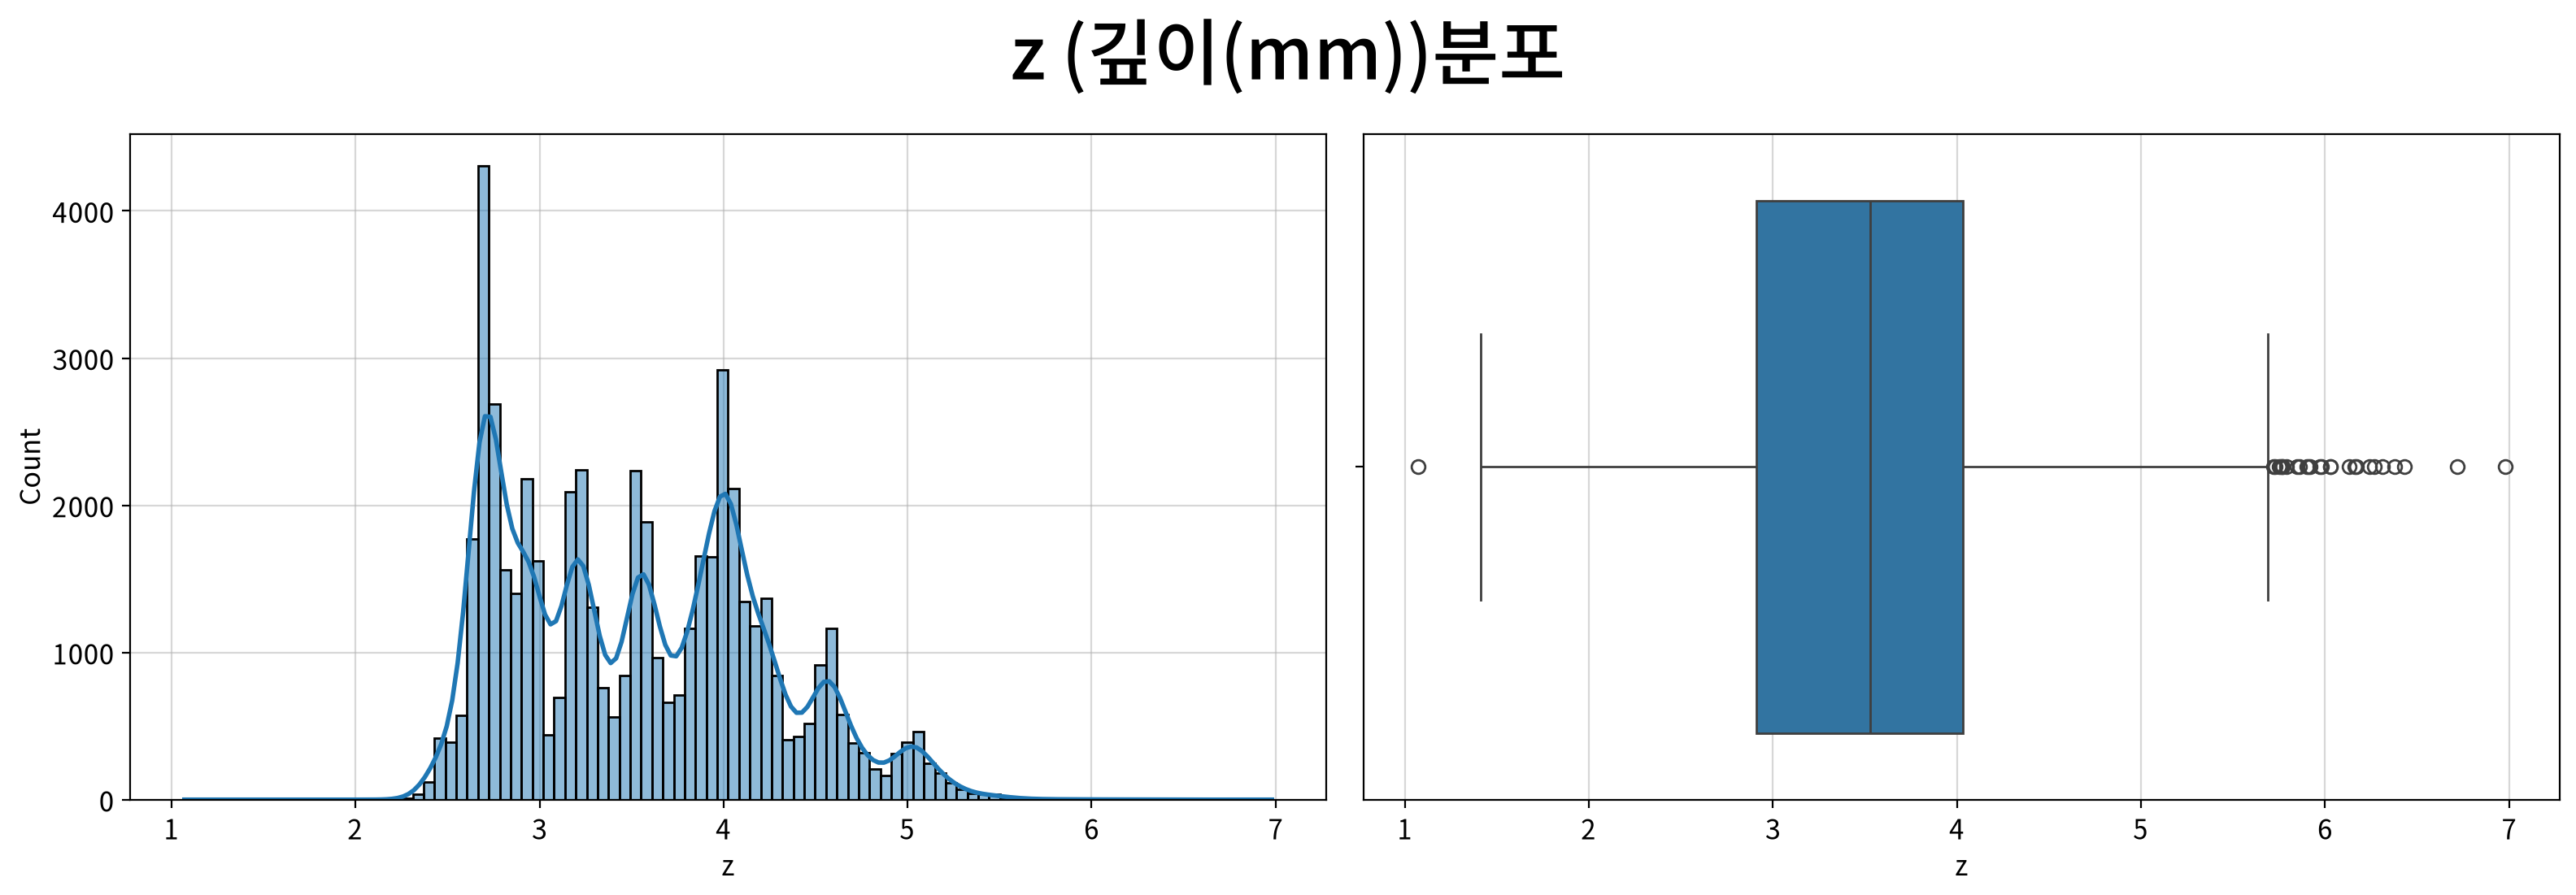

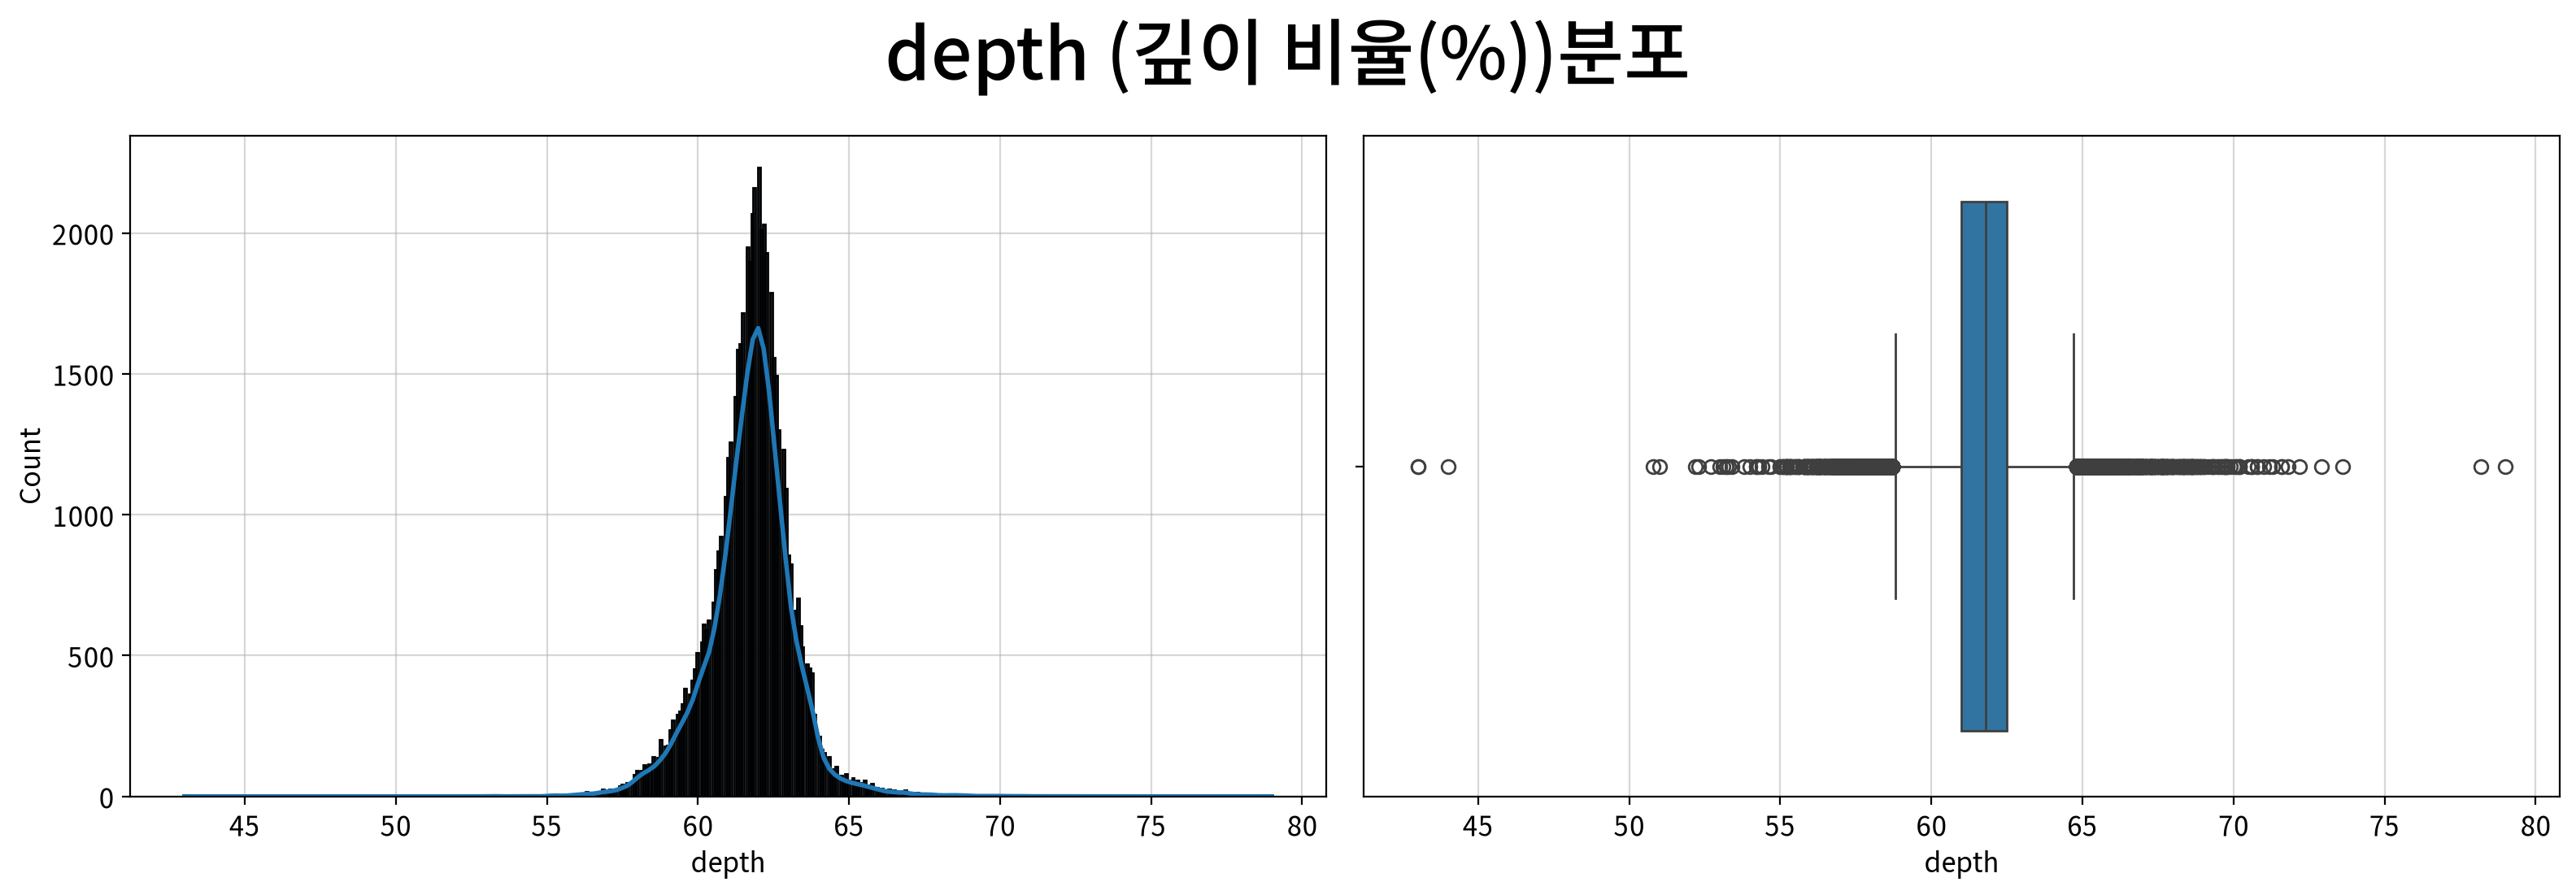

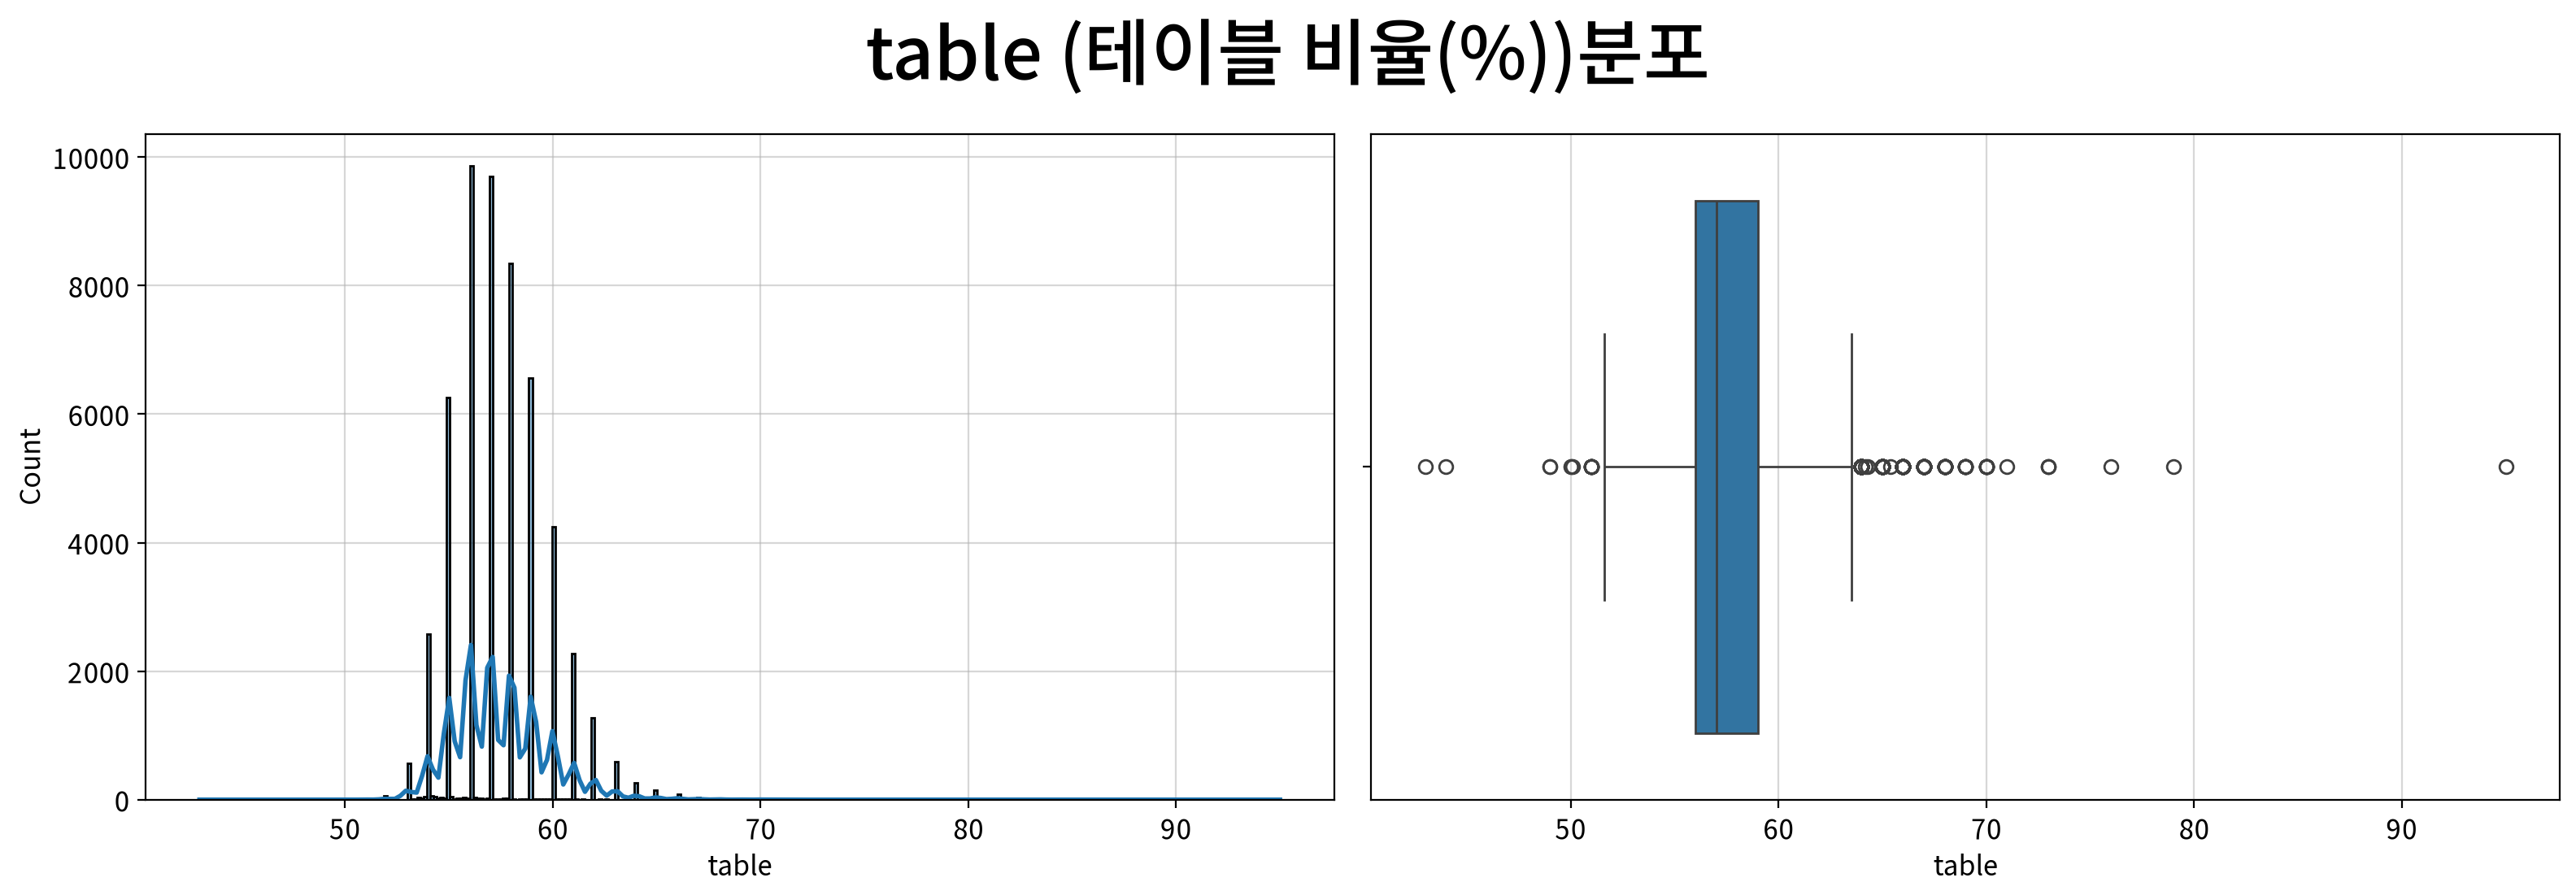

In [12]:
for f in continuous_cols:
    fig, ax = my_plot.init(rows=1, cols=2, width=800, height=560, title=f"{f} ({column_means[f]})분포")
    my_plot.histplot(data=df, x=f, kde=True, ax=ax[0])
    my_plot.boxplot(data=df, x=f, ax=ax[1])
    my_plot.show()

### (3) 명목형 변수 분포

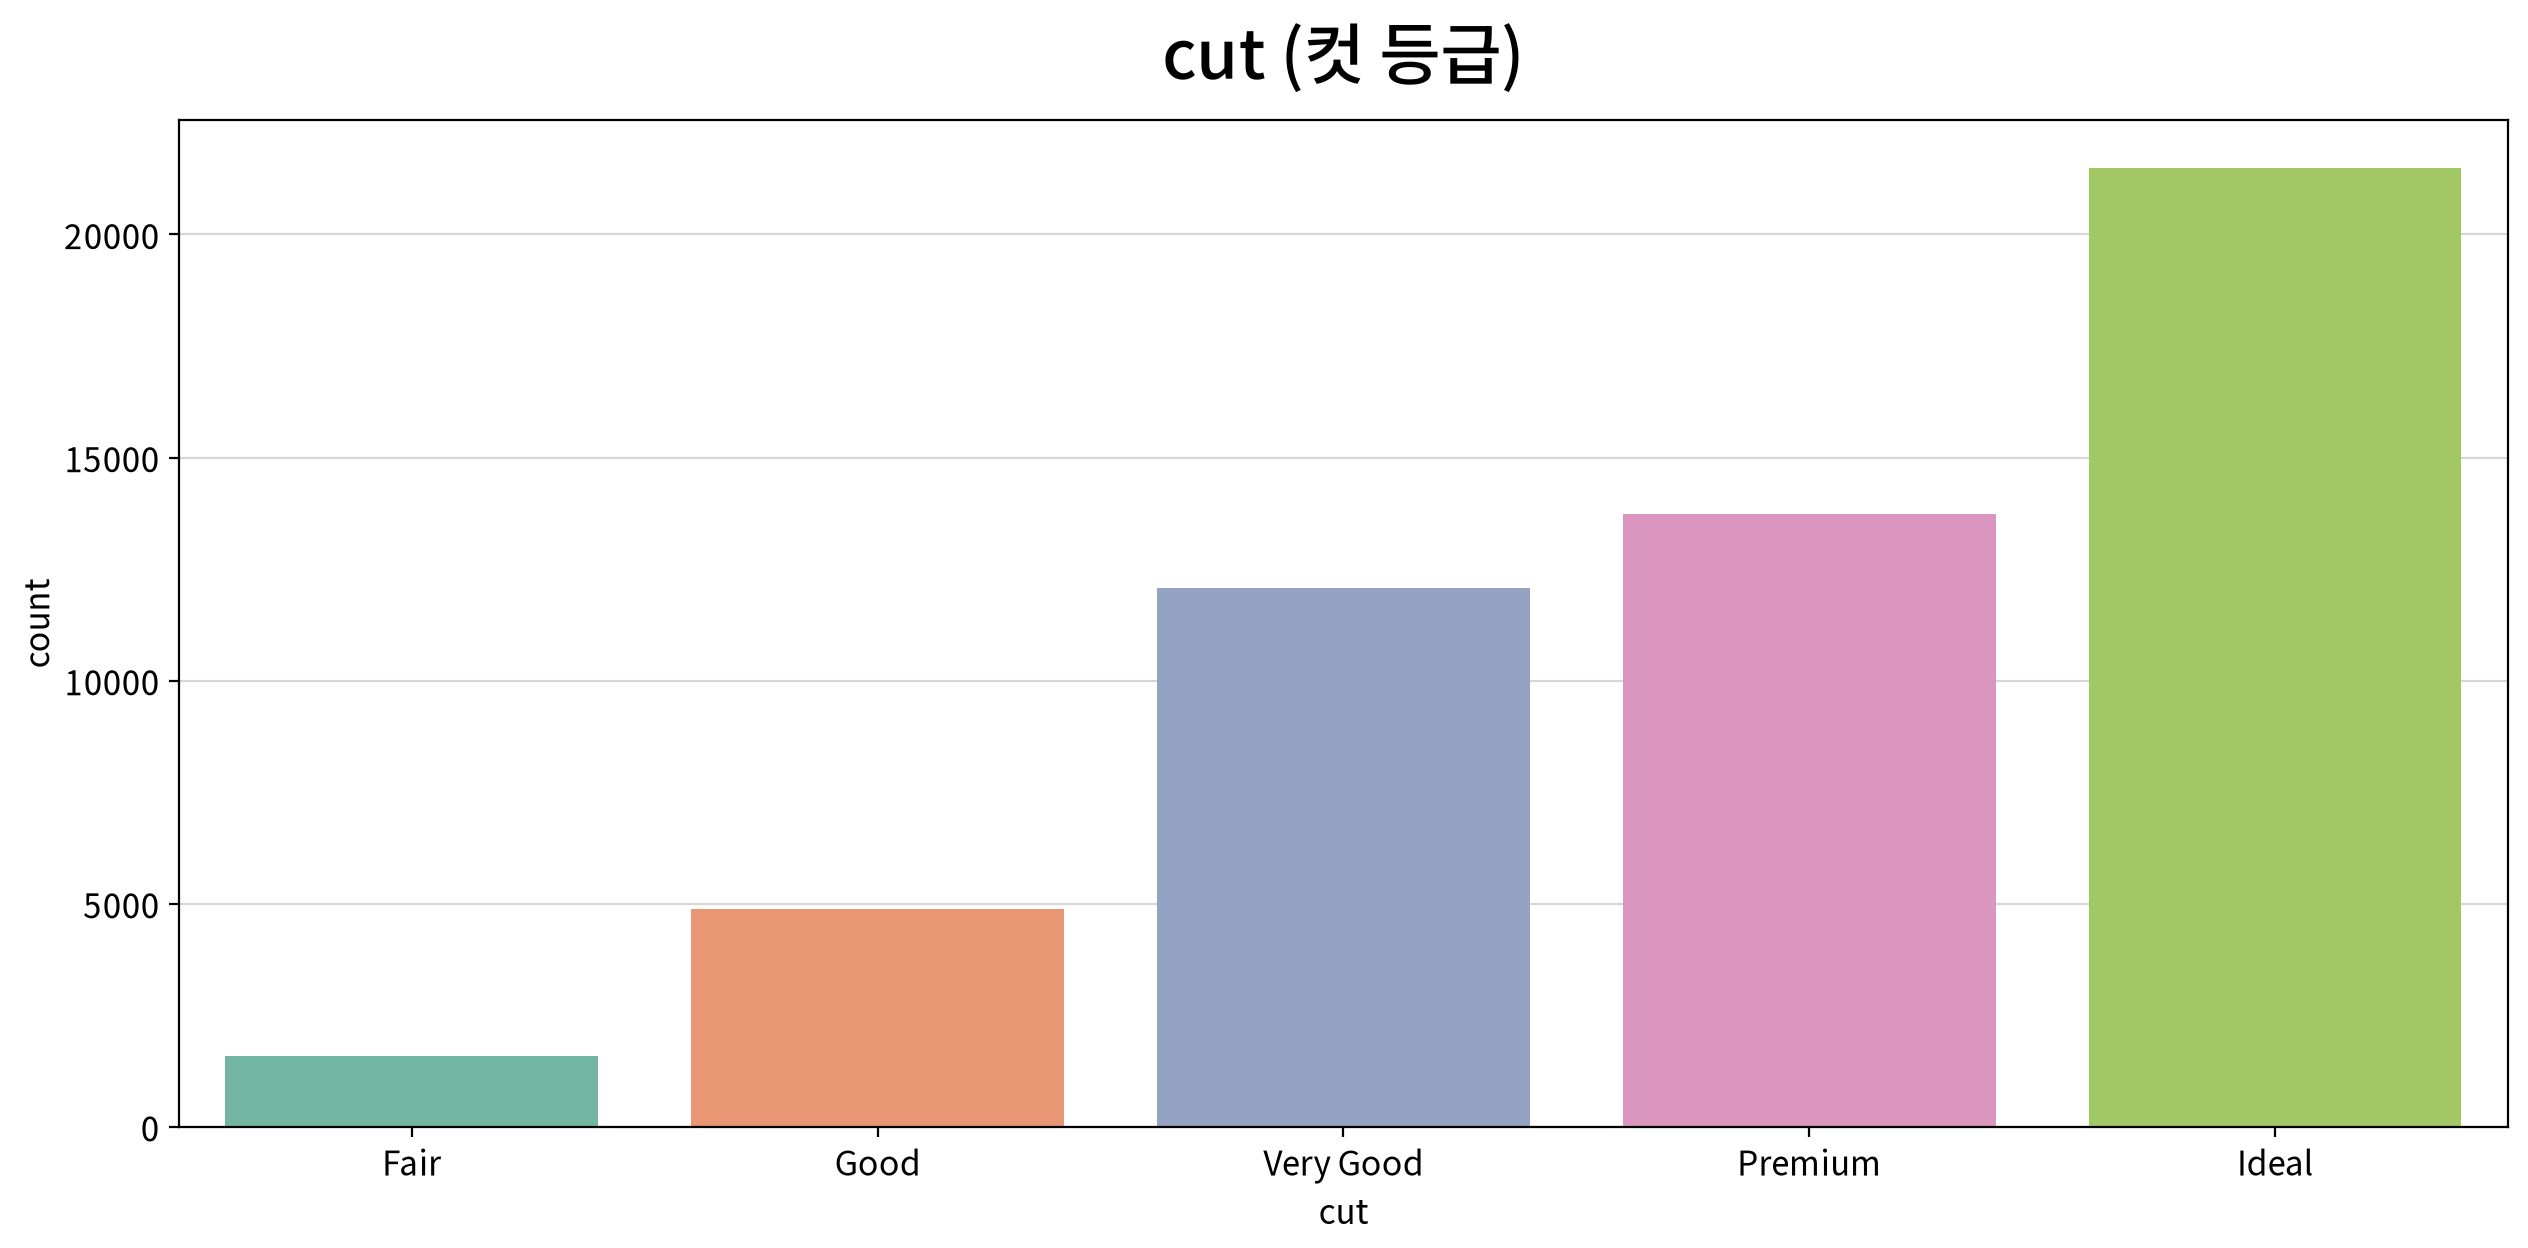

<Figure size 1280x960 with 0 Axes>

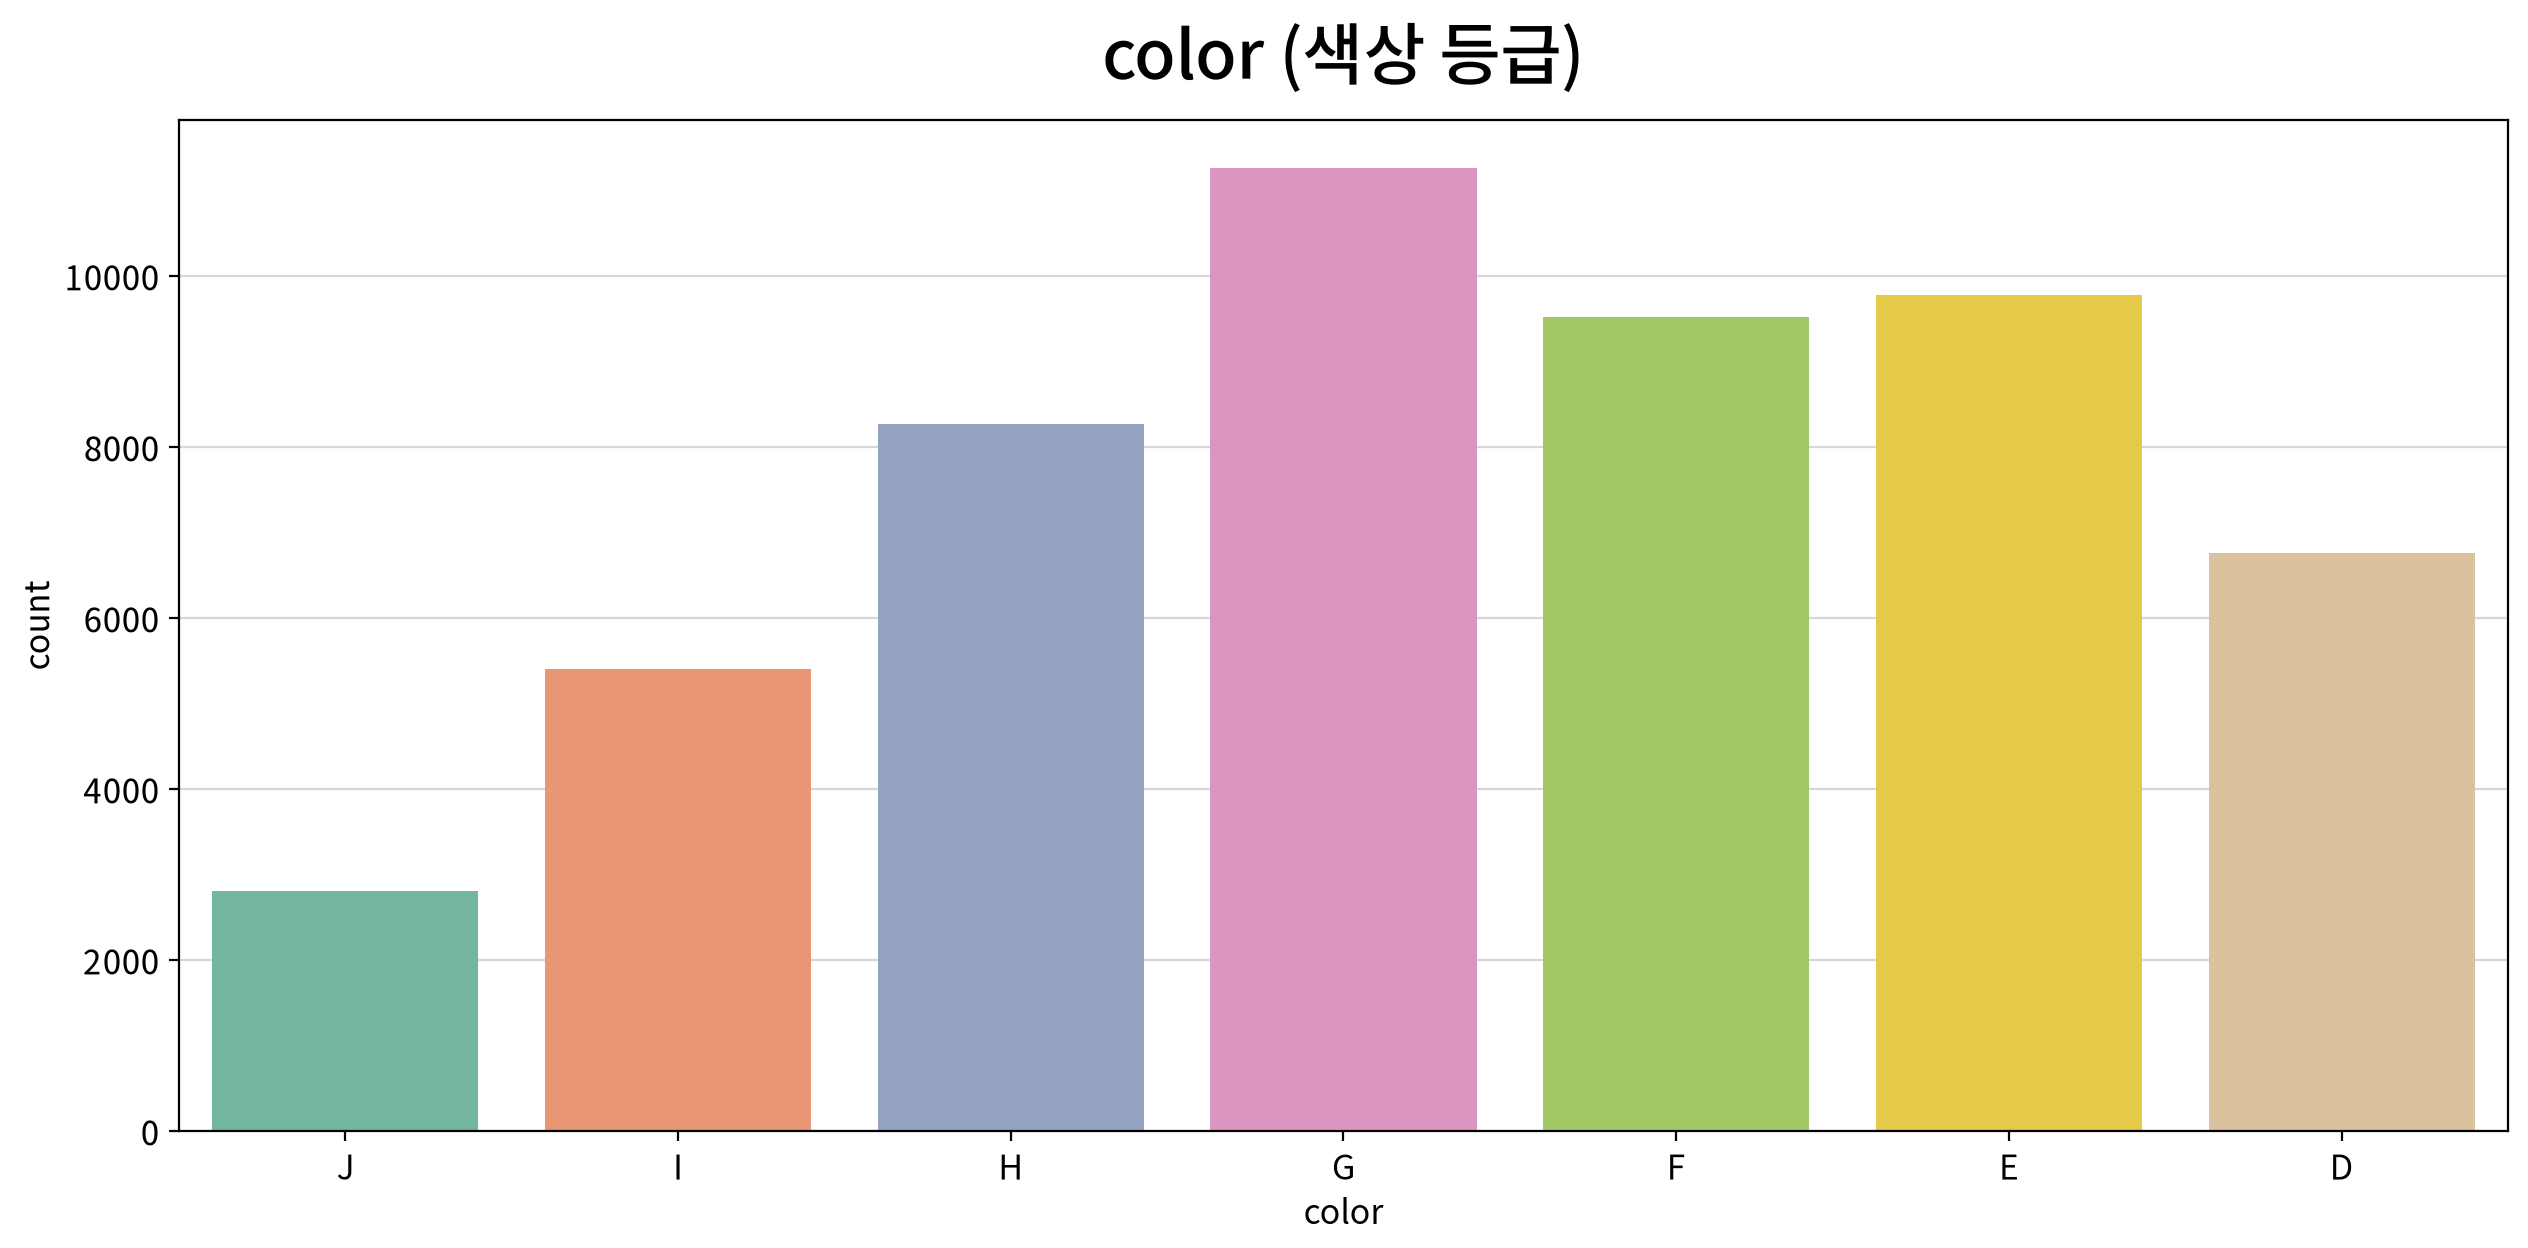

<Figure size 1280x960 with 0 Axes>

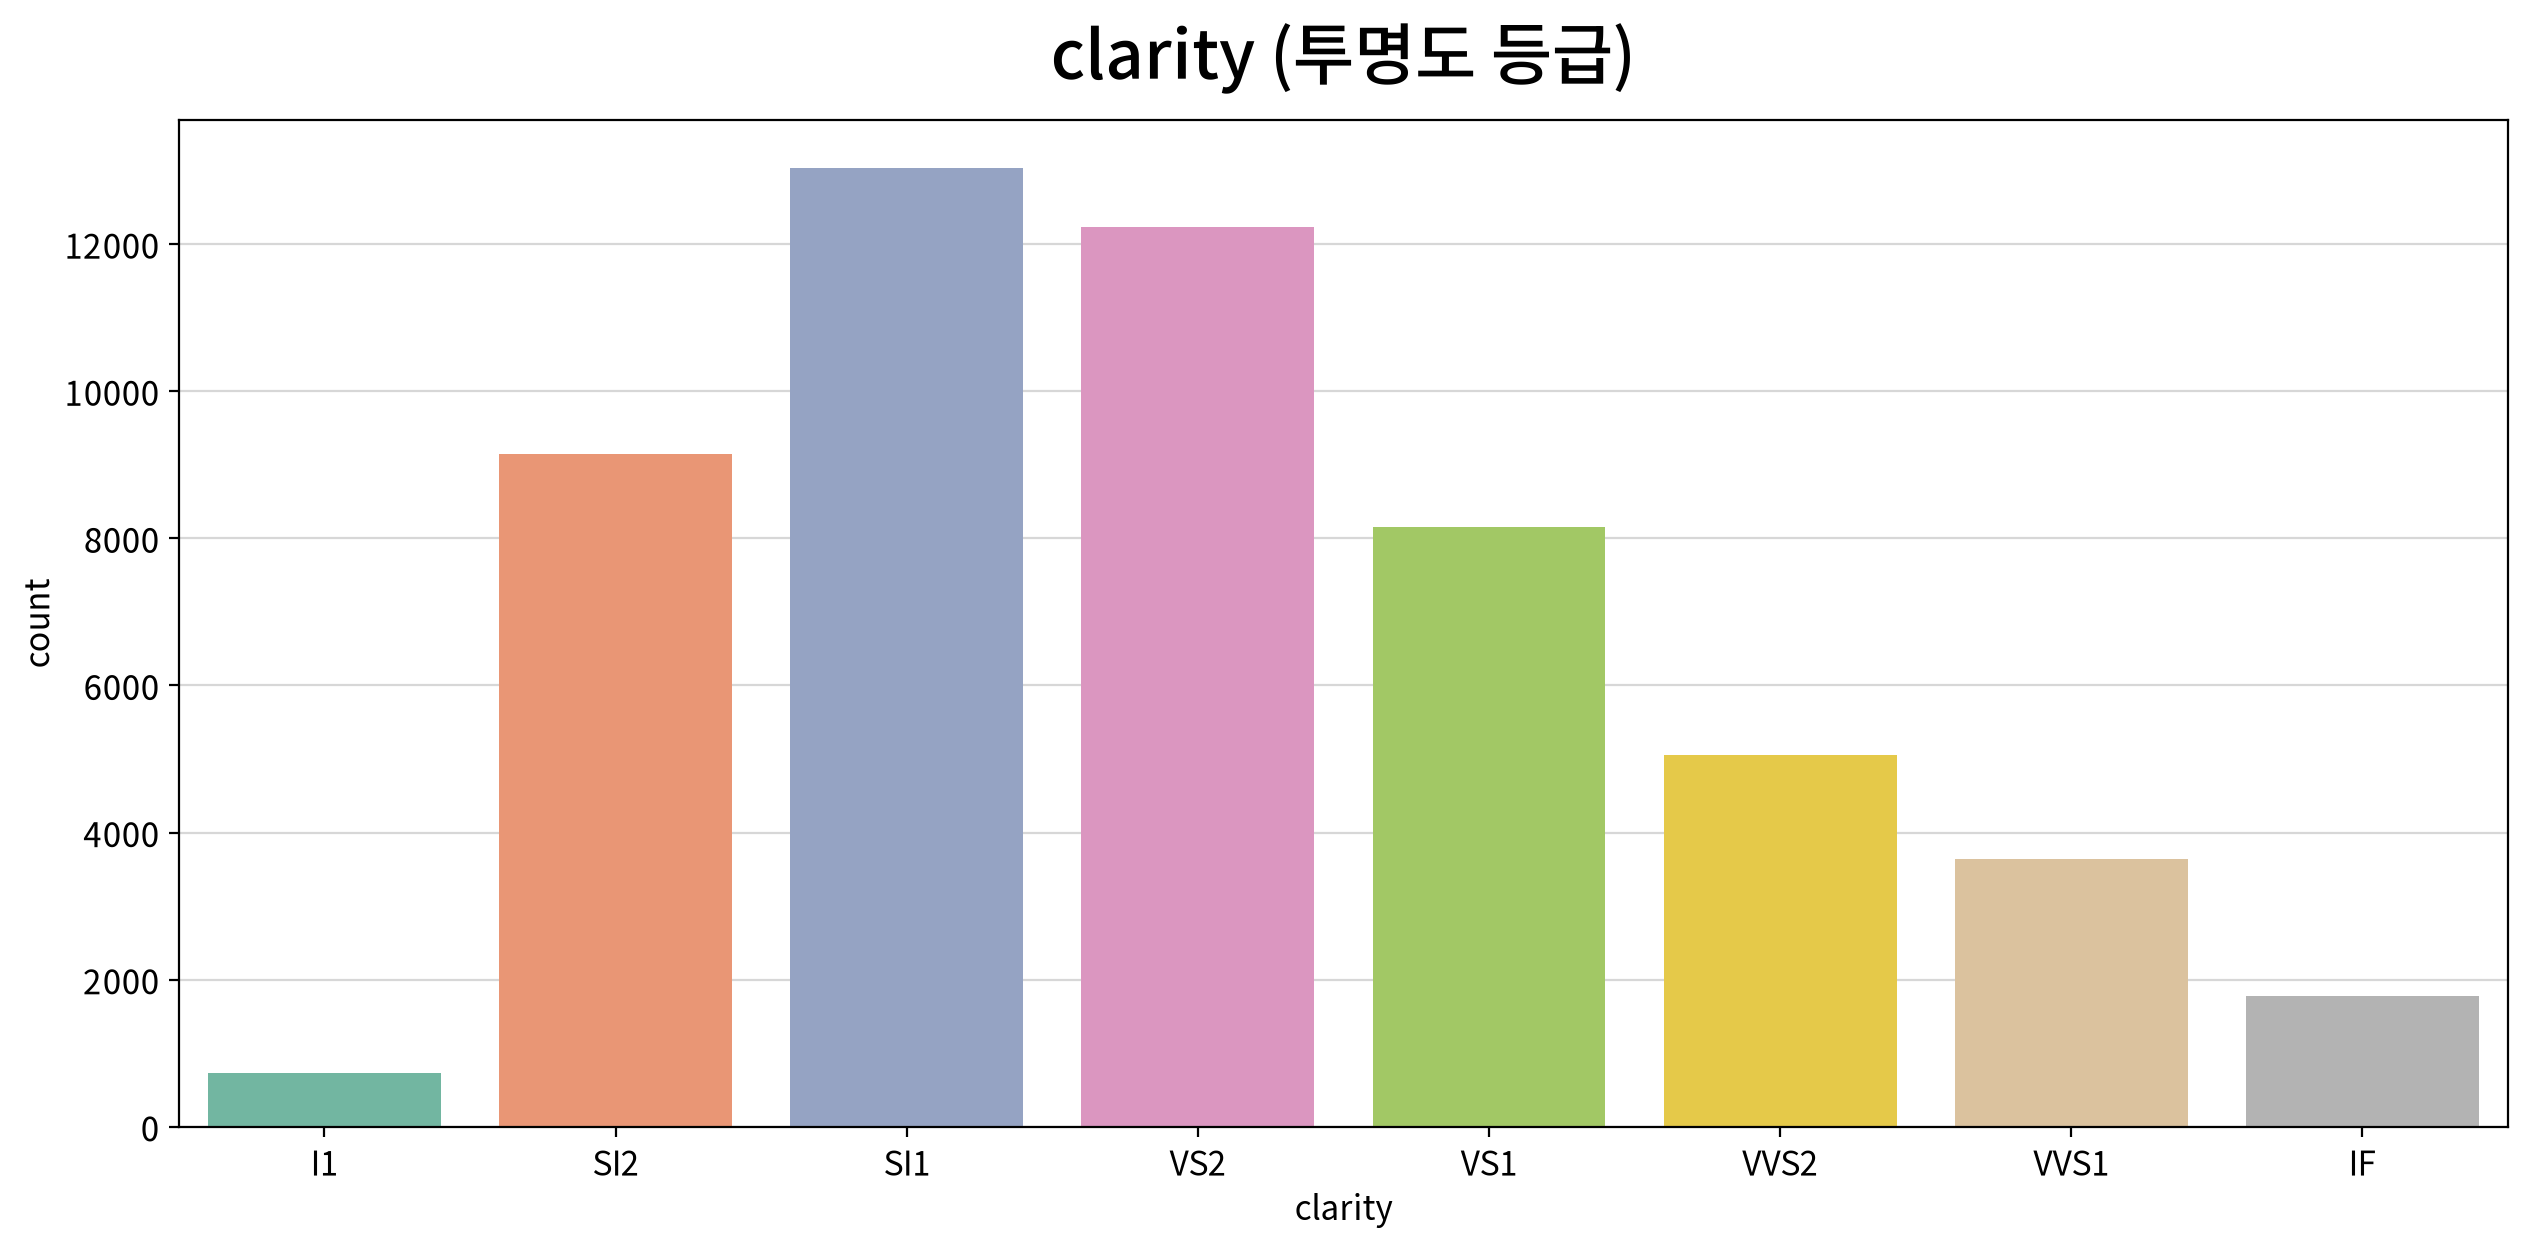

<Figure size 1280x960 with 0 Axes>

In [13]:
for n in nominal_cols:
    my_plot.countplot(data=df, x=n, hue=n, palette="Set2", title=f"{n} ({column_means[n]})")
    my_plot.show()

> 💡 **인사이트 — 단변량**
>
> - `price`는 1,000달러 안팎에 몰린 강한 우편향(왜도 1.62)이다. 소수의 고가품이 평균을 끌어올린다.
> - 그래프와 정제 후 기술통계를 함께 보면, 모델 투입 전에 처리를 검토할 변수는 다음과 같다.
>
> | 변수 | 그래프 모양 | 이상치 비율 | 처리 방향 |
> |---|---|---|---|
> | `price` | 1,000달러 안팎에 몰린 강한 우편향 (왜도 1.62) | 6.5% (상단) | **log** |
> | `carat` | 우편향 + 특정 무게에서 막대가 솟는 모양 (왜도 1.11) | 3.5% (상단) | **log** |
> | `table` | 55~60에 몰리고 오른쪽 꼬리 (왜도 0.79, 첨도 2.78) | 1.1% | **log** |
> | `x` · `y` · `z` | 완만한 봉우리가 여러 개인 분포 (왜도 0.39~0.40) | 0% · 0% · 0.1% | 그대로 (변환 불필요) |
> | `depth` | 61~62에 좁게 몰린 뾰족한 분포 (왜도 −0.11, 첨도 5.42) | 4.7% (양쪽) | 그대로 (변환 불필요) |
>
> - `carat` 히스토그램은 매끄럽지 않고 **특정 무게에서 막대가 솟는** 모양이다. 판매자가 '1캐럿'처럼 기준이 되는 무게에 맞춰 원석을 깎는 시장 관행의 흔적일 수 있다.
> - `y` · `z`는 log1p 판정을 받았지만, 오류값을 지운 뒤에는 대칭에 가까워져 **변환이 필요 없어졌다.**
> - `price`의 상단 이상치는 입력 오류가 아니라 **큰 원석**이라 제거하지 않는다.
> - 등급은 고르지 않다.
>   - `cut` : Ideal이 40.0%로 가장 많고 Fair는 3.0%
>   - `color` : G가 20.9%로 가장 많고, 가장 낮은 등급인 **J는 5.2%뿐**이다
>   - `clarity` : SI1이 24.2%로 가장 많고, 가장 낮은 등급인 I1은 1.4%뿐이다

## 2-2. 이변량 분석 — 각 독립변수가 가격을 설명하는가?

### (1) 연속형 × 가격 : 상관분석

- 정규성 · 선형성 · 영향점을 점검해 **Pearson / Spearman을 자동 선택**한다.
- 채택 기준 : **유의(p < 0.05) + 상관강도 Moderate 이상(|ρ| ≥ 0.3)**

#### ▶︎ carat(중량) → price

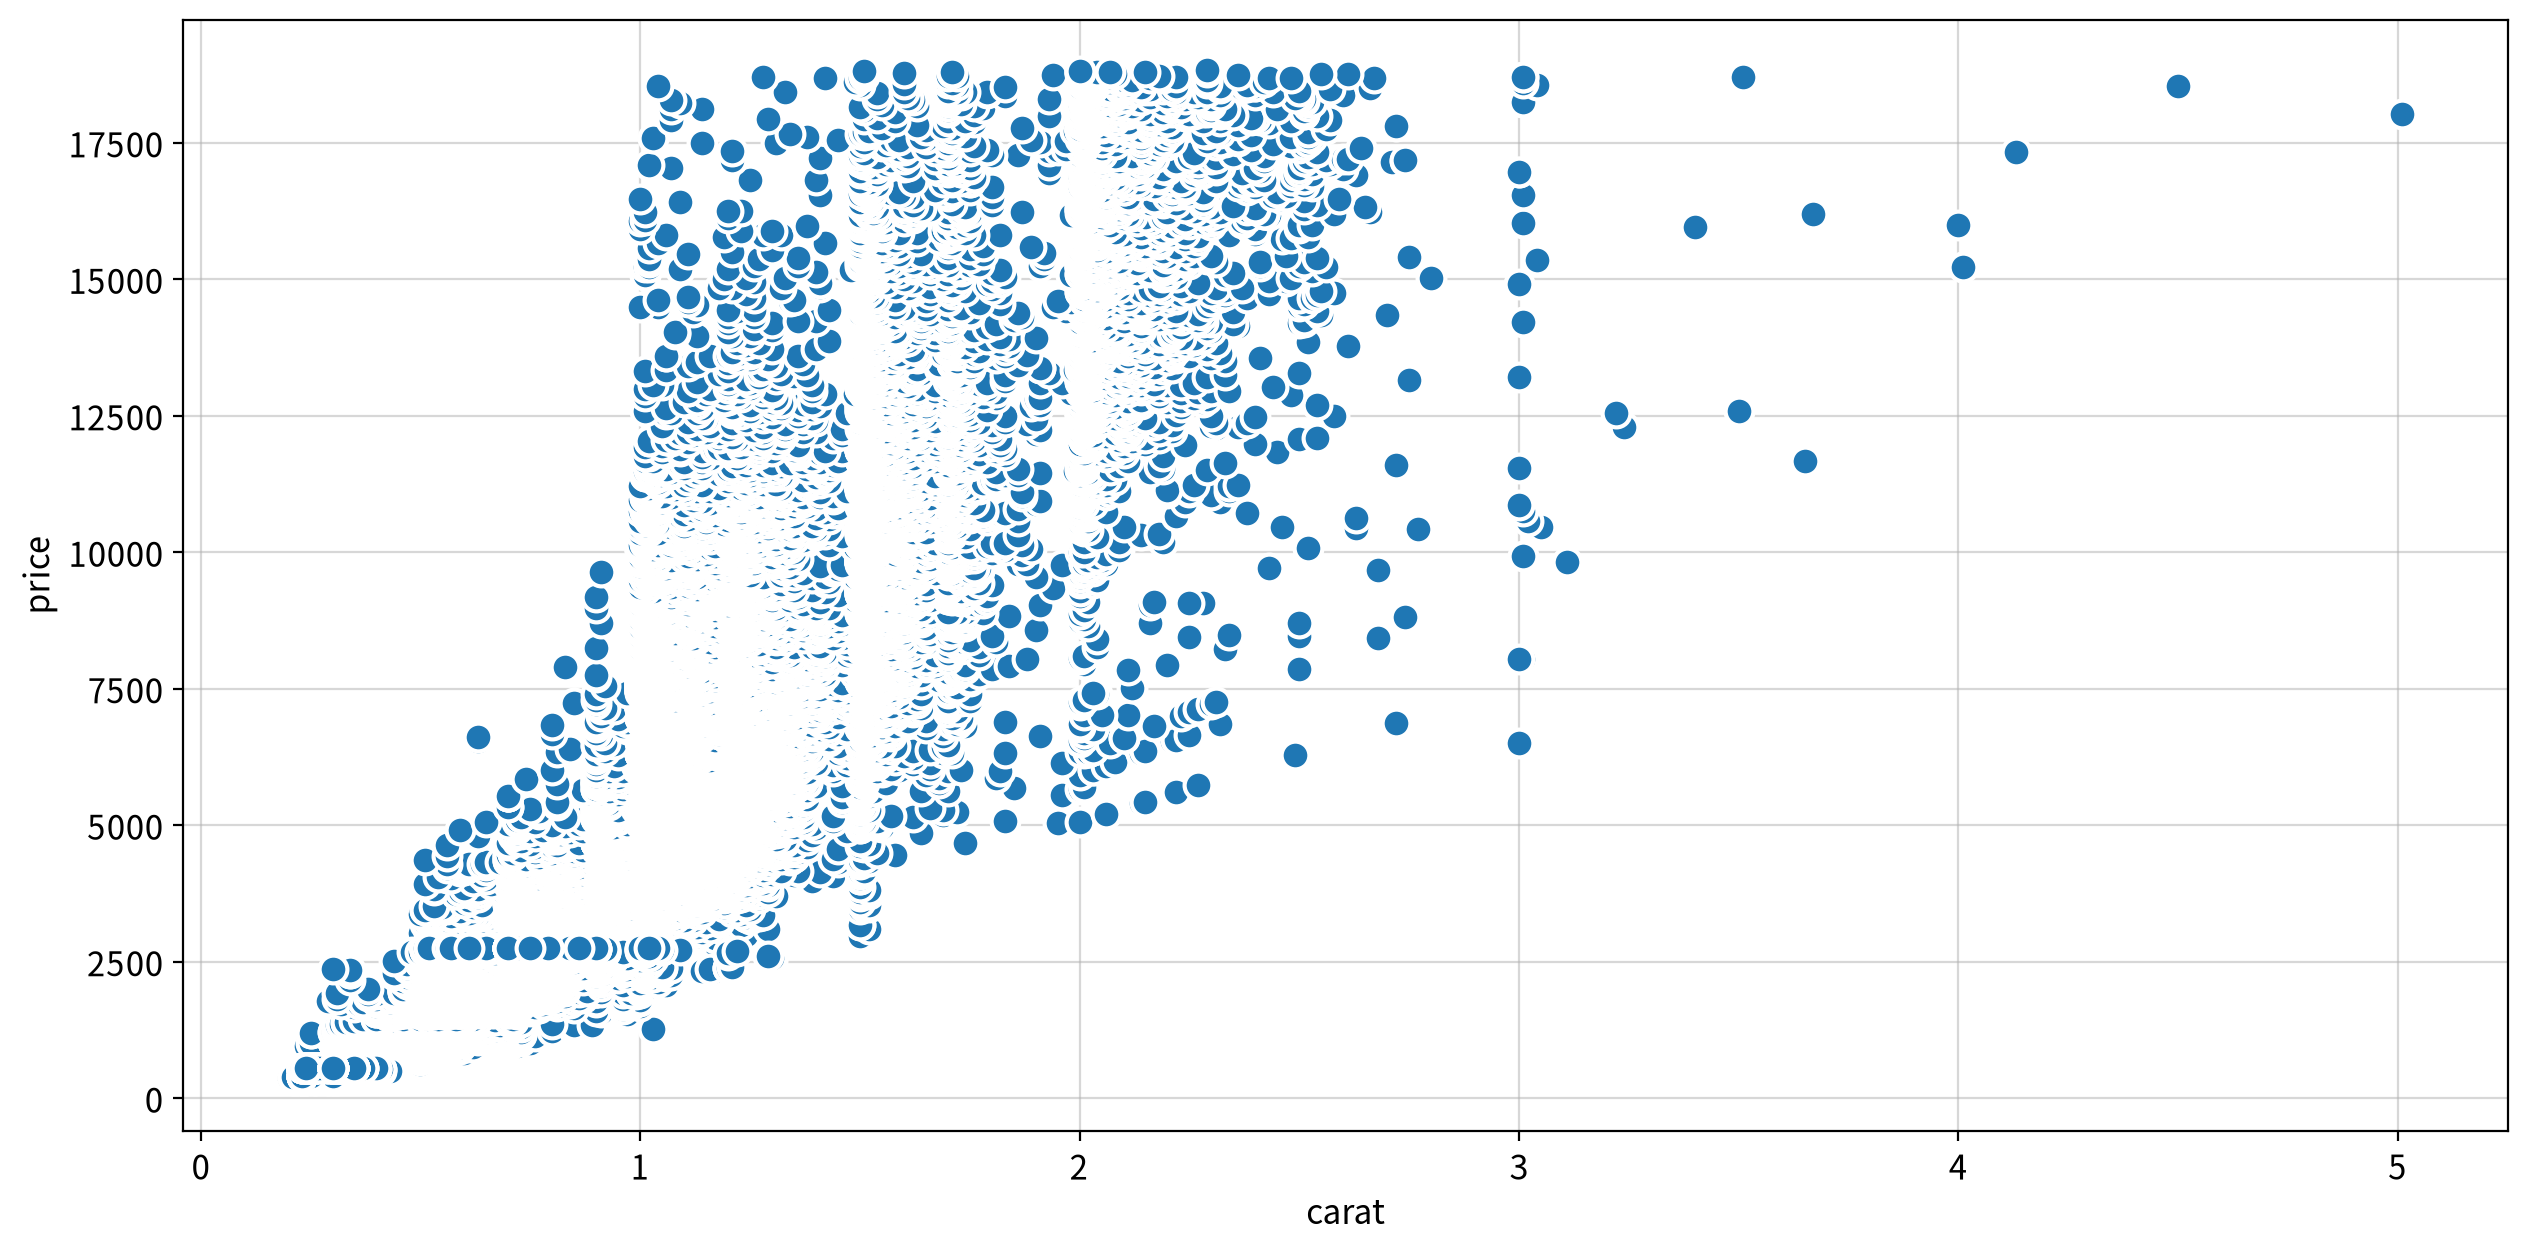

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
carat,price,Spearman,0.963,0.000,Strong,True,False,False,False,False,True


#### ▶︎ x(길이(mm)) → price

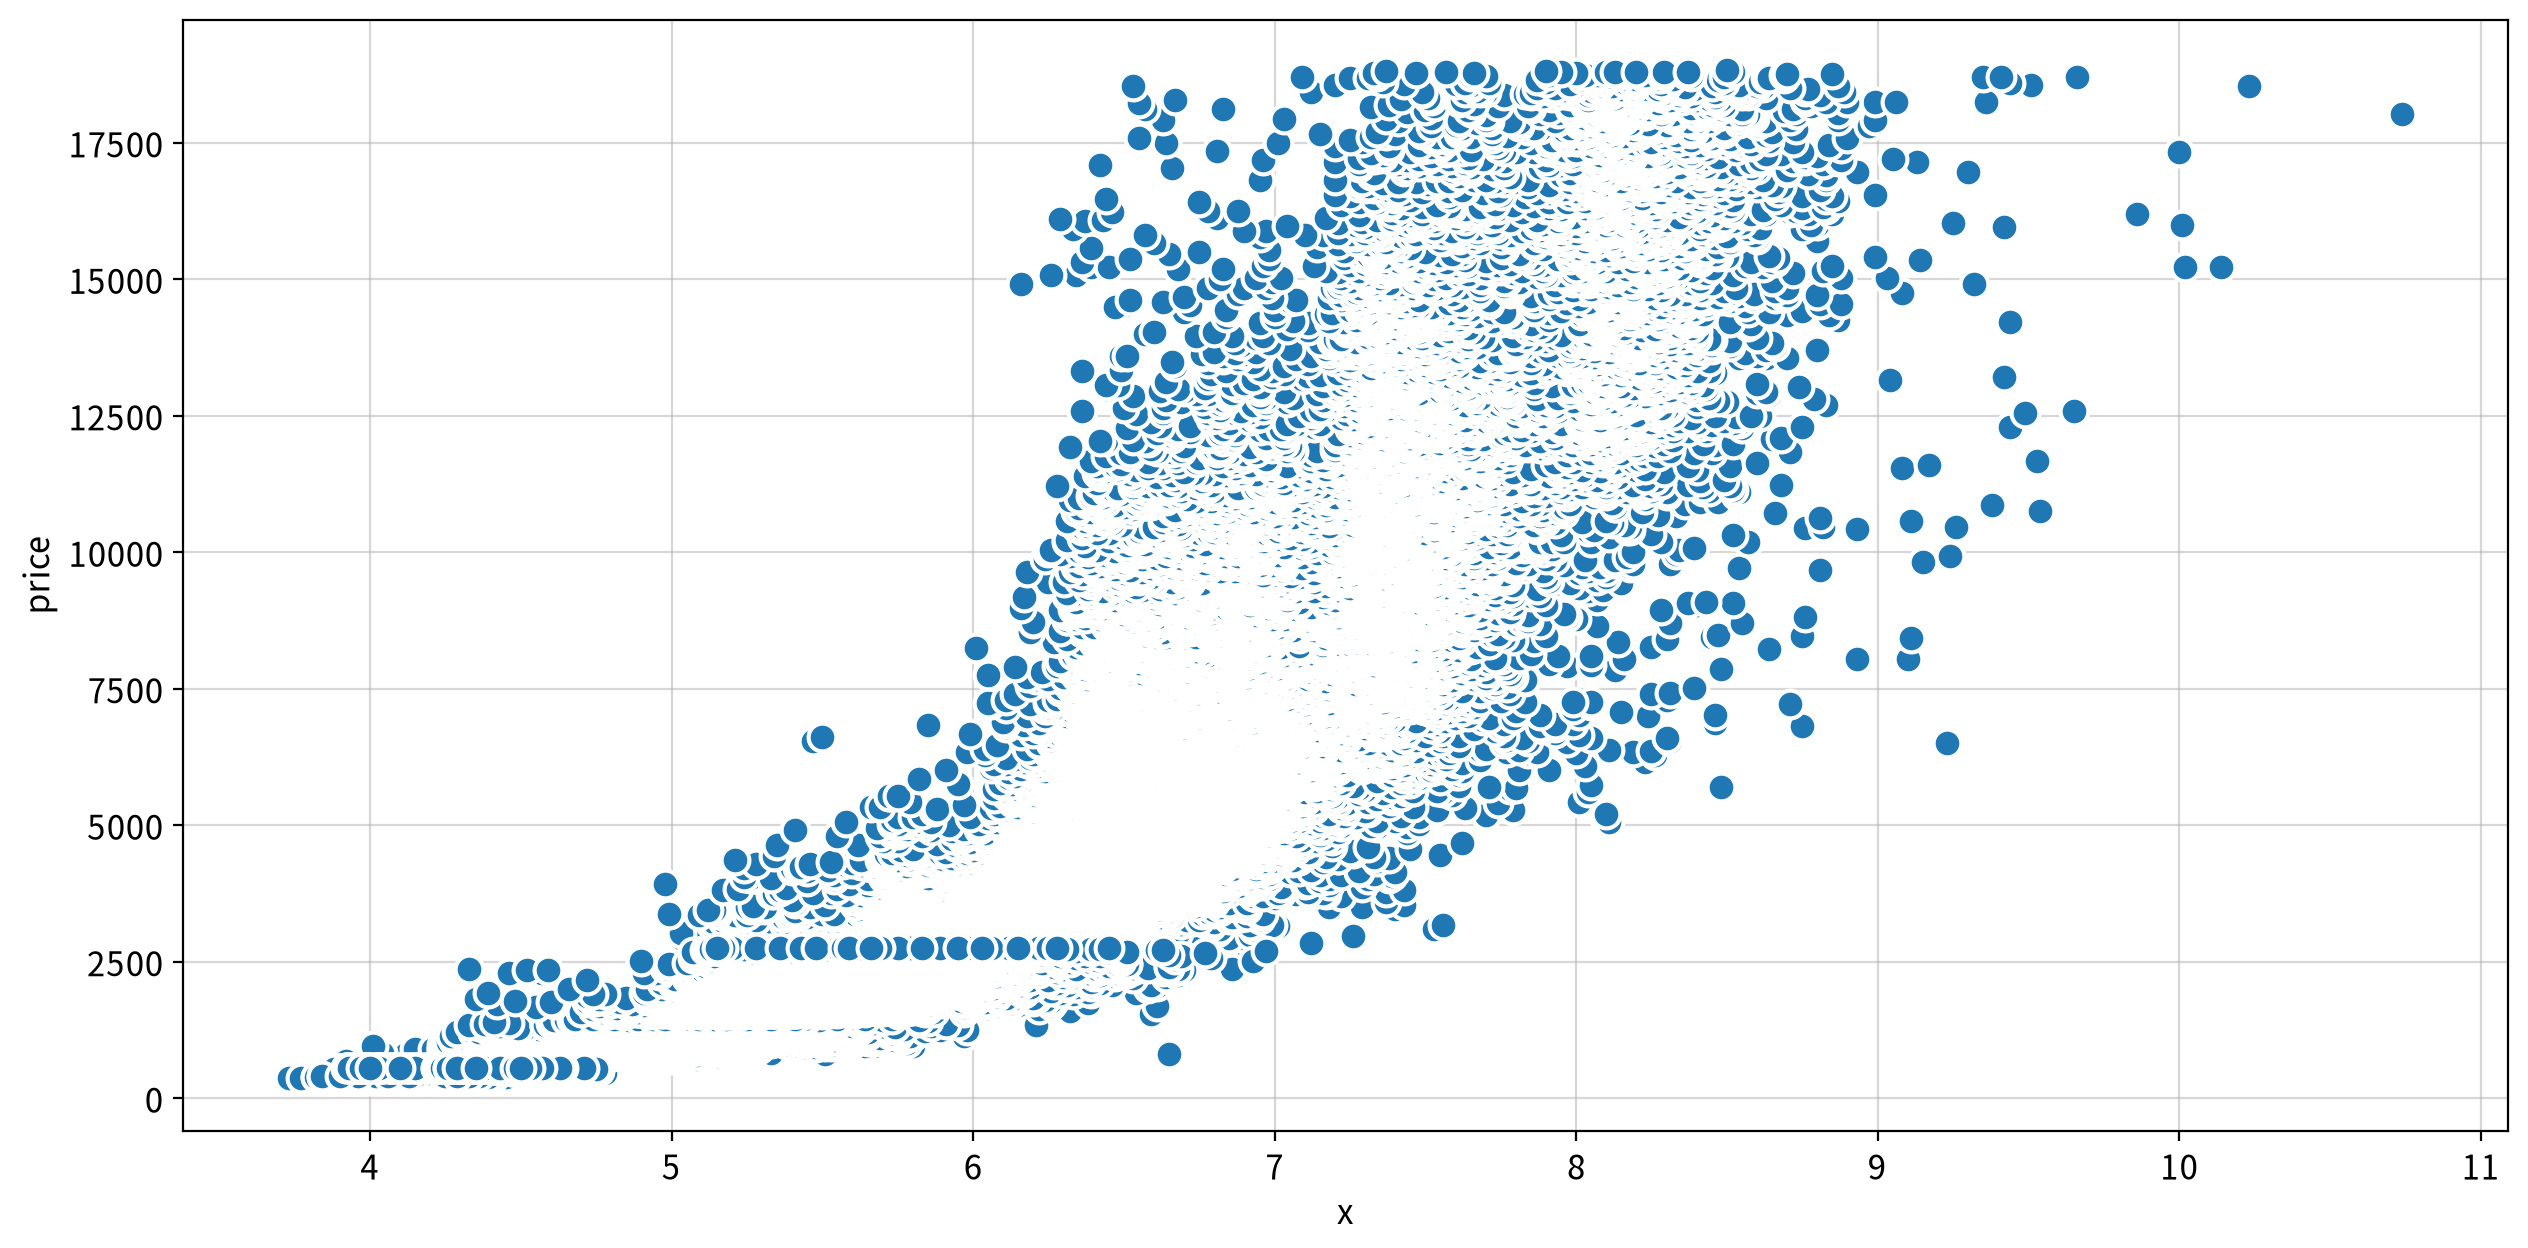

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
x,price,Spearman,0.964,0.000,Strong,True,False,False,False,False,True


#### ▶︎ y(너비(mm)) → price

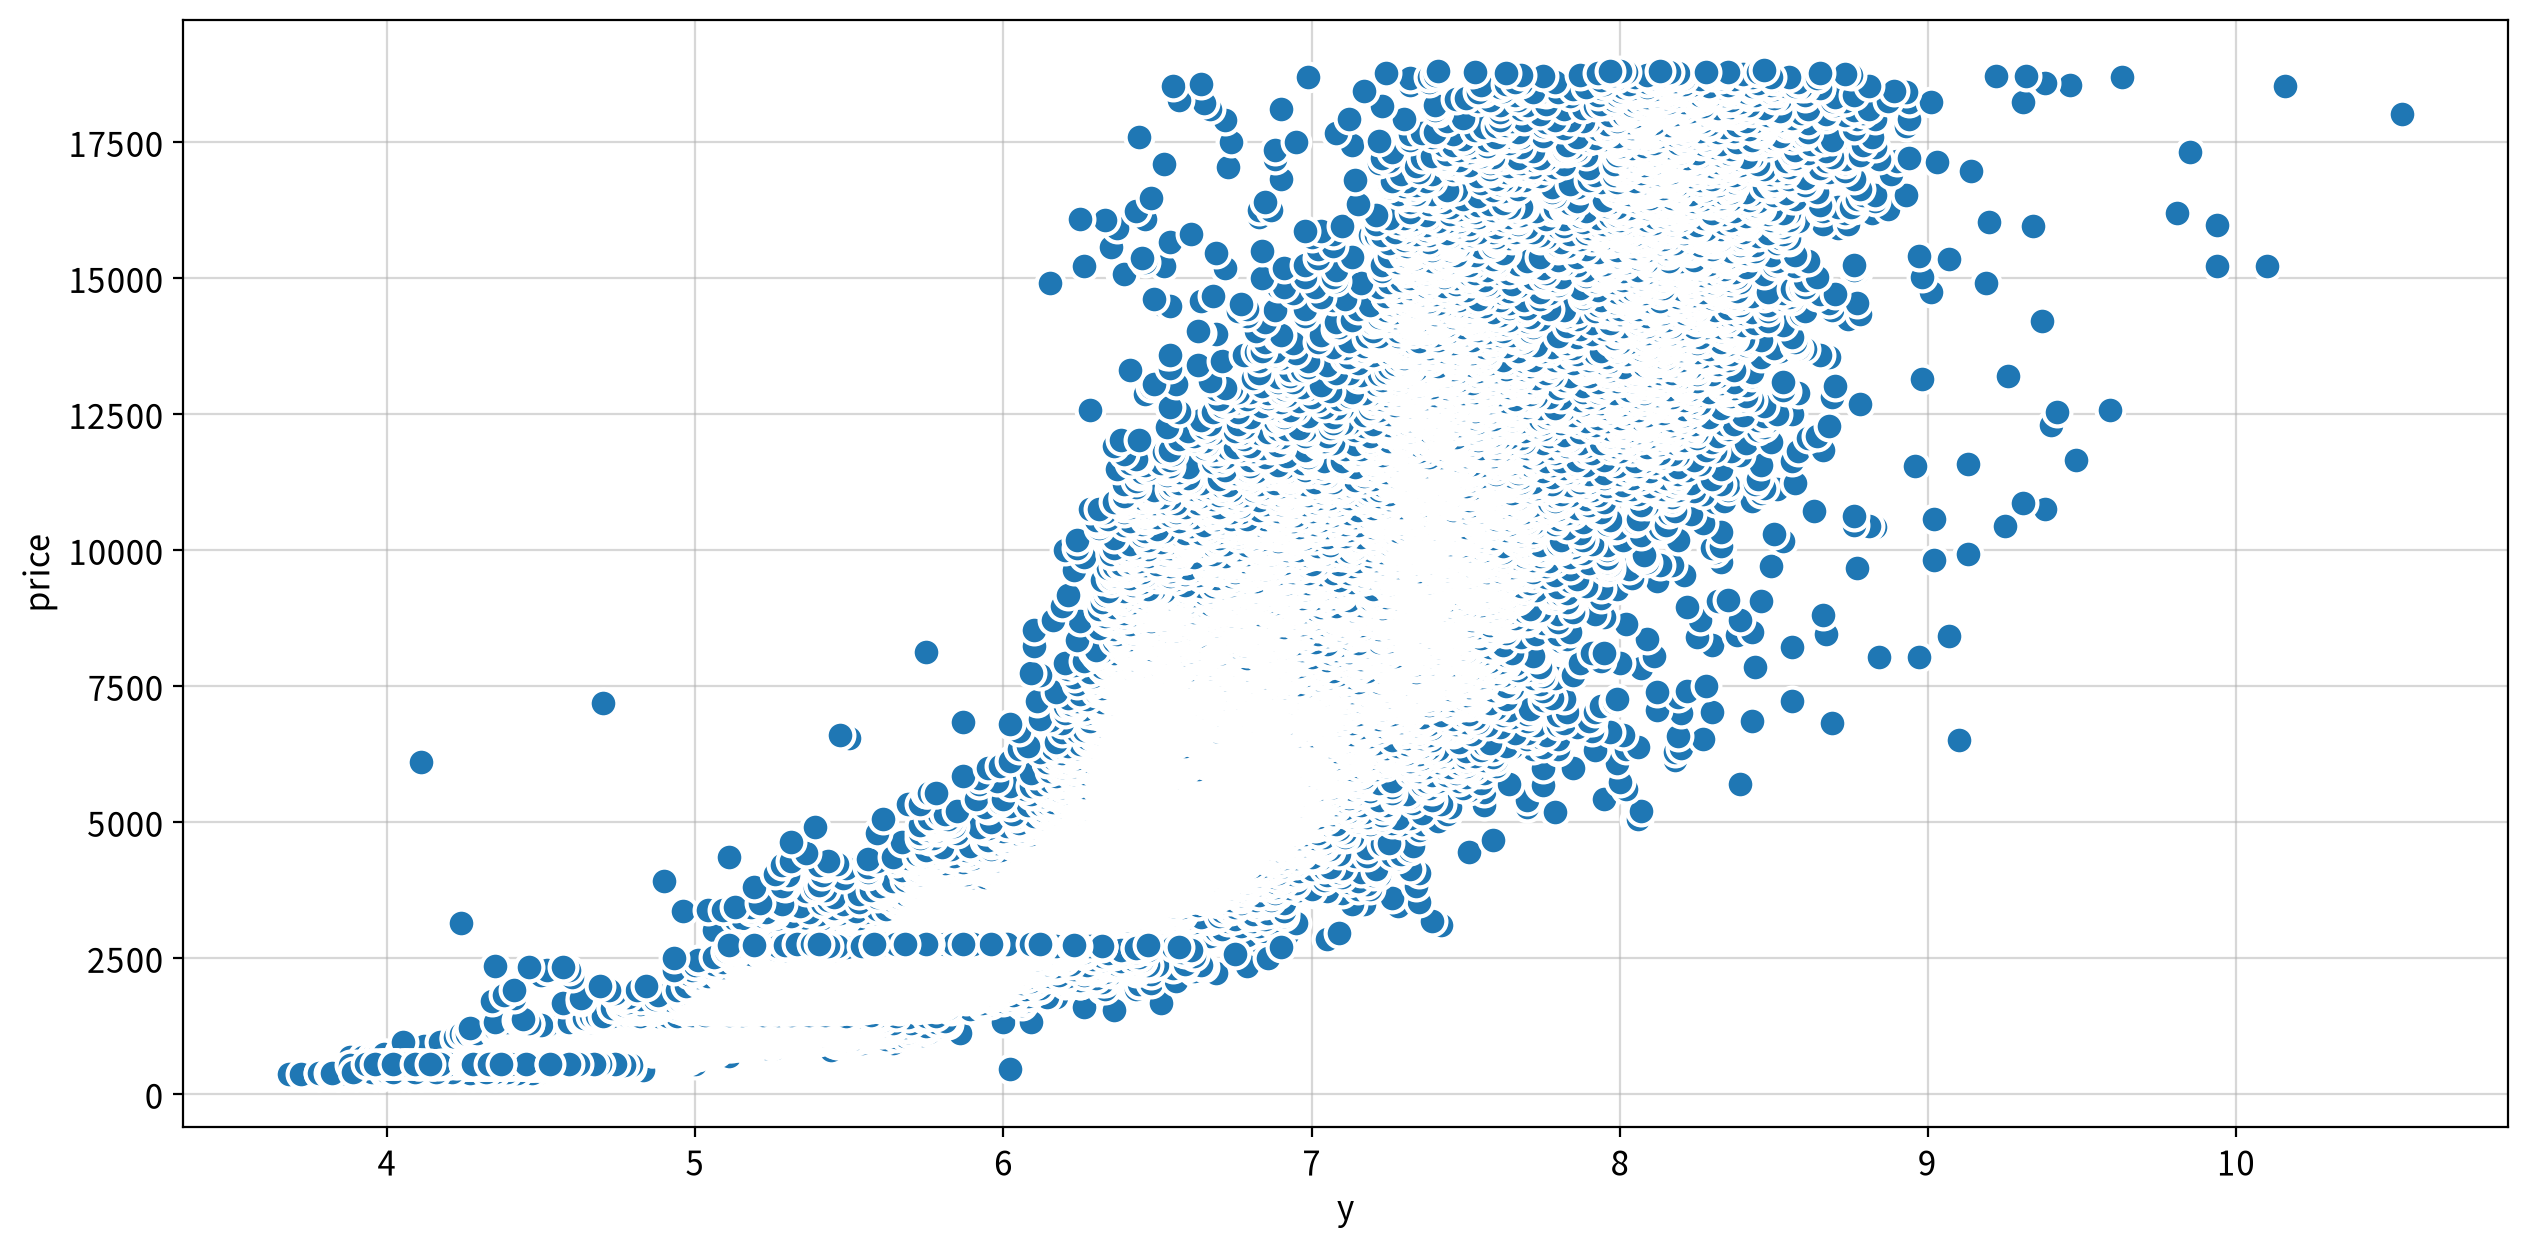

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
y,price,Spearman,0.963,0.000,Strong,True,False,False,False,False,True


#### ▶︎ z(깊이(mm)) → price

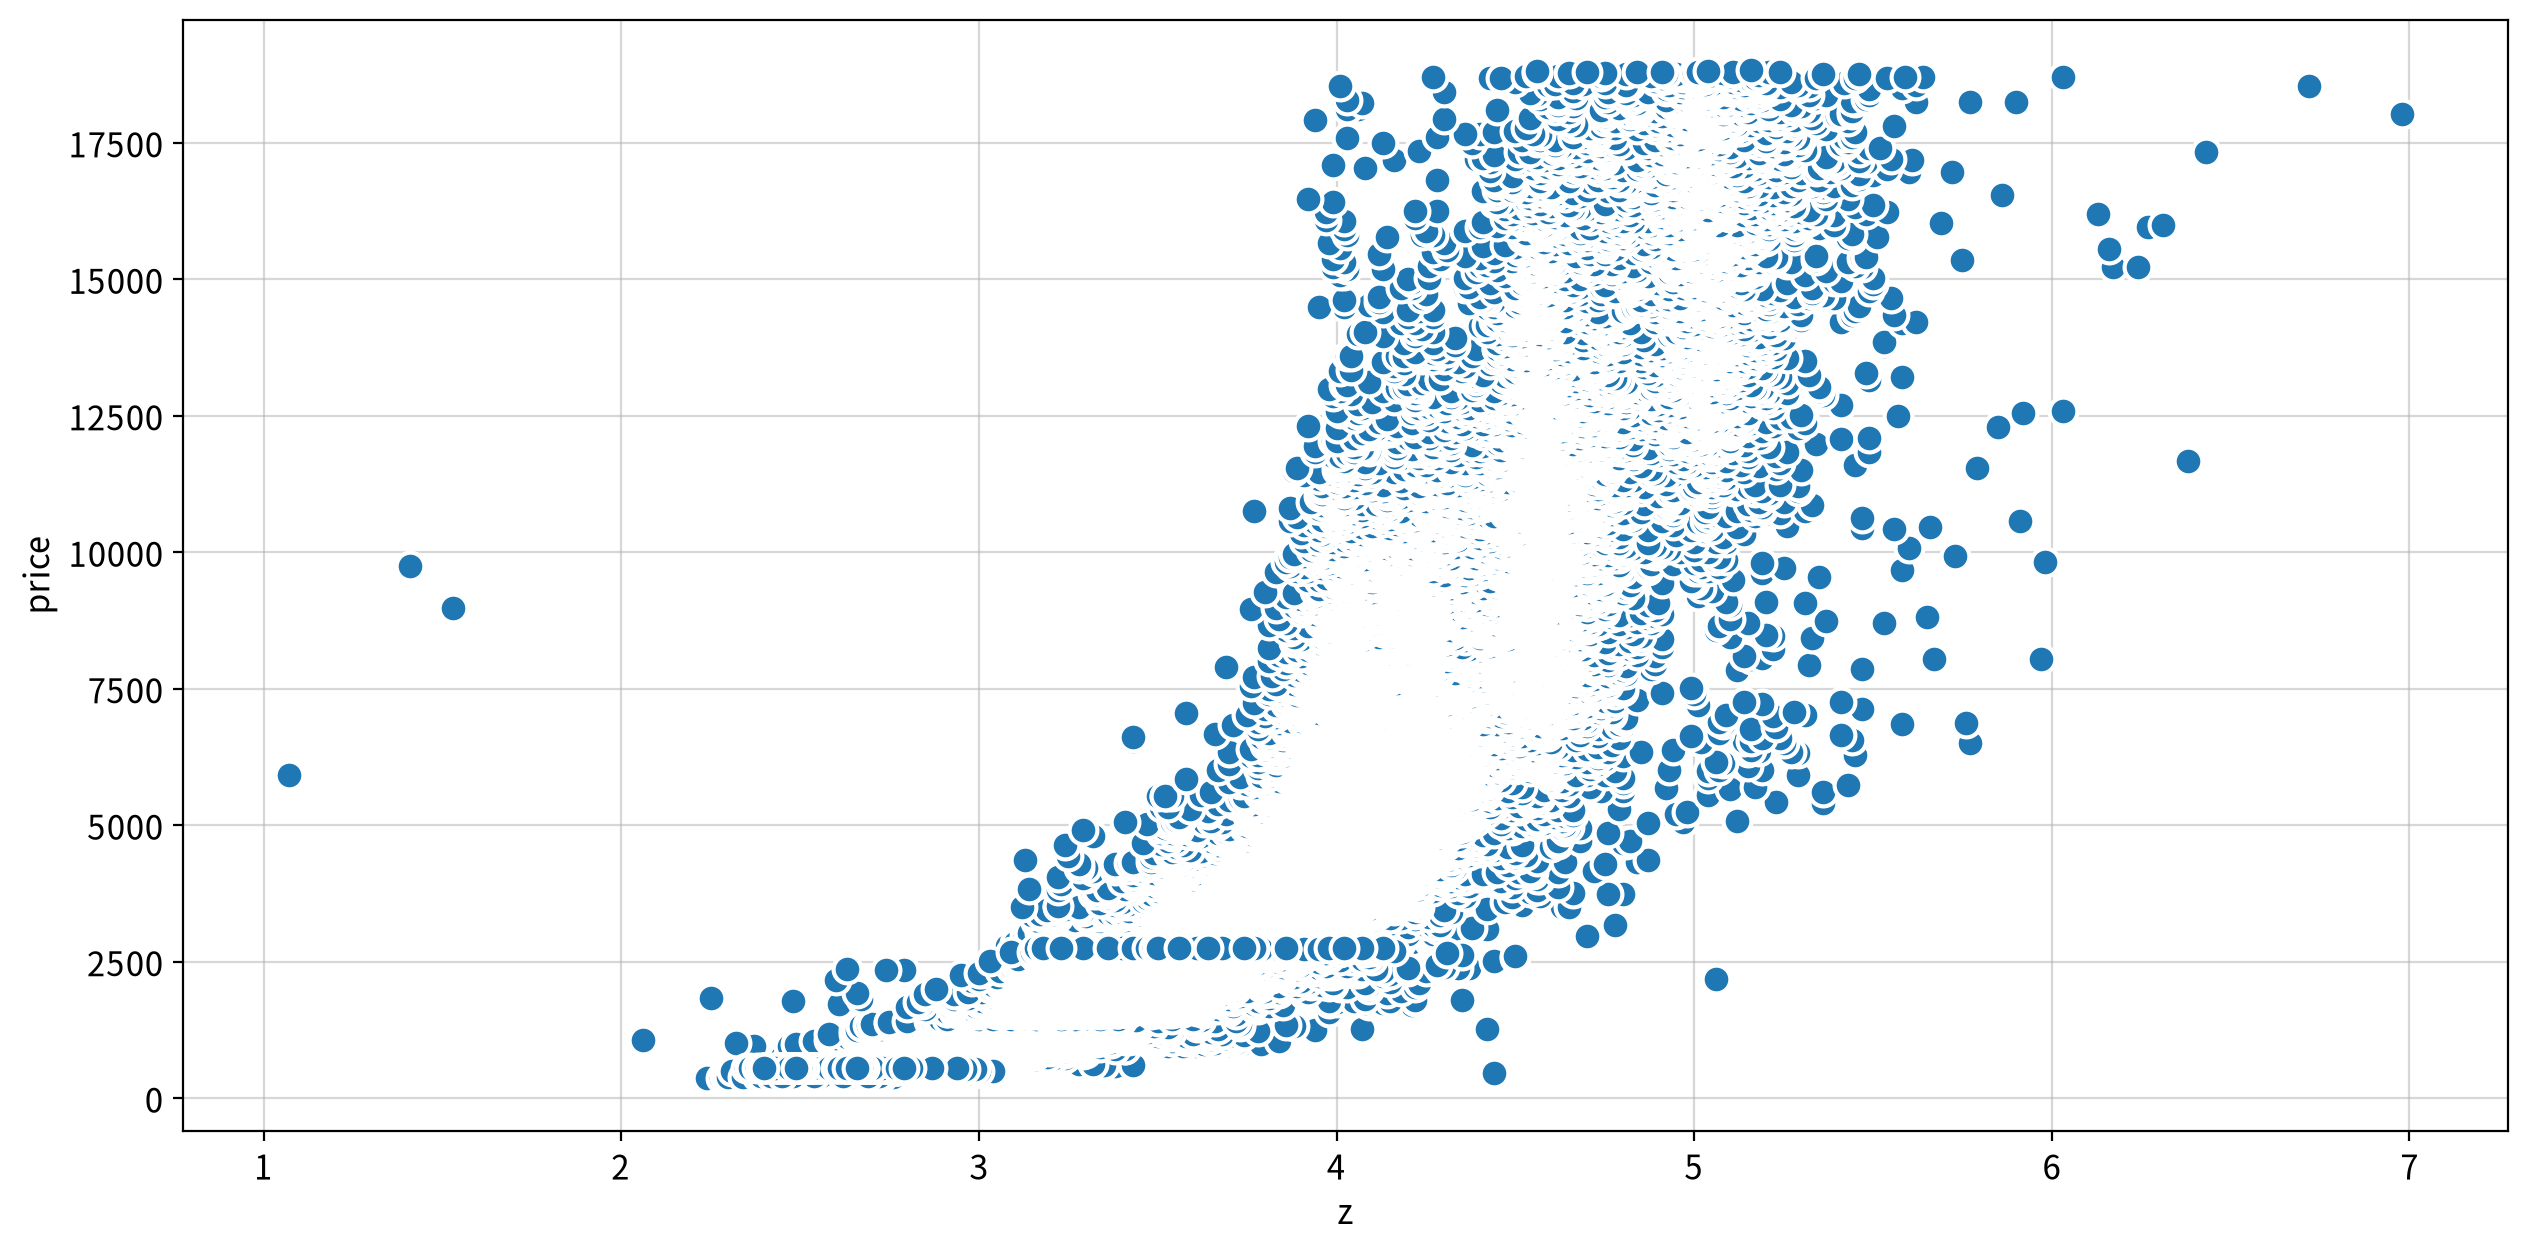

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
z,price,Spearman,0.959,0.000,Strong,True,False,False,False,False,True


#### ▶︎ depth(깊이 비율(%)) → price

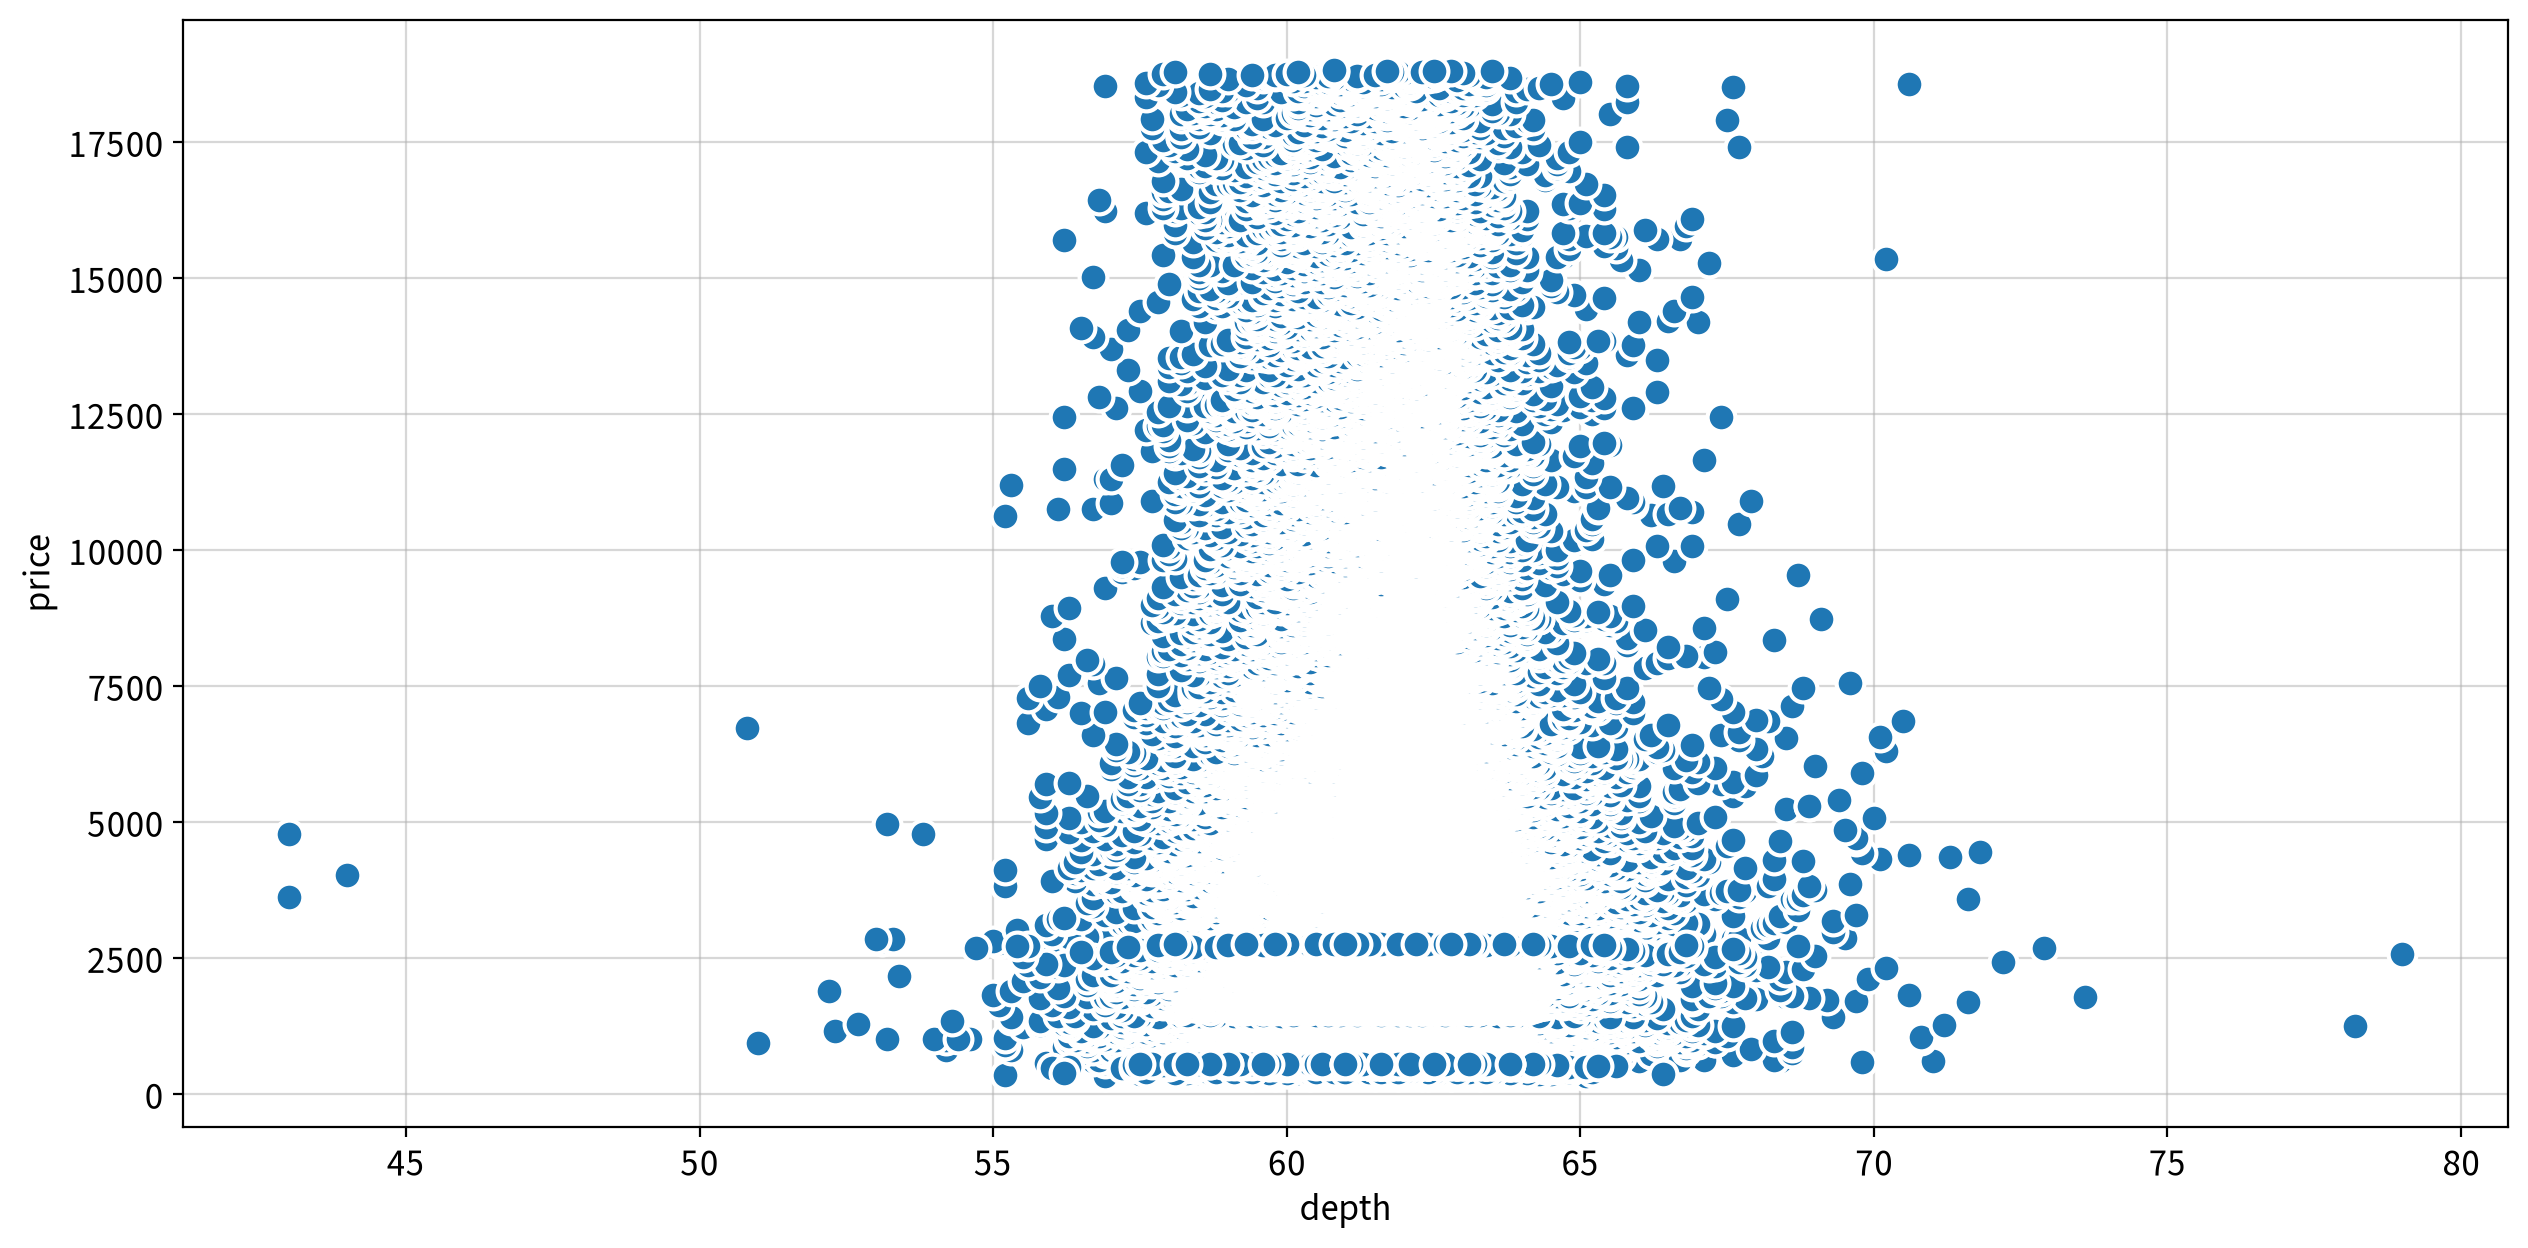

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
depth,price,Spearman,0.010,0.018,Weak,True,False,False,False,False,True


#### ▶︎ table(테이블 비율(%)) → price

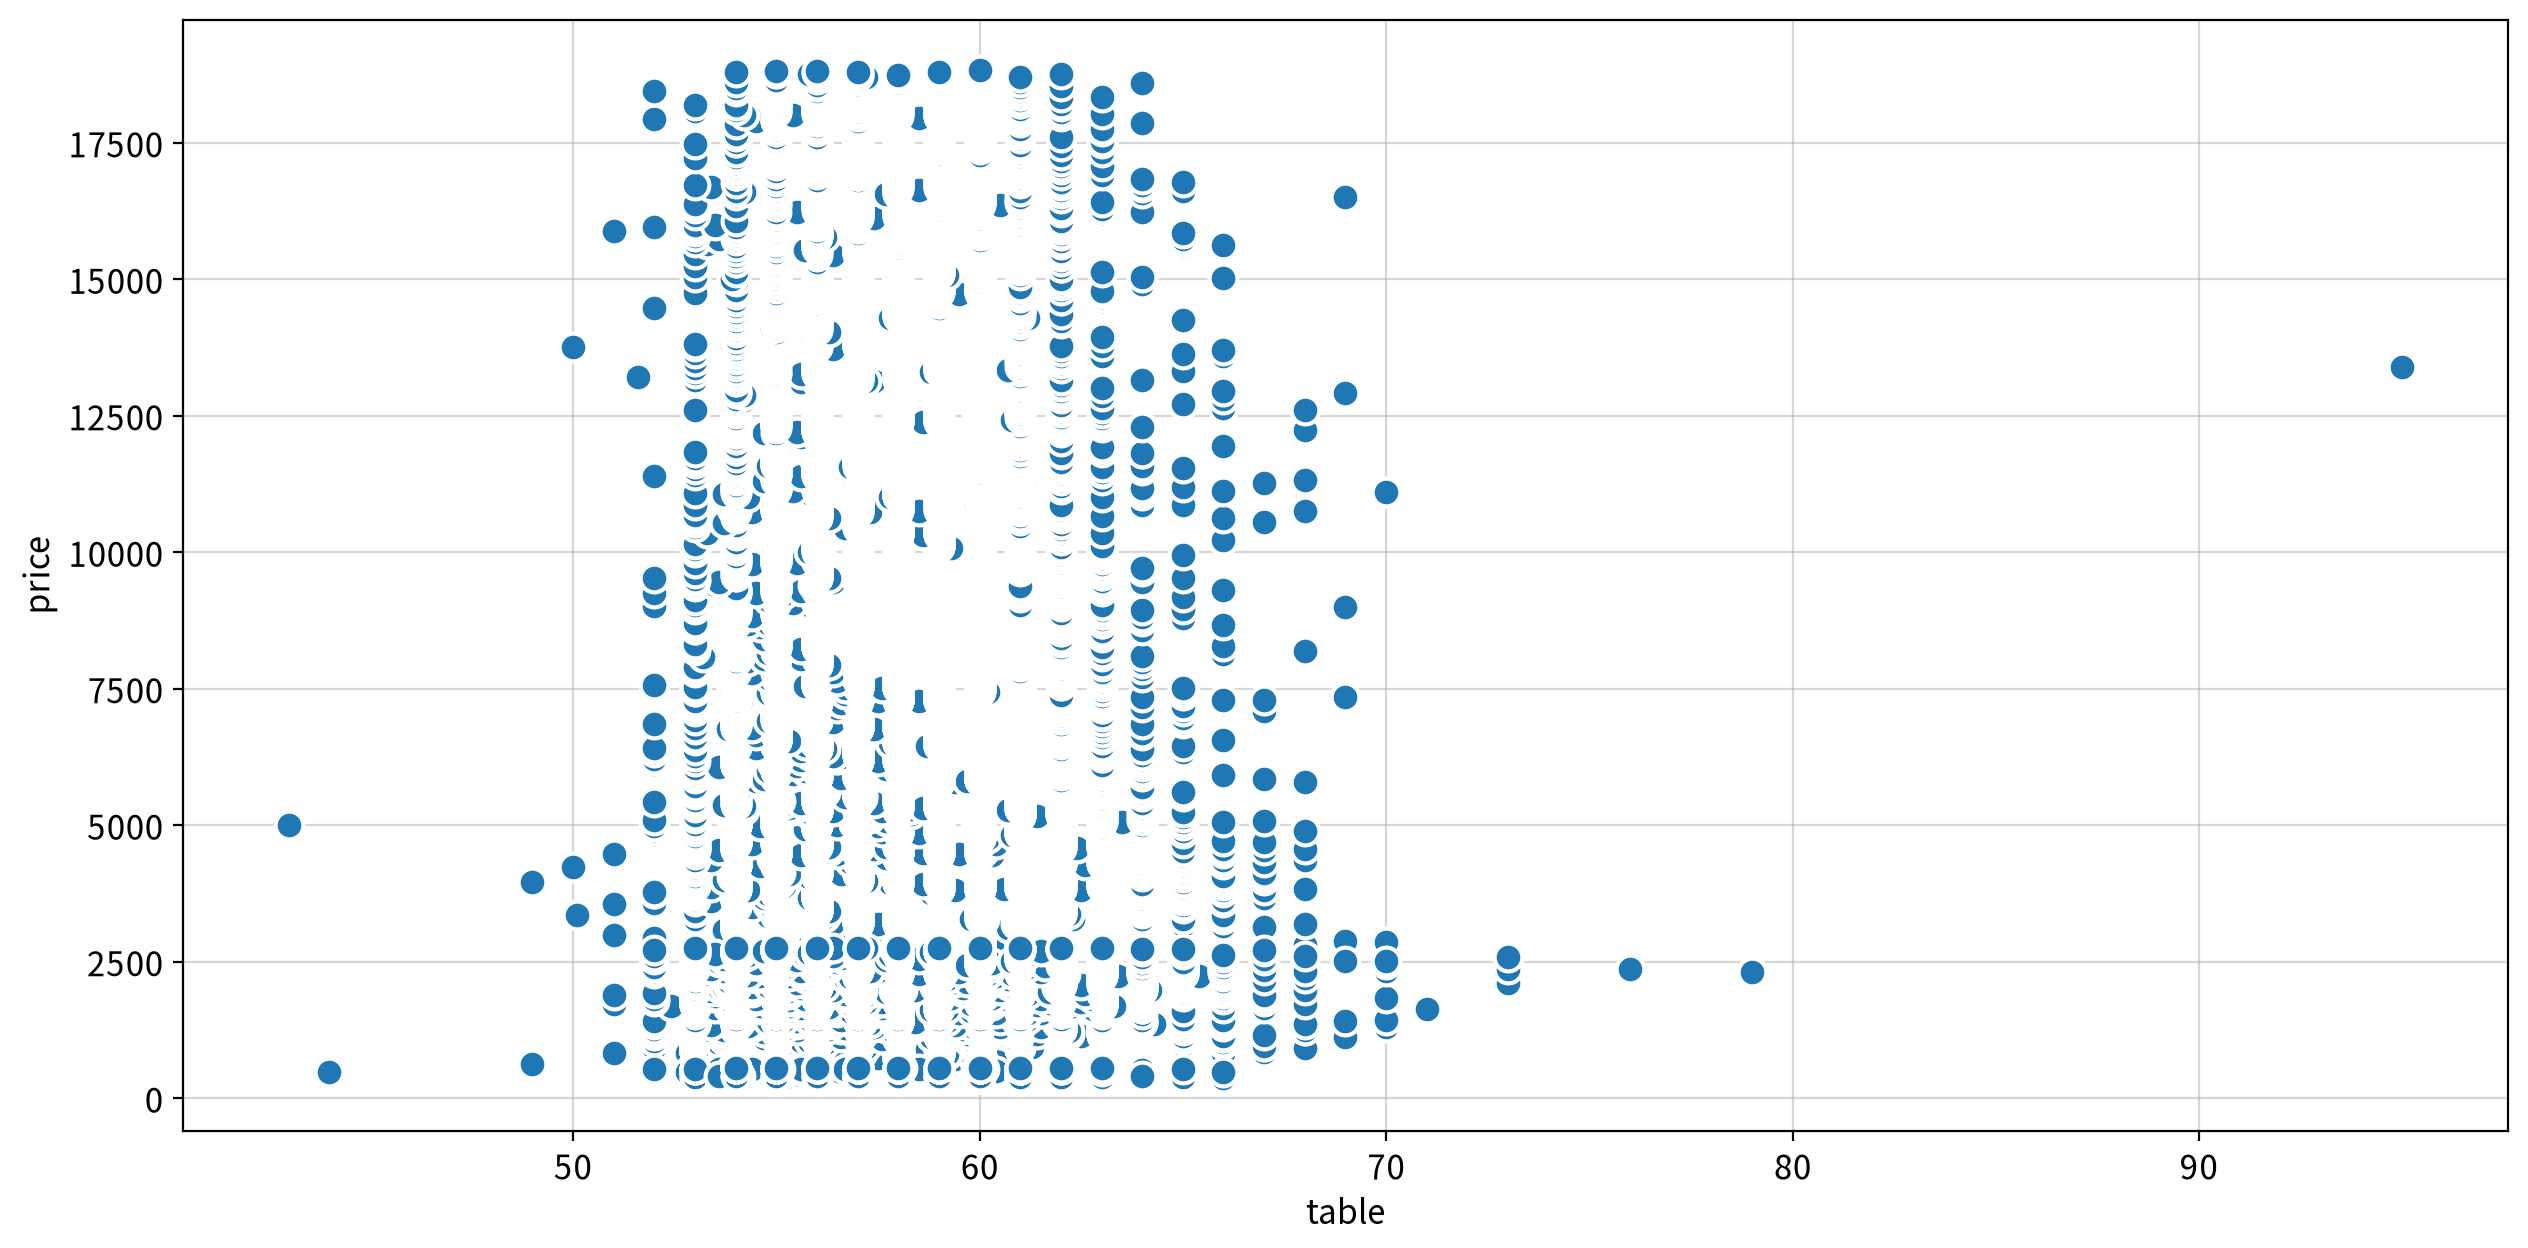

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
table,price,Spearman,0.171,0.000,Weak,True,False,False,False,False,True


In [14]:
for f in continuous_cols:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {f}({column_means[f]}) → {target}")) # h4
    
    # my_stats는 시각화까지 일괄처리 한다.
    display(my_stats.correlation(data=df, x=f, y=target))

> 💡 **인사이트 — 이변량 (연속형 × price)**
>
> - ⚠️ 판정은 **"개별 독립변수 ↔ 종속변수(`price`) 단독 관계"만 기준**으로 한다. 변수 간 중복(공선성)은 여기서 고려하지 않으며, 다음 다변량 분석과 PART 3의 VIF 단계에서 점검한다. 변수별 최종 판정은 아래 (4) 변수 채택 결과 표에 정리했다.
>
> - **6개 중 4개 채택, 2개(`depth` · `table`) 보류.** 
> - **크기 변수 4개(`carat` · `x` · `y` · `z`)가 모두 ρ ≈ 0.96으로 매우 강하다.** 넷의 차이는 0.005 이내라 상관계수만으로는 무엇이 더 중요한지 가릴 수 없다.
> - `table`(ρ = +0.171)은 유의하지만 약해 **보류**했다.
> - `depth`는 **ρ = 0.010으로 사실상 무관**하다. p = 0.018로 유의하게 나온 것은 표본이 5만 개가 넘어 아주 작은 관계도 유의해지기 때문이다. 효과크기가 Cohen 기준 '무시할 수준'(|ρ| < 0.1)이라 **제외**한다.
> - 모든 변수에서 Spearman이 선택됐고, **선형성은 모두 위배**다.

### (2) 명목형(3집단 이상) × 연속형 : 일원분산분석 + 사후검정

- 등분산 여부에 따라 **ANOVA / Welch ANOVA**를 자동 선택한다.

#### ▶︎ cut(컷 등급) → price

,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,cut,4,"9,341.842",162.087,0.000,0.013,Small


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Fair vs. Good: Custom statistical test, P_val:3.720e-04
Good vs. Ideal: Custom statistical test, P_val:7.350e-14
Premium vs. Very Good: Custom statistical test, P_val:0.000e+00
Ideal vs. Premium: Custom statistical test, P_val:0.000e+00
Fair vs. Ideal: Custom statistical test, P_val:4.208e-13
Good vs. Premium: Custom statistical test, P_val:4.481e-12
Ideal vs. Very Good: Custom statistical test, P_val:0.000e+00
Fair vs. Premium: Custom statistical test, P_val:9.673e-02
Good vs. Very Good: Custom statistical test, P_val:8.460e-01
Fair vs. Very Good: Custom statistical test, P_val:1.619e-03


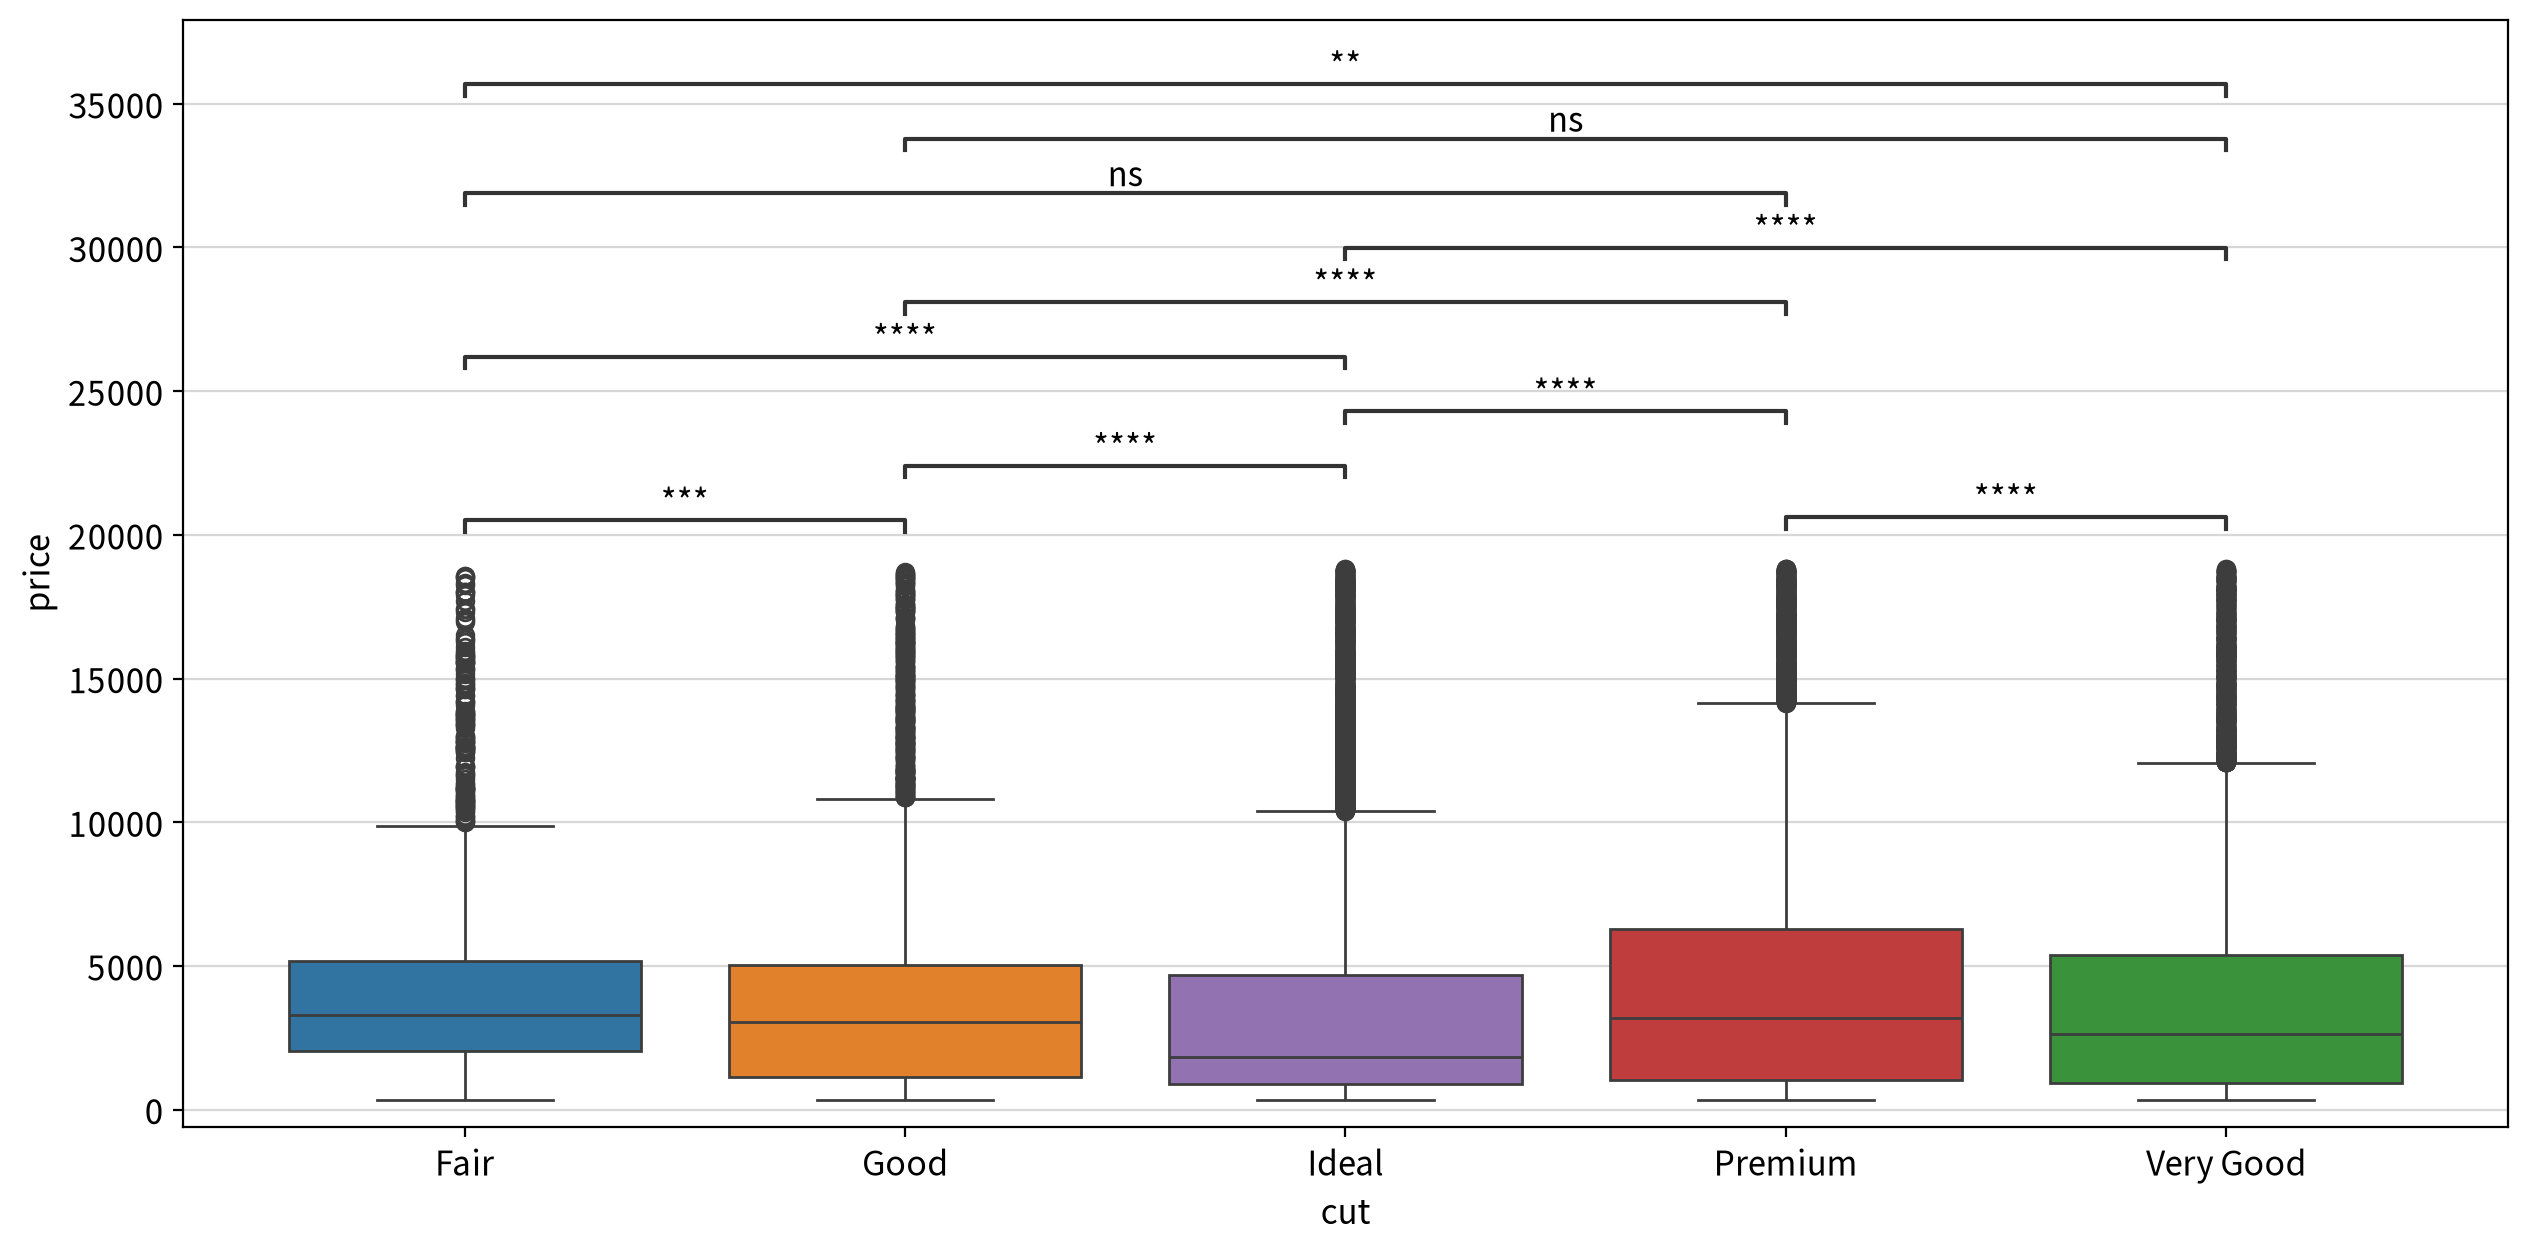

비교한 조합 쌍: 10개
유의한 쌍: 8개
평균 차이가 가장 큰 쌍: (Premium) vs (Ideal)→ 차이 1116.146, 효과크기 Small, p=value 0.000
평균 차이가 가장 작은 쌍: (Good) vs (Very Good)→ 차이 64.808, 효과크기 Negligible, p-value 0.846


,test,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges,significant,effect_size
0,Games-Howell,Fair,Good,"4,340.678","3,916.279",424.398,102.957,4.122,"2,797.546",0.000,0.117,True,Negligible
1,Games-Howell,Fair,Very Good,"4,340.678","3,981.087",359.591,95.572,3.763,"2,152.779",0.002,0.092,True,Negligible
2,Games-Howell,Fair,Premium,"4,340.678","4,578.358",-237.681,96.039,-2.475,"2,195.149",0.097,-0.056,False,Negligible
3,Games-Howell,Fair,Ideal,"4,340.678","3,462.213",878.465,92.340,9.513,"1,881.611",0.000,0.232,True,Small
4,Games-Howell,Good,Very Good,"3,916.279","3,981.087",-64.808,63.503,-1.021,"9,661.082",0.846,-0.017,False,Negligible
5,Games-Howell,Good,Premium,"3,916.279","4,578.358",-662.079,64.204,-10.312,"10,090.475",0.000,-0.159,True,Negligible
6,Games-Howell,Good,Ideal,"3,916.279","3,462.213",454.066,58.526,7.758,"7,482.361",0.000,0.120,True,Negligible
7,Games-Howell,Very Good,Premium,"3,981.087","4,578.358",-597.271,51.537,-11.589,"25,776.162",0.000,-0.144,True,Negligible
8,Games-Howell,Very Good,Ideal,"3,981.087","3,462.213",518.874,44.262,11.723,"24,332.880",0.000,0.135,True,Negligible
9,Games-Howell,Premium,Ideal,"4,578.358","3,462.213","1,116.146",45.263,24.659,"26,485.146",0.000,0.277,True,Small


#### ▶︎ color(색상 등급) → price

,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,color,6,"18,266.247",276.973,0.000,0.031,Small


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

I vs. J: Custom statistical test, P_val:2.263e-01
H vs. I: Custom statistical test, P_val:0.000e+00
G vs. H: Custom statistical test, P_val:1.258e-12
F vs. G: Custom statistical test, P_val:1.186e-05
E vs. F: Custom statistical test, P_val:0.000e+00
D vs. E: Custom statistical test, P_val:5.830e-01
H vs. J: Custom statistical test, P_val:0.000e+00
G vs. I: Custom statistical test, P_val:1.785e-13
F vs. H: Custom statistical test, P_val:7.542e-12
E vs. G: Custom statistical test, P_val:0.000e+00
D vs. F: Custom statistical test, P_val:9.328e-12
G vs. J: Custom statistical test, P_val:2.218e-12
F vs. I: Custom statistical test, P_val:0.000e+00
E vs. H: Custom statistical test, P_val:6.994e-12
D vs. G: Custom statistical test, P_val:9.254e-12
F vs. J: Custom statistical test, P_val:1.252e-12
E vs. I:

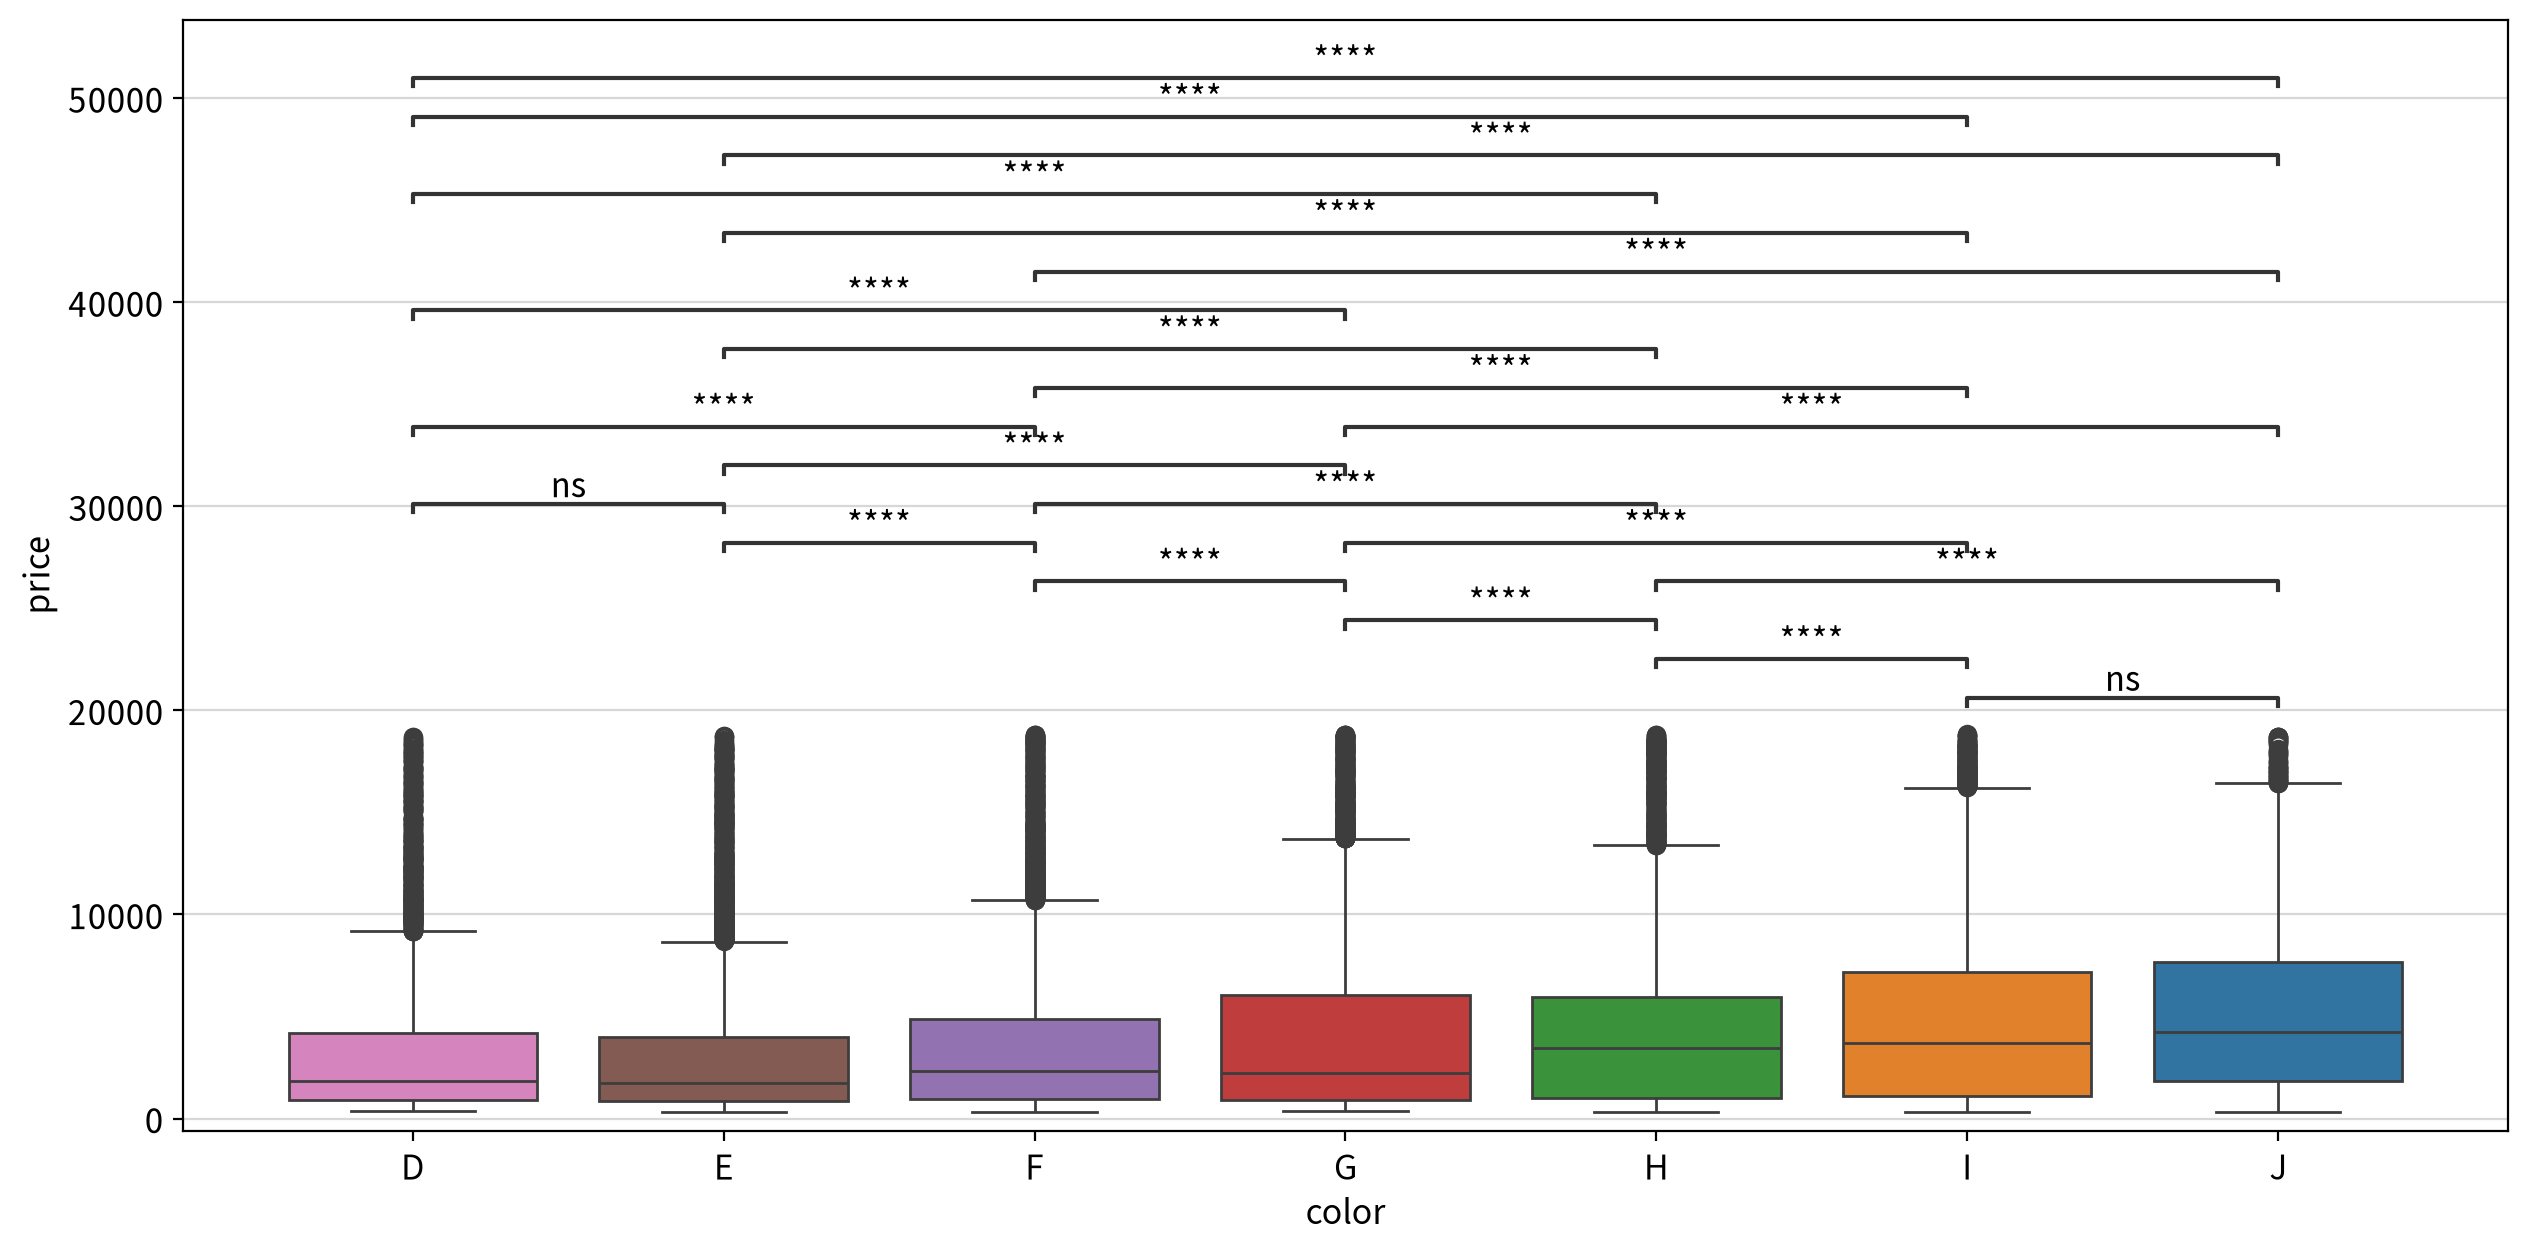

비교한 조합 쌍: 21개
유의한 쌍: 19개
평균 차이가 가장 큰 쌍: (J) vs (E)→ 차이 2246.591, 효과크기 Medium, p=value 0.000
평균 차이가 가장 작은 쌍: (E) vs (D)→ 차이 92.764, 효과크기 Negligible, p-value 0.583


,test,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges,significant,effect_size
0,Games-Howell,J,I,"5,326.415","5,079.843",246.572,105.495,2.337,"5,982.639",0.226,0.053,False,Negligible
1,Games-Howell,J,H,"5,326.415","4,476.168",850.248,95.673,8.887,"4,622.461",0.000,0.199,True,Negligible
2,Games-Howell,J,G,"5,326.415","3,999.089","1,327.327",92.048,14.420,"4,041.885",0.000,0.321,True,Small
3,Games-Howell,J,F,"5,326.415","3,726.777","1,599.639",92.318,17.327,"4,078.142",0.000,0.406,True,Small
4,Games-Howell,J,E,"5,326.415","3,079.824","2,246.591",90.343,24.867,"3,762.154",0.000,0.621,True,Medium
5,Games-Howell,J,D,"5,326.415","3,172.589","2,153.827",93.184,23.114,"4,192.602",0.000,0.581,True,Medium
6,Games-Howell,I,H,"5,079.843","4,476.168",603.676,79.064,7.635,"10,608.517",0.000,0.137,True,Negligible
7,Games-Howell,I,G,"5,079.843","3,999.089","1,080.755",74.636,14.480,"9,348.910",0.000,0.253,True,Small
8,Games-Howell,I,F,"5,079.843","3,726.777","1,353.066",74.969,18.048,"9,375.922",0.000,0.326,True,Small
9,Games-Howell,I,E,"5,079.843","3,079.824","2,000.019",72.523,27.578,"8,472.827",0.000,0.514,True,Medium


#### ▶︎ clarity(투명도 등급) → price

,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,clarity,7,"8,521.456",222.085,0.000,0.027,Small


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

I1 vs. IF: Custom statistical test, P_val:1.584e-12
SI1 vs. SI2: Custom statistical test, P_val:0.000e+00
SI2 vs. VS1: Custom statistical test, P_val:0.000e+00
IF vs. SI1: Custom statistical test, P_val:4.032e-13
VS1 vs. VS2: Custom statistical test, P_val:8.297e-01
VS2 vs. VVS1: Custom statistical test, P_val:0.000e+00
VVS1 vs. VVS2: Custom statistical test, P_val:5.255e-12
I1 vs. SI1: Custom statistical test, P_val:9.987e-01
SI2 vs. VS2: Custom statistical test, P_val:0.000e+00
IF vs. SI2: Custom statistical test, P_val:3.383e-13
SI1 vs. VS1: Custom statistical test, P_val:1.086e-01
VS2 vs. VVS2: Custom statistical test, P_val:2.275e-12
VS1 vs. VVS1: Custom statistical test, P_val:0.000e+00
I1 vs. SI2: Custom statistical test, P_val:0.000e+00
SI2 vs. VVS1: Custom statistical test, P_val:0.000e+0

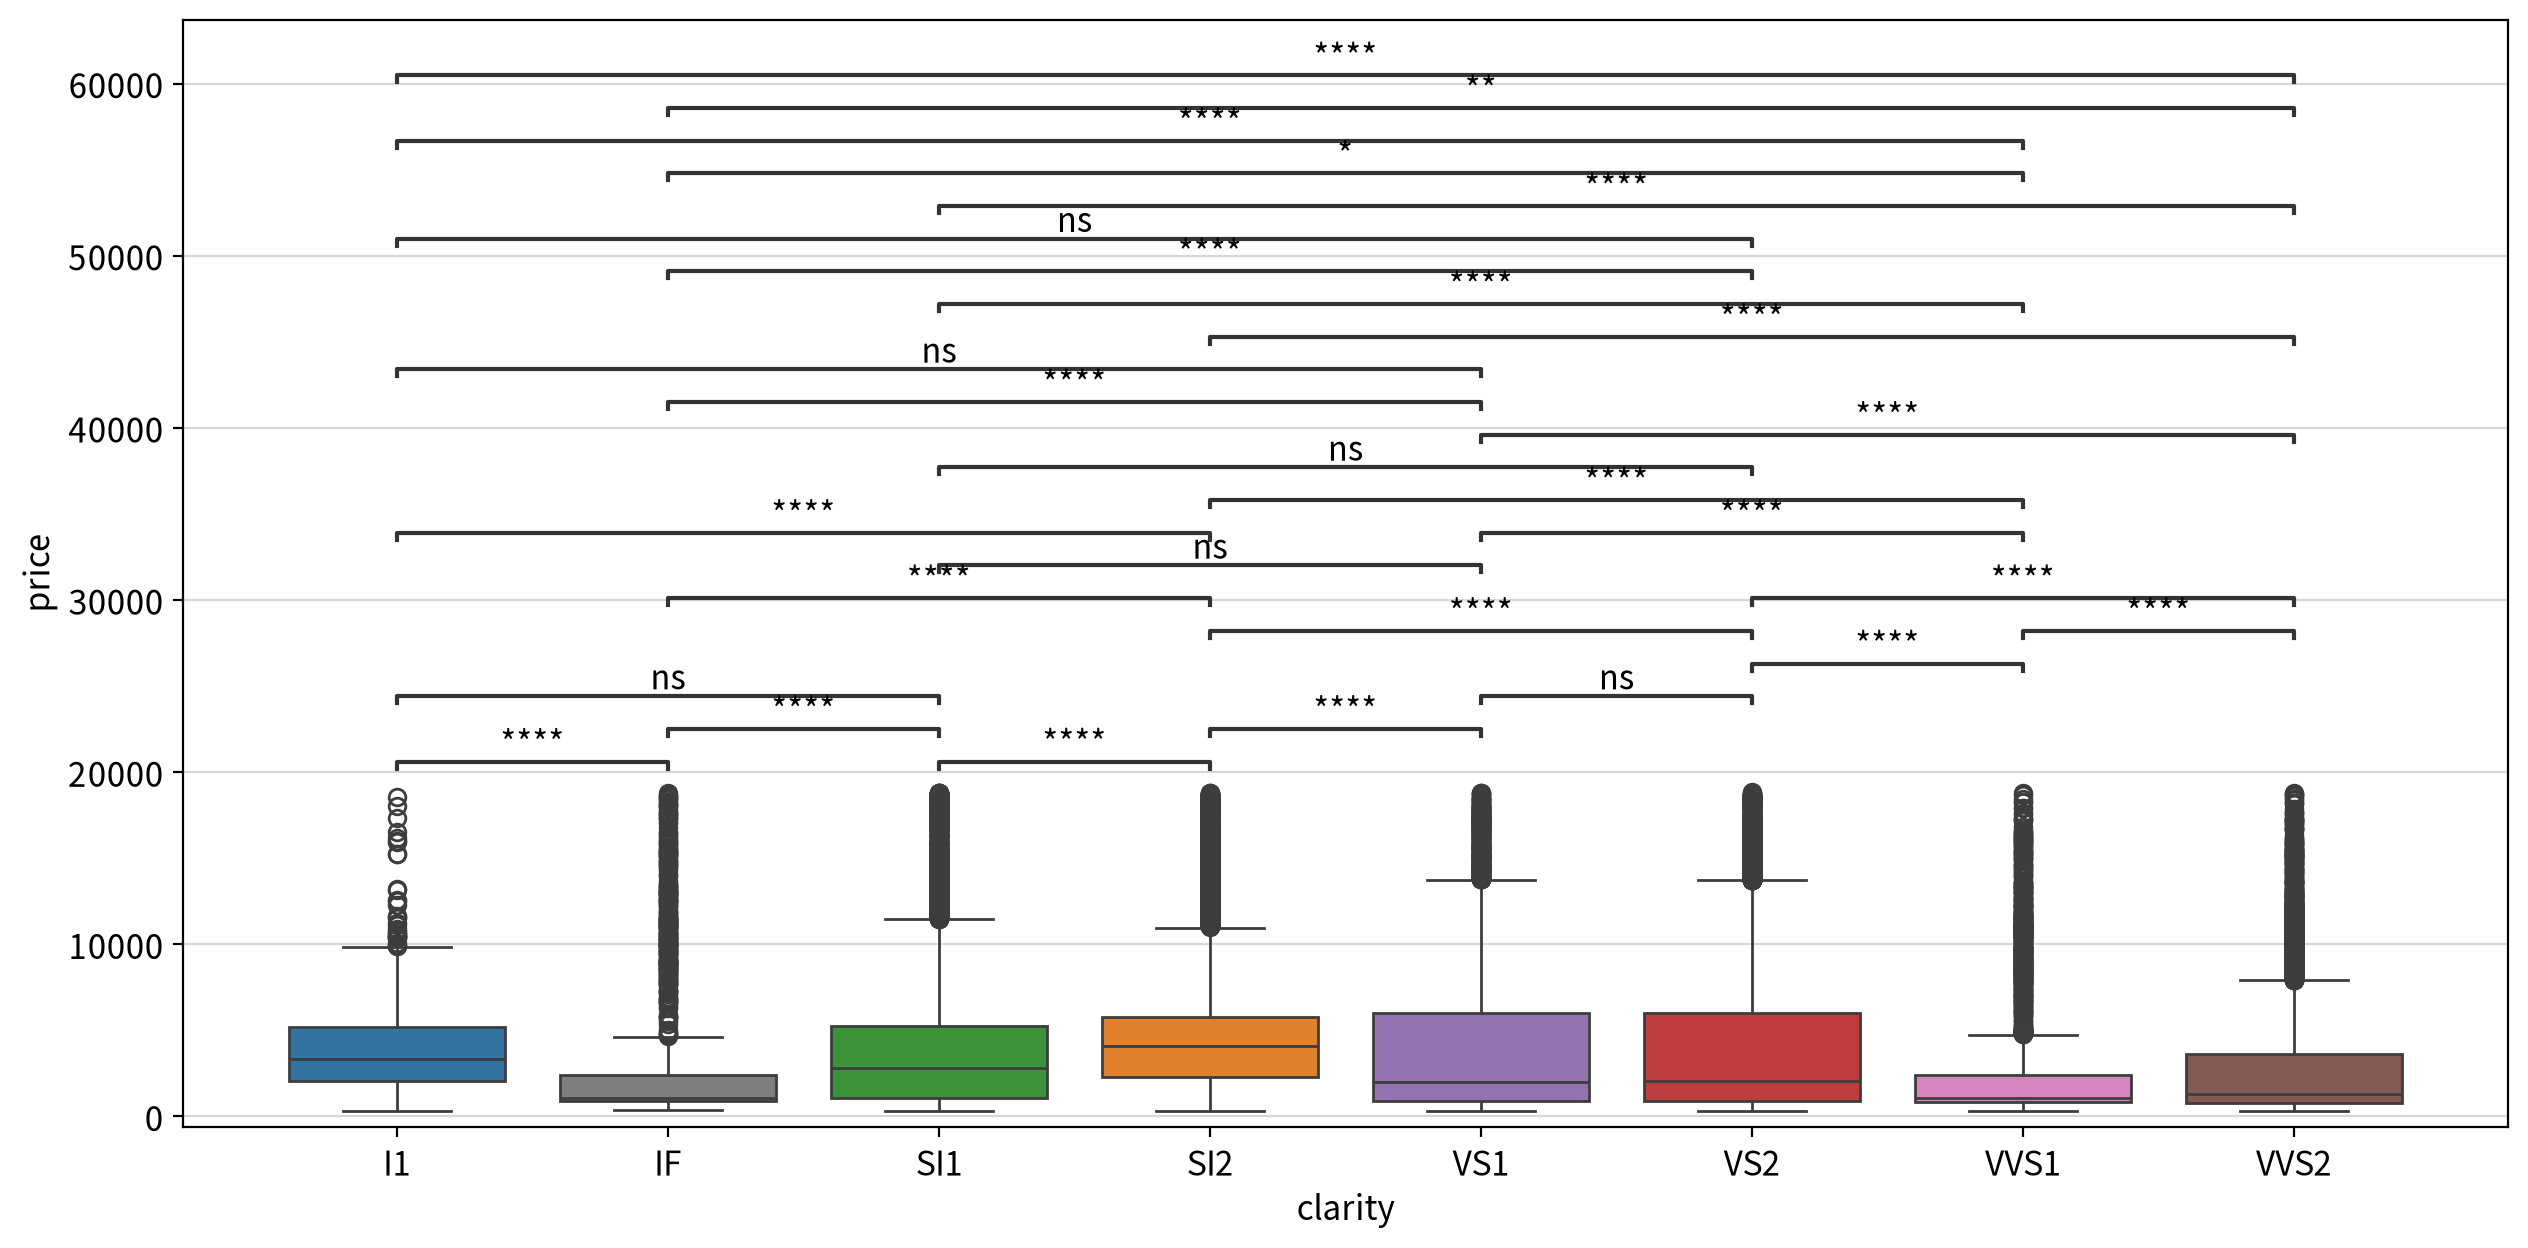

비교한 조합 쌍: 28개
유의한 쌍: 22개
평균 차이가 가장 큰 쌍: (SI2) vs (VVS1)→ 차이 2530.753, 효과크기 Medium, p=value 0.000
평균 차이가 가장 작은 쌍: (I1) vs (VS2)→ 차이 1.689, 효과크기 Negligible, p-value 1.000


,test,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges,significant,effect_size
0,Games-Howell,I1,SI2,"3,927.304","5,053.746","-1,126.442",112.767,-9.989,"1,029.099",0.000,-0.271,True,Small
1,Games-Howell,I1,SI1,"3,927.304","3,994.272",-66.968,108.838,-0.615,894.896,0.999,-0.018,False,Negligible
2,Games-Howell,I1,VS2,"3,927.304","3,925.615",1.689,109.883,0.015,929.460,1.000,0.000,False,Negligible
3,Games-Howell,I1,VS1,"3,927.304","3,841.746",85.558,112.754,0.759,"1,028.305",0.995,0.022,False,Negligible
4,Games-Howell,I1,VVS2,"3,927.304","3,286.532",640.771,116.751,5.488,"1,173.257",0.000,0.173,True,Negligible
5,Games-Howell,I1,VVS1,"3,927.304","2,522.994","1,404.310",117.400,11.962,"1,192.869",0.000,0.432,True,Small
6,Games-Howell,I1,IF,"3,927.304","2,870.570","1,056.734",139.203,7.591,"1,891.087",0.000,0.291,True,Small
7,Games-Howell,SI2,SI1,"5,053.746","3,994.272","1,059.474",55.526,19.081,"18,227.084",0.000,0.266,True,Small
8,Games-Howell,SI2,VS2,"5,053.746","3,925.615","1,128.132",57.548,19.603,"19,128.849",0.000,0.273,True,Small
9,Games-Howell,SI2,VS1,"5,053.746","3,841.746","1,212.000",62.857,19.282,"17,236.970",0.000,0.293,True,Small


In [15]:
for n in nominal_cols:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {n}({column_means[n]}) → {target}"))

    # anova 분석은 long 타입으로 바로 투입 가능
    display(my_stats.anova_oneway(df, y=target, between=n))

    # 사후검정
    display(my_stats.posthoc_oneway(df, y=target, between=n))

> 💡 **인사이트 — 이변량 (등급 × price)**
>
> - 세 등급 모두 등분산성이 위배돼 Welch ANOVA가 선택됐고, **모두 유의**했다(p < 0.001).
> - 하지만 효과크기는 모두 **Small**이다: `cut` np² = 0.013, `color` 0.031, `clarity` 0.027.
> - 사후검정에서도 대부분의 쌍이 유의했다(`cut` 10쌍 중 8, `color` 21쌍 중 19, `clarity` 28쌍 중 22).
> - 등급이 가격을 가르기는 하지만 힘은 약하다. 그런데 ANOVA는 '차이가 있다'만 알려 줄 뿐, **좋은 등급이 비싼지 나쁜 등급이 비싼지(방향)** 는 알려 주지 않는다. 아래에서 등급별 평균 가격으로 방향을 확인한다.

### (3) 등급이 높을수록 비싼가? — 등급별 평균 가격과 평균 중량

In [16]:
for n in nominal_cols:
    display(Markdown(f"#### ▶ {n} (왼쪽이 낮은 등급)"))
    display(df.groupby(n, observed=True)[[target, "carat"]].mean().T)

#### ▶ cut (왼쪽이 낮은 등급)

cut,Fair,Good,Very Good,Premium,Ideal
price,"4,340.678","3,916.279","3,981.087","4,578.358","3,462.213"
carat,1.044,0.847,0.806,0.891,0.703


#### ▶ color (왼쪽이 낮은 등급)

color,J,I,H,G,F,E,D
price,"5,326.415","5,079.843","4,476.168","3,999.089","3,726.777","3,079.824","3,172.589"
carat,1.163,1.025,0.910,0.771,0.737,0.658,0.658


#### ▶ clarity (왼쪽이 낮은 등급)

clarity,I1,SI2,SI1,VS2,VS1,VVS2,VVS1,IF
price,"3,927.304","5,053.746","3,994.272","3,925.615","3,841.746","3,286.532","2,522.994","2,870.570"
carat,1.284,1.076,0.850,0.764,0.727,0.597,0.504,0.506


> 💡 **인사이트 — '등급의 역설'**
>
> - 등급별 평균 가격을 보면 **나쁜 등급이 더 비싸다.**
>
> | 등급 | 가장 나쁜 등급 평균가 | 가장 좋은 등급 평균가 |
> |---|---|---|
> | cut | Fair : 4,341달러 | Ideal : 3,462달러 |
> | color | J : 5,326달러 | D : 3,173달러 |
> | clarity | I1 : 3,927달러 | IF : 2,871달러 |
>
> - 원인은 **중량**이다. 가장 나쁜 등급의 평균 중량이 가장 좋은 등급보다 훨씬 크다(`color` J 1.16캐럿 vs D 0.66캐럿, `clarity` I1 1.28캐럿 vs IF 0.51캐럿). **낮은 등급에 큰 원석이 몰려 있어서**, 단순 평균으로는 '나쁜 등급 = 비싼 돌'처럼 보인다. 큰 원석일수록 흠 없이 투명하기 어렵기 때문으로 보인다.
> - 이것이 **심슨의 역설(Simpson's paradox)** 이다. 등급의 진짜 효과는 **중량을 통제한 회귀모델**에서만 볼 수 있다. → PART 3에서 확인한다.
> - 그래서 효과크기가 작고 방향이 거꾸로여도, 세 등급은 모두 **채택**해 모델에서 다시 판정한다.

### (4) 변수 채택 결과 표

- **채택 기준은 "각 독립변수 ↔ 종속변수(`price`) 단독 관계"만 사용한다.**
  - 연속형 : 유의(p < 0.05) + 상관강도 Moderate 이상(|ρ| ≥ 0.3), 유의하지만 약하면 보류
  - 명목형 : 집단 차이 유의(p < 0.05)
- 종합 판정 : **채택 7, 보류 1, 제외 1**

| 채택여부 | 변수 | 검정방법 | 유의수준 (p) | 효과크기 | 가정점검 | 비대칭신호 | 근거 |
|---|---|---|---|---|---|---|---|
| ✅ 채택 | x | Spearman | $< 0.001$ | ρ=+0.964 (강함) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 대칭 / 불필요 | 크기 변수 |
| ✅ 채택 | carat | Spearman | $< 0.001$ | ρ=+0.963 (강함) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 우편향 / log | 크기 변수 (가격 산정 기준) |
| ✅ 채택 | y | Spearman | $< 0.001$ | ρ=+0.963 (강함) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 대칭 / 불필요 | 크기 변수 |
| ✅ 채택 | z | Spearman | $< 0.001$ | ρ=+0.959 (강함) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 대칭 / 불필요 | 크기 변수 |
| ✅ 채택 | color | Welch ANOVA | $< 0.001$ | np²=0.031 (Small) | 등분산성 위배 → Welch ANOVA, Games-Howell | 해당 없음 | 집단 차이 유의 (방향은 역설) |
| ✅ 채택 | clarity | Welch ANOVA | $< 0.001$ | np²=0.027 (Small) | 등분산성 위배 → Welch ANOVA, Games-Howell | 해당 없음 | 집단 차이 유의 (방향은 역설) |
| ✅ 채택 | cut | Welch ANOVA | $< 0.001$ | np²=0.013 (Small) | 등분산성 위배 → Welch ANOVA, Games-Howell | 해당 없음 | 집단 차이 유의 |
| 🟡 보류 | table | Spearman | $< 0.001$ | ρ=+0.171 (약함) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 우편향 / log | 유의하나 관계 약함 (\|ρ\|<0.3) |
| ❌ 제외 | depth | Spearman | $0.018$ | ρ=+0.010 (무시할 수준) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 대칭 / 불필요 | 유의하지만 효과크기 무시할 수준 (큰 표본 때문) |

## 2-3. 다변량 분석 — 독립변수끼리 같은 정보를 담고 있는가?

- |ρ| ≥ 0.7 인 **강한 상관 쌍**을 변수별로 묶어 보여 준다.

In [17]:
corr_x = my_stats.multi_correlation(data=df, columns=continuous_cols, plot=False)
my_stats.correlation_summary(corr_x)

,carat,x,y,z,depth,table
carat,1.000,0.997,0.996,0.995,0.030,0.194
x,0.997,1.000,0.998,0.989,-0.023,0.202
y,0.996,0.998,1.000,0.988,-0.025,0.195
z,0.995,0.989,0.988,1.000,0.104,0.160
depth,0.030,-0.023,-0.025,0.104,1.000,-0.245
table,0.194,0.202,0.195,0.160,-0.245,1.000


,max-y,max-coef,count,columns
x,,,,
x,y,0.998,3,"y, carat, z"
y,x,0.998,3,"x, carat, z"
carat,x,0.997,3,"x, y, z"
z,carat,0.995,3,"carat, x, y"
depth,table,-0.245,0,-
table,depth,-0.245,0,-


> 💡 **인사이트 — 다변량**
>
> | 변수 | 강하게 얽힌 상대 (\|ρ\| ≥ 0.7) | 개수 | 가격과의 \|ρ\| | 판단 |
> |---|---|---|---|---|
> | `carat` | x · y · z | 3 | 0.963 | ✅ **채택 (크기 덩어리 대표)** |
> | `x` | y · carat · z | 3 | 0.964 | 🔶 후보 (`carat`과 중복) |
> | `y` | x · carat · z | 3 | 0.963 | 🔶 후보 (`carat`과 중복) |
> | `z` | carat · x · y | 3 | 0.959 | 🔶 후보 (`carat`과 중복) |
> | `table` | — | 0 | 0.171 | 덩어리 없음 → 이변량 판정(🟡 보류) 유지 |
> | `depth` | — | 0 | 0.010 | 덩어리 없음 → 이변량 판정(❌ 제외) 유지 |
>
> - `x` · `y` · `z` · `carat`은 서로 ρ = 0.988~0.998로 **사실상 같은 변수**다. 중량은 부피(길이 × 너비 × 깊이)의 함수이므로 당연한 결과다.
> - 덩어리 안에서는 **가격과의 |ρ|가 가장 큰 변수**를 대표로 남기는 것이 기준이다. 규칙상으로는 `x`(0.964)가 대표지만, `carat`(0.963)과의 차이가 **0.001**뿐이라 사실상 같다.
> - 다이아몬드 가격은 업계에서 **중량(캐럿)** 으로 매겨지므로, 도메인 지식에 따라 **`carat`을 대표로 채택**하고 나머지는 후보로 둔다.
> - 후보는 이 단계에서 제거하지 않는다. PART 3에서 VIF가 고른 결과와 도메인 지식으로 고른 결과를 비교한다.

## 2-4. 최종 변수 선택

- **EDA 판정 기준**
  - 이변량 : 유의 + |ρ| ≥ 0.3 → ✅ 채택, 유의하지만 0.1 ≤ |ρ| < 0.3 → 🟡 보류, |ρ| < 0.1(효과 무시할 수준) → ❌ 제외
  - 다변량 : 크기 덩어리(`x` · `y` · `z` · `carat`)에서 `carat`을 대표로 채택하고(도메인 지식, 2-3 참고), 나머지는 🔶 후보로 둔다

| EDA 판정 | 변수 | 검정방법 | 유의수준 | 효과크기 | 가정점검 | 비대칭신호 | 중복 (\|ρ\| ≥ 0.7) | EDA 근거 |
|---|---|---|---|---|---|---|---|---|
| ✅ 채택 | carat | Spearman | $< 0.001$ | ρ=+0.963 (강함) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 우편향 / log | x · y · z | 크기 덩어리 대표 (도메인 지식) |
| ✅ 채택 | color | Welch ANOVA | $< 0.001$ | np²=0.031 (Small) | 등분산성 위배 → Welch ANOVA, Games-Howell | 해당 없음 | 해당 없음 | 집단 차이 유의 (방향은 역설 → 모델에서 확인) |
| ✅ 채택 | clarity | Welch ANOVA | $< 0.001$ | np²=0.027 (Small) | 등분산성 위배 → Welch ANOVA, Games-Howell | 해당 없음 | 해당 없음 | 집단 차이 유의 (방향은 역설 → 모델에서 확인) |
| ✅ 채택 | cut | Welch ANOVA | $< 0.001$ | np²=0.013 (Small) | 등분산성 위배 → Welch ANOVA, Games-Howell | 해당 없음 | 해당 없음 | 집단 차이 유의 |
| 🔶 후보 | x | Spearman | $< 0.001$ | ρ=+0.964 (강함) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 대칭 / 불필요 | y · carat · z | 크기 덩어리 중복 |
| 🔶 후보 | y | Spearman | $< 0.001$ | ρ=+0.963 (강함) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 대칭 / 불필요 | x · carat · z | 크기 덩어리 중복 |
| 🔶 후보 | z | Spearman | $< 0.001$ | ρ=+0.959 (강함) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 대칭 / 불필요 | carat · x · y | 크기 덩어리 중복 |
| 🟡 보류 | table | Spearman | $< 0.001$ | ρ=+0.171 (약함) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 우편향 / log | 없음 | 관계 약함 (\|ρ\| < 0.3) |
| ❌ 제외 | depth | Spearman | $0.018$ | ρ=+0.010 (무시할 수준) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 대칭 / 불필요 | 없음 | 유의하지만 효과크기 무시할 수준 (큰 표본 때문) |

<br>

> 💡 **인사이트 — EDA 판정 요약**
>
> - **채택 4개, 후보 3개, 보류 1개, 제외 1개.** 효과크기가 무시할 수준인 `depth`만 빼고, 나머지 **8개 변수를 모델에 투입**한다.
> - 후보 · 보류 변수는 EDA에서 지우지 않는다. 후보는 단독으로는 강하지만 `carat`과 겹치는 변수이고, 보류는 유의하지만 관계가 약한 변수다. 모두 모델에 넣은 뒤 **VIF와 후진소거로 최종 판정**한다.
> - 등급 3종은 효과크기가 작고 방향까지 거꾸로였지만, 그 원인이 중량이라는 것을 확인했으므로 **중량을 통제한 모델**에서 진짜 효과를 다시 본다.
> - PART 3에서는 두 가지 방식을 비교한다. ① 8개 변수를 모두 넣고 **VIF에게 크기 변수를 고르게** 하는 방식, ② 도메인 지식대로 크기 변수는 **`carat`만 남기는** 방식이다.

---
# PART 3. 회귀모델링 

### (1) EDA 결과 반영 · 더미 기준 범주 확인

- EDA에서 제외한 `depth`(사실상 무관, ρ = 0.010)를 제외한다.
- `labeling`은 범주를 **알파벳 순**으로 0부터 매기고, 0번이 더미의 기준 범주가 된다. 계수 해석을 위해 매핑을 기록해 둔다.

In [18]:
df2 = df.drop(columns=["depth"])
_ = my_prep.labeling(df2, columns=nominal_cols)
print("모델 투입 변수 :", df2.columns.drop(target).tolist())

cut (5종): Fair=0, Good=1, Ideal=2, Premium=3, Very Good=4
color (7종): D=0, E=1, F=2, G=3, H=4, I=5, J=6
clarity (8종): I1=0, IF=1, SI1=2, SI2=3, VS1=4, VS2=5, VVS1=6, VVS2=7
모델 투입 변수 : ['carat', 'cut', 'color', 'clarity', 'x', 'y', 'z', 'table']


### (2) 전처리 체크포인트 정의

In [19]:
checkpoints = {
    "0_기준선":     dict(),
    "1_로그변환":   dict(log=True),
    "2_이상치대체": dict(log=True, outlier=True),
    "3_공선성제거": dict(log=True, outlier=True, vif=True),
    "4_스케일링":   dict(log=True, outlier=True, vif=True, scale=True),
}

### (3) 체크포인트별 적합

In [20]:
fits = {}

for name in checkpoints:           # 딕셔너리를 반복문에 설정하면 key에 대한 반복이 수행된다
    print(f"\n▶︎ --- {name} ---")

    # 전처리 + 모델 적합을 한 번에 수행한다 
    # -> name 을 지정해 두면 compare_models 의 결과표에 그대로 사용된다
    fits[name] = my_ols.fit_pipeline(data=df2, y=target, 
                                    nominal_cols=nominal_cols, name=name, verbose=False, 
                                    **checkpoints[name])


▶︎ --- 0_기준선 ---


▶︎ --- 1_로그변환 ---

유의하지 않은 독립변수 제거 → table (p = 0.8709)

▶︎ --- 2_이상치대체 ---

유의하지 않은 독립변수 제거 → table (p = 0.4550)

▶︎ --- 3_공선성제거 ---

완료! 남은 변수: ['table', 'z']
최대 VIF = 1.03


▶︎ --- 4_스케일링 ---

완료! 남은 변수: ['table', 'z']
최대 VIF = 1.03



### (4) 성능 비교

In [21]:
best = my_ols.compare_models(fits)
print("선택된 모델 :", best.name_)

,변수 수,R²(모델척도),Adj.R²,AIC,BIC,R²(원본척도),RMSE,MAE,Gap(%)
모델,,,,,,,,,
2_이상치대체,21,0.983,0.983,"-64,297.274","-64,101.638",0.956,832.650,405.799,0.000
1_로그변환,21,0.983,0.983,"-64,219.787","-64,024.151",0.956,837.446,405.893,0.580
0_기준선,22,0.921,0.921,"908,008.100","908,212.628",0.921,"1,123.007",732.834,34.870
3_공선성제거,19,0.969,0.968,"-31,682.892","-31,505.042",0.826,"1,663.172",653.132,99.740
4_스케일링,19,0.969,0.968,"-31,682.892","-31,505.042",0.826,"1,663.172",653.132,99.740


선택된 모델 : 2_이상치대체


> 💡 **인사이트 — 기계적 전처리 비교**
>
> - **로그변환이 결정적**이다: RMSE 1,123 → 837달러(−25%).
> - 이상치 대체는 미미한 개선(837 → 833)이지만, 이번에는 로그 뒤에도 약간 도움이 됐다.
> - **공선성 제거는 재앙이었다**: RMSE 1,663달러로 **기준선보다도 나빠졌다.** VIF가 크기 변수 넷 중 **`z`(깊이)를 남기고 `carat`을 지웠기** 때문이다. 상관이 비슷하니 통계적으로는 문제없어 보이지만, 가격은 깊이가 아니라 **중량**으로 매겨진다.
> - **스케일링은 성능을 바꾸지 못했다**: `4_스케일링`의 지표는 `3_공선성제거`와 완전히 같다. OLS에서 스케일링은 계수의 단위만 바꾸는 선형 변환이기 때문이다.
> - EDA에서 보류한 `table`은 로그변환 · 이상치 대체 모델에서 **후진소거로 빠졌다**(p = 0.871, 0.455). '관계가 약하다'는 EDA 판단이 모델에서도 확인됐다.
> - → 기계적 전처리 중 최선은 **`2_이상치대체`**(RMSE 833, 변수 21개)다. `1_로그변환`과 차이가 0.58%로 근소하지만 변수 수가 같아, 오차가 조금 더 작은 쪽이 선택됐다.

### (5) 도메인 지식 모델 — 크기 정보는 `carat` 하나로

- `x`·`y`·`z`는 `carat`과 ρ ≈ 0.99 이상으로 얽힌 **같은 '크기' 정보**다.
- 가격은 업계에서 **중량(캐럿)** 으로 매겨지므로, VIF에게 고르게 하지 않고 **`carat`만 남긴다.**

In [22]:
df3 = df2.drop(columns=["x", "y", "z"])
df3.head()

,price,carat,cut,color,clarity,table
0,326,0.230,Ideal,E,SI2,55.000
1,326,0.210,Premium,E,SI1,61.000
2,327,0.230,Good,E,VS1,65.000
3,334,0.290,Premium,I,VS2,58.000
4,335,0.310,Good,J,SI2,58.000


### (6) 도메인 지식 반영 데이터의 체크포인트 정의

- 크기 변수를 `carat`만 남긴 데이터에 **기준선 → 로그변환 → 이상치 대체** 세 단계를 적용해, 앞의 기계적 전처리 결과와 비교한다.
- 공선성 제거와 스케일링은 제외한다.
  - **공선성 제거** : 크기 변수를 `carat` 하나로 정리해 얽힌 변수가 없으므로, VIF가 제거할 변수가 없다.
  - **스케일링** : OLS의 예측 성능을 바꾸지 않는다(앞의 `3_공선성제거`와 `4_스케일링`의 지표가 같음).

In [23]:
domain_checkpoints = {
    "5_도메인_기준선":   dict(),
    "6_도메인_로그변환": dict(log=True),
    "7_도메인_이상치대체": dict(log=True, outlier=True),
}

### (7) 모델 적합 (`fits` 에 누적)

- 앞에서 만든 `fits` 딕셔너리에 **이어서 담아야** 두 방식을 한 표에서 비교할 수 있다.
- `**`는 딕셔너리를 풀어서 키워드 인자(이름=값)로 넘기는 문법이다.

In [24]:
for name in domain_checkpoints:
    print(f"\n▶︎ --- {name} ---")

    # fits 에 누적하므로 앞의 5개 모델과 함께 비교된다.
    fits[name] = my_ols.fit_pipeline(data=df3, y=target, 
                                     nominal_cols=nominal_cols, 
                                     name=name, verbose=False, **domain_checkpoints[name])

print("\n누적된 모델 :", len(fits), "개")


▶︎ --- 5_도메인_기준선 ---


▶︎ --- 6_도메인_로그변환 ---

유의하지 않은 독립변수 제거 → table (p = 0.9308)

▶︎ --- 7_도메인_이상치대체 ---

유의하지 않은 독립변수 제거 → table (p = 0.9697)

누적된 모델 : 8 개


### (8) 전체 모델 성능 비교

In [28]:
final_fit = my_ols.compare_models(fits)

print("최종 모델 :", final_fit.name_)
print("독립변수  :", int(final_fit.df_model), "개")

,변수 수,R²(모델척도),Adj.R²,AIC,BIC,R²(원본척도),RMSE,MAE,Gap(%)
모델,,,,,,,,,
7_도메인_이상치대체,18,0.983,0.983,"-63,890.099","-63,721.141",0.960,796.119,402.564,0.000
6_도메인_로그변환,18,0.983,0.983,"-63,874.660","-63,705.703",0.960,798.114,402.722,0.250
2_이상치대체,21,0.983,0.983,"-64,297.274","-64,101.638",0.956,832.650,405.799,4.590
1_로그변환,21,0.983,0.983,"-64,219.787","-64,024.151",0.956,837.446,405.893,5.190
0_기준선,22,0.921,0.921,"908,008.100","908,212.628",0.921,"1,123.007",732.834,41.060
5_도메인_기준선,19,0.916,0.916,"911,054.537","911,232.387",0.916,"1,155.338",802.780,45.120
3_공선성제거,19,0.969,0.968,"-31,682.892","-31,505.042",0.826,"1,663.172",653.132,108.910
4_스케일링,19,0.969,0.968,"-31,682.892","-31,505.042",0.826,"1,663.172",653.132,108.910


최종 모델 : 7_도메인_이상치대체
독립변수  : 18 개


> 💡 **인사이트 — 도메인 지식이 기계적 제거를 이겼다**
>
> | 모델 | 크기 변수 | 변수 수 | RMSE | R²(원본척도) |
> |---|---|---|---|---|
> | 3_공선성제거 (VIF가 선택) | `z` | 19 | 1,663 | 0.826 |
> | 2_이상치대체 (기계적 전처리 중 최선) | `carat` · `x` · `y` · `z` | 21 | 833 | 0.956 |
> | 6_도메인_로그변환 | `carat` | 18 | 798 | 0.960 |
> | **7_도메인_이상치대체** | **`carat`** | **18** | **796** | **0.960** |
>
> - 사람이 `carat`만 남긴 모델(RMSE 796달러)은 크기 변수를 모두 넣은 모델(RMSE 833달러)보다 **변수는 3개 적으면서 RMSE가 37달러 낮다.** VIF가 고른 모델(`z`만 남김, RMSE 1,663달러)과 비교하면 **RMSE가 절반 이하**다.
> - `6_도메인_로그변환`(RMSE 798달러)과는 **RMSE 2달러 차이**로 사실상 같지만, 변수 수가 같아 RMSE가 조금 더 작은 `7_도메인_이상치대체`가 최종 선택됐다.
> - 단, **도메인 지식만으로는 부족하다.** 로그변환을 하지 않은 `5_도메인_기준선`은 RMSE 1,155달러로, 최종 모델보다 **RMSE가 359달러 높다.** **올바른 변수 선택 + 올바른 변환**이 함께여야 한다.

### (9) EDA 판정 vs 모델 결과

| 변수 | EDA 판정 | 모델 결과 |
|---|---|---|
| `carat` | ✅ 채택 (크기 덩어리 대표) | ✅ 유지 (영향력 1위) |
| `x` · `y` · `z` | 🔶 후보 | — 도메인 지식으로 제외 |
| `cut` · `color` · `clarity` | ✅ 채택 | ✅ 유지 (모든 더미 유의) |
| `table` | 🟡 보류 | ❌ 후진소거 제거 |
| `depth` | ❌ 제외 | — 미투입 |

<br>

> 💡 **인사이트 — EDA 판정은 모델에서 어떻게 확인됐나**
>
> - EDA에서 대표로 채택한 **`carat`이 모델에서 영향력 1위**가 됐다. 같은 크기 덩어리를 VIF에게 맡겼을 때는 `carat`을 지우고 `z`를 남겨 RMSE가 1,663달러까지 나빠졌다. **덩어리의 대표는 도메인 지식으로 정하는 것이 맞았다.**
> - 보류했던 `table`은 모델에서 **후진소거로 빠졌다.** EDA의 '약한 관계' 판정이 모델에서도 확인됐다.
> - EDA에서 효과크기가 작고 방향까지 거꾸로였던 **등급 3종은 모든 더미가 유의**하게 남았다. 중량을 통제하자 진짜 효과가 드러난 것으로, 단순 비교와 다변량 모델의 결론이 정반대일 수 있다는 것을 보여 준다.

### (10) 최종 모델 보고

## 최종 모델: 7_도메인_이상치대체

### ▶ 성능 보고

#### 1) 모형 적합도

**[Note] n = 53772. F(18, 53753) = 169308.04, p < 0.001, R² = 0.983, Adj.R² = 0.983, Durbin-Watson = 1.252**

log(price)를 종속변수로, log(carat), cut_1, cut_2, cut_3, cut_4, color_1, color_2, color_3, color_4, color_5, color_6, clarity_1, clarity_2, clarity_3, clarity_4, clarity_5, clarity_6, clarity_7(을)를 독립변수로한 다중선형회귀분석 결과, 모형은 통계적으로 유의하였다.

> F(18, 53753) = 169308.04, p < 0.001, R² = 0.983.

즉, log(carat), cut_1, cut_2, cut_3, cut_4, color_1, color_2, color_3, color_4, color_5, color_6, clarity_1, clarity_2, clarity_3, clarity_4, clarity_5, clarity_6, clarity_7는 log(price)의 약 98.27%를 설명하는 것으로 나타났다.

#### 2) 회귀계수 보고표

,종속변수,독립변수,B,표준오차,표준오차(HC3),β,t,t(HC3),유의확률,유의확률(HC3),VIF,공차
0,price,carat,1.884,0.001,0.001,1.085,"1,669.246","1,452.486",0.000,0.000,1.311,0.763
1,price,clarity_5,0.741,0.005,0.009,0.306,142.941,86.314,0.000,0.000,14.223,0.070
2,price,clarity_4,0.811,0.005,0.009,0.287,154.140,94.067,0.000,0.000,10.735,0.093
3,price,clarity_7,0.946,0.005,0.009,0.272,174.466,107.578,0.000,0.000,7.551,0.132
4,price,clarity_6,1.018,0.006,0.009,0.252,182.388,114.348,0.000,0.000,5.931,0.169
5,price,clarity_2,0.592,0.005,0.009,0.250,114.840,69.063,0.000,0.000,14.701,0.068
6,price,clarity_1,1.113,0.006,0.009,0.196,184.374,118.841,0.000,0.000,3.521,0.284
7,price,clarity_3,0.427,0.005,0.009,0.158,82.432,49.487,0.000,0.000,11.429,0.087
8,price,color_6,-0.511,0.003,0.003,-0.112,-166.370,-154.960,0.000,0.000,1.405,0.712
9,price,color_5,-0.372,0.002,0.003,-0.110,-149.534,-142.306,0.000,0.000,1.691,0.591


#### 3) 영향력 순위 시각화 (표준화 계수 β)

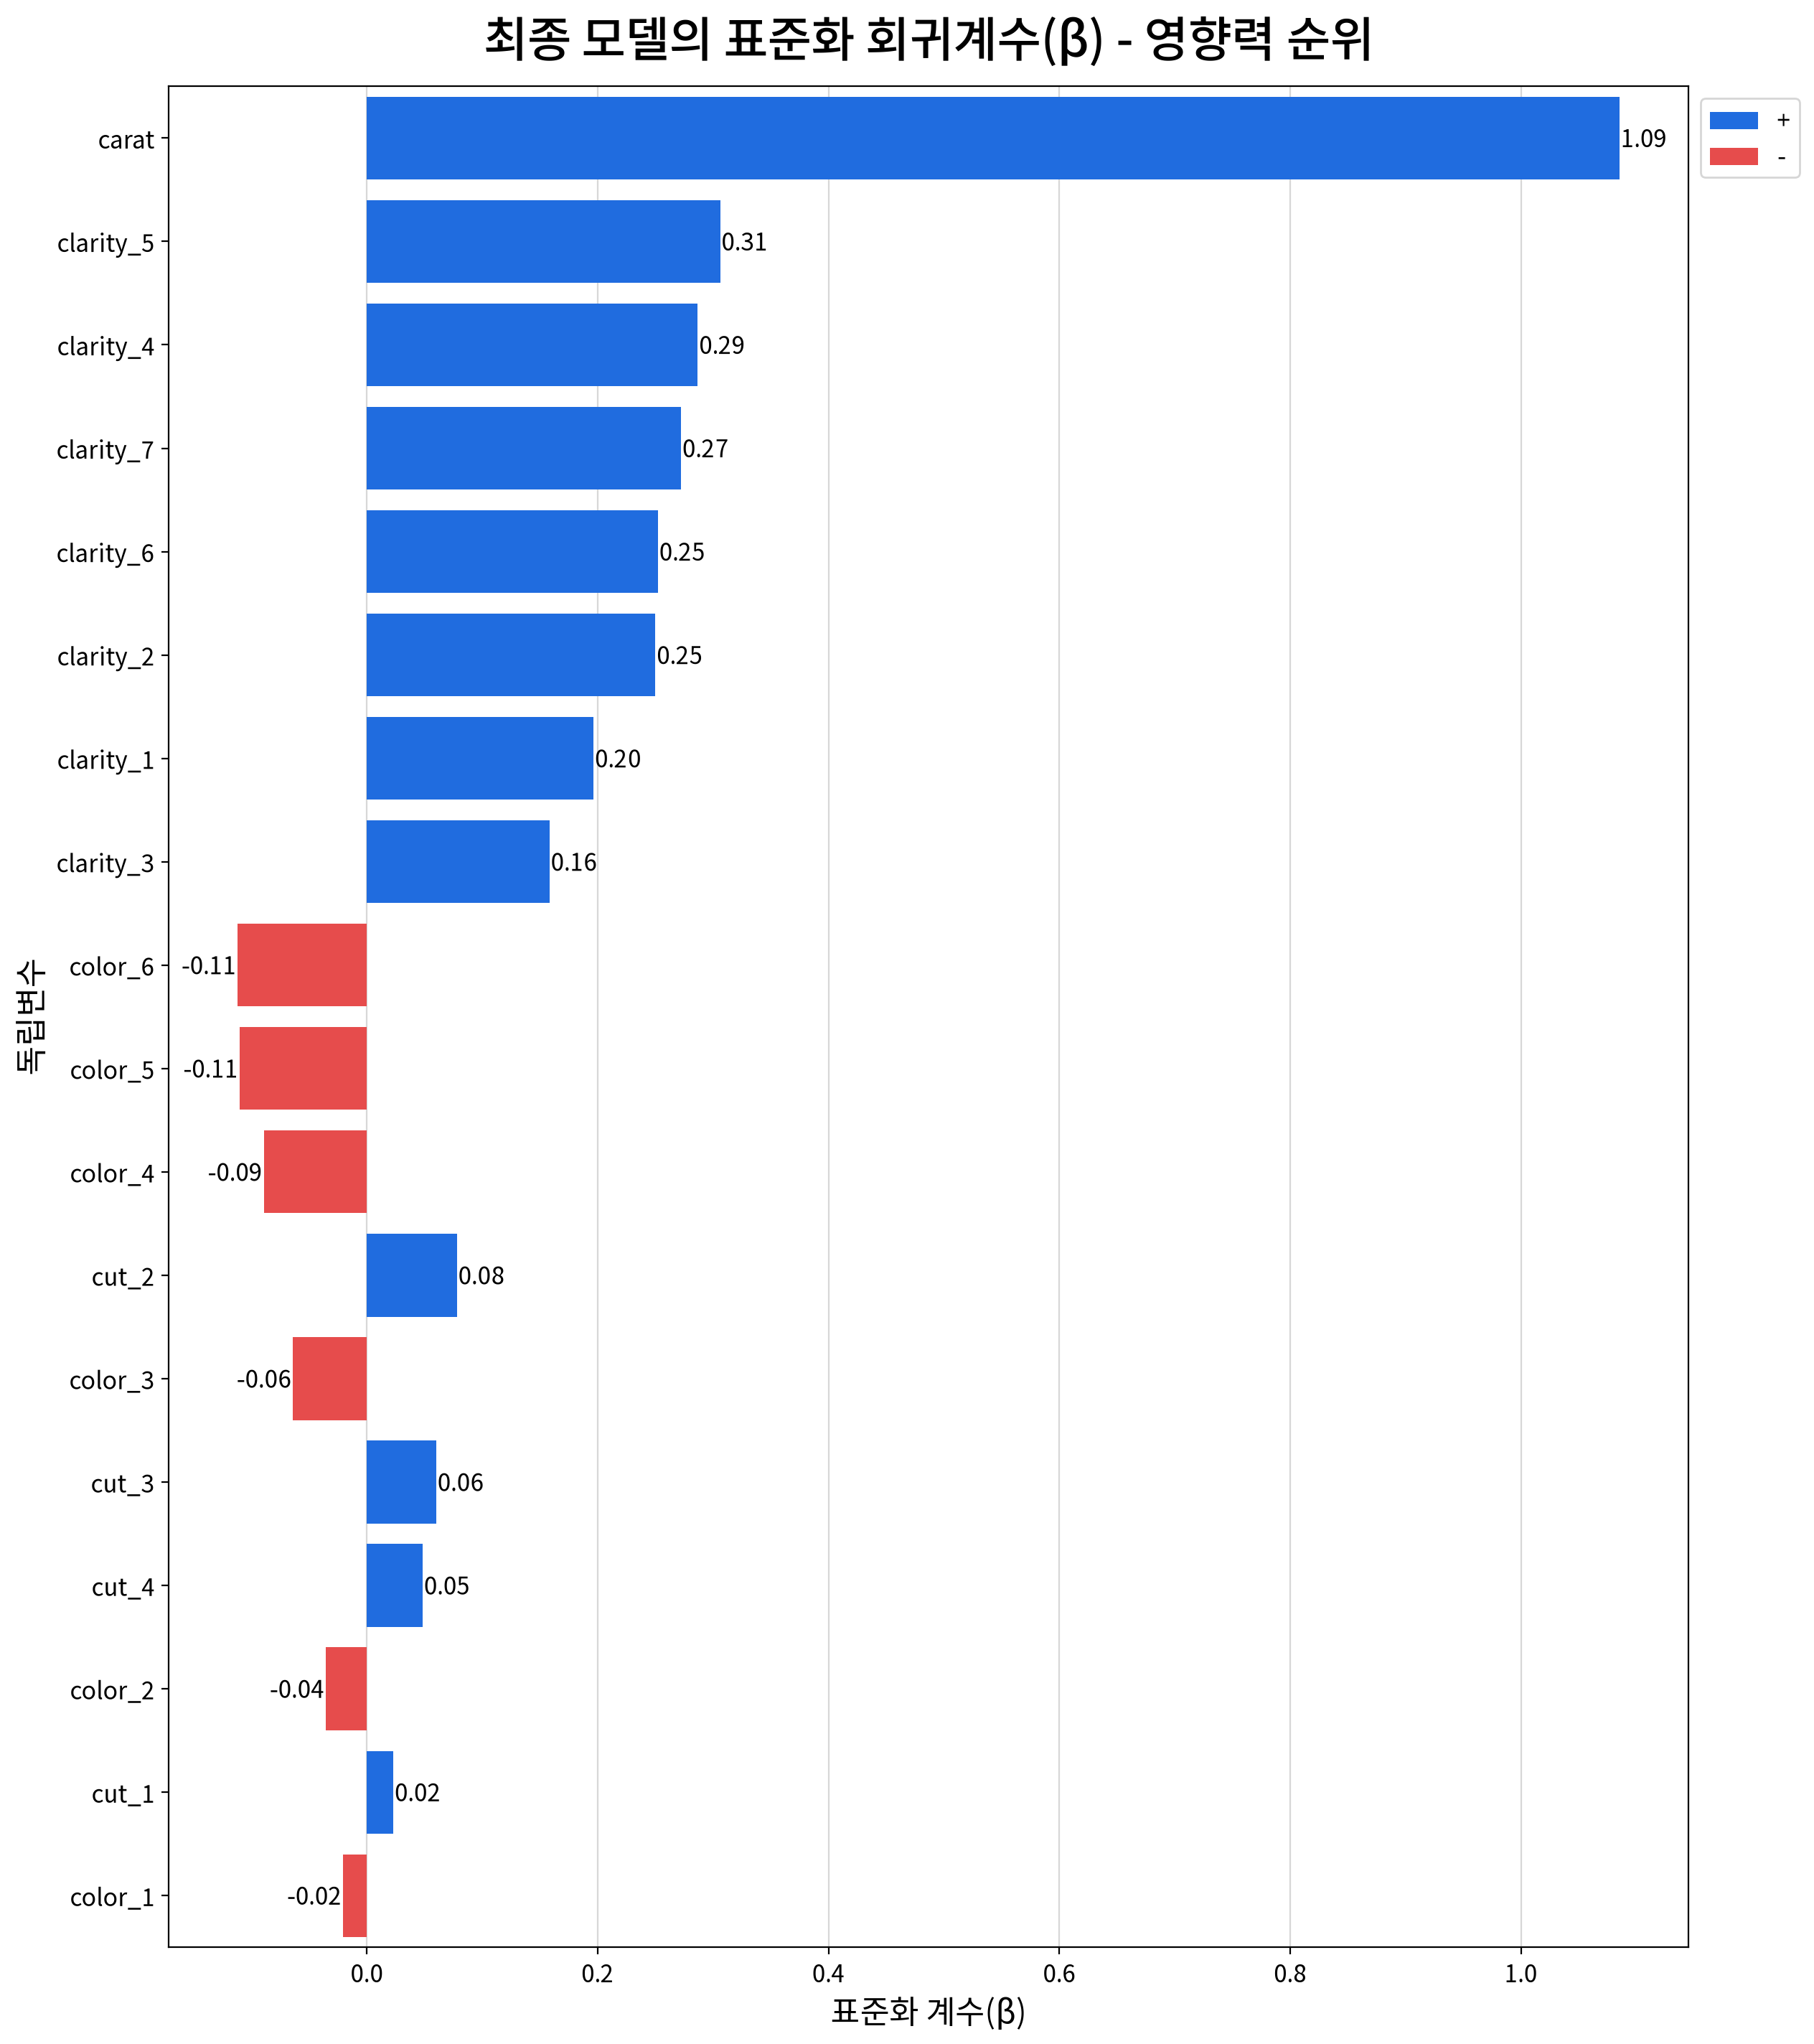

#### 4) 회귀계수 해석 문장

- **carat** 의 회귀계수는 **B = 1.88** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = 1452.49**, **p < .001**) 즉, carat가 **1% 증가**할 때 price는 평균적으로 약 **1.88% 증가**하는 것으로 해석된다.
- **cut_1** 의 회귀계수는 **B = 0.08** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = 17.17**, **p < .001**) 즉, cut_1가 **1 증가**할 때 price는 평균적으로 약 **8.44% 증가**하는 것으로 해석된다.
- **cut_2** 의 회귀계수는 **B = 0.16** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = 36.19**, **p < .001**) 즉, cut_2가 **1 증가**할 때 price는 평균적으로 약 **17.54% 증가**하는 것으로 해석된다.
- **cut_3** 의 회귀계수는 **B = 0.14** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = 31.09**, **p < .001**) 즉, cut_3가 **1 증가**할 때 price는 평균적으로 약 **15.01% 증가**하는 것으로 해석된다.
- **cut_4** 의 회귀계수는 **B = 0.12** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = 26.17**, **p < .001**) 즉, cut_4가 **1 증가**할 때 price는 평균적으로 약 **12.48% 증가**하는 것으로 해석된다.
- **color_1** 의 회귀계수는 **B = -0.05** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = -24.0**, **p < .001**) 즉, color_1가 **1 증가**할 때 price는 평균적으로 약 **5.25% 감소**하는 것으로 해석된다.
- **color_2** 의 회귀계수는 **B = -0.09** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = -41.2**, **p < .001**) 즉, color_2가 **1 증가**할 때 price는 평균적으로 약 **9.01% 감소**하는 것으로 해석된다.
- **color_3** 의 회귀계수는 **B = -0.16** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = -71.55**, **p < .001**) 즉, color_3가 **1 증가**할 때 price는 평균적으로 약 **14.79% 감소**하는 것으로 해석된다.
- **color_4** 의 회귀계수는 **B = -0.25** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = -107.3**, **p < .001**) 즉, color_4가 **1 증가**할 때 price는 평균적으로 약 **22.19% 감소**하는 것으로 해석된다.
- **color_5** 의 회귀계수는 **B = -0.37** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = -142.31**, **p < .001**) 즉, color_5가 **1 증가**할 때 price는 평균적으로 약 **31.10% 감소**하는 것으로 해석된다.
- **color_6** 의 회귀계수는 **B = -0.51** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = -154.96**, **p < .001**) 즉, color_6가 **1 증가**할 때 price는 평균적으로 약 **40.02% 감소**하는 것으로 해석된다.
- **clarity_1** 의 회귀계수는 **B = 1.11** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = 118.84**, **p < .001**) 즉, clarity_1가 **1 증가**할 때 price는 평균적으로 약 **204.21% 증가**하는 것으로 해석된다.
- **clarity_2** 의 회귀계수는 **B = 0.59** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = 69.06**, **p < .001**) 즉, clarity_2가 **1 증가**할 때 price는 평균적으로 약 **80.74% 증가**하는 것으로 해석된다.
- **clarity_3** 의 회귀계수는 **B = 0.43** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = 49.49**, **p < .001**) 즉, clarity_3가 **1 증가**할 때 price는 평균적으로 약 **53.31% 증가**하는 것으로 해석된다.
- **clarity_4** 의 회귀계수는 **B = 0.81** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = 94.07**, **p < .001**) 즉, clarity_4가 **1 증가**할 때 price는 평균적으로 약 **125.02% 증가**하는 것으로 해석된다.
- **clarity_5** 의 회귀계수는 **B = 0.74** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = 86.31**, **p < .001**) 즉, clarity_5가 **1 증가**할 때 price는 평균적으로 약 **109.77% 증가**하는 것으로 해석된다.
- **clarity_6** 의 회귀계수는 **B = 1.02** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = 114.35**, **p < .001**) 즉, clarity_6가 **1 증가**할 때 price는 평균적으로 약 **176.66% 증가**하는 것으로 해석된다.
- **clarity_7** 의 회귀계수는 **B = 0.95** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(53753) = 107.58**, **p < .001**) 즉, clarity_7가 **1 증가**할 때 price는 평균적으로 약 **157.56% 증가**하는 것으로 해석된다.

> ※ 위 **t** 와 **유의확률** 은 등분산 가정이 충족되지 않은 경우를 대비해 **HC3 로버스트 표준오차**로 계산한 값이다.   
회귀계수(B)와 효과 크기 해석은 일반 OLS와 동일하며, 표준오차만 이분산에 강건하게 보정되어 t와 유의확률, 그에 따른 유의성 판정이 달라질 수 있다.

---

### ▶ 회귀모형 가정 검정

#### 1) 선형성 검정

,statistic,p-value,linearity,result
Ramsey RESET,928.429,0.000,False,대립가설 채택 → 선형성 위배(곡선 관계 존재)


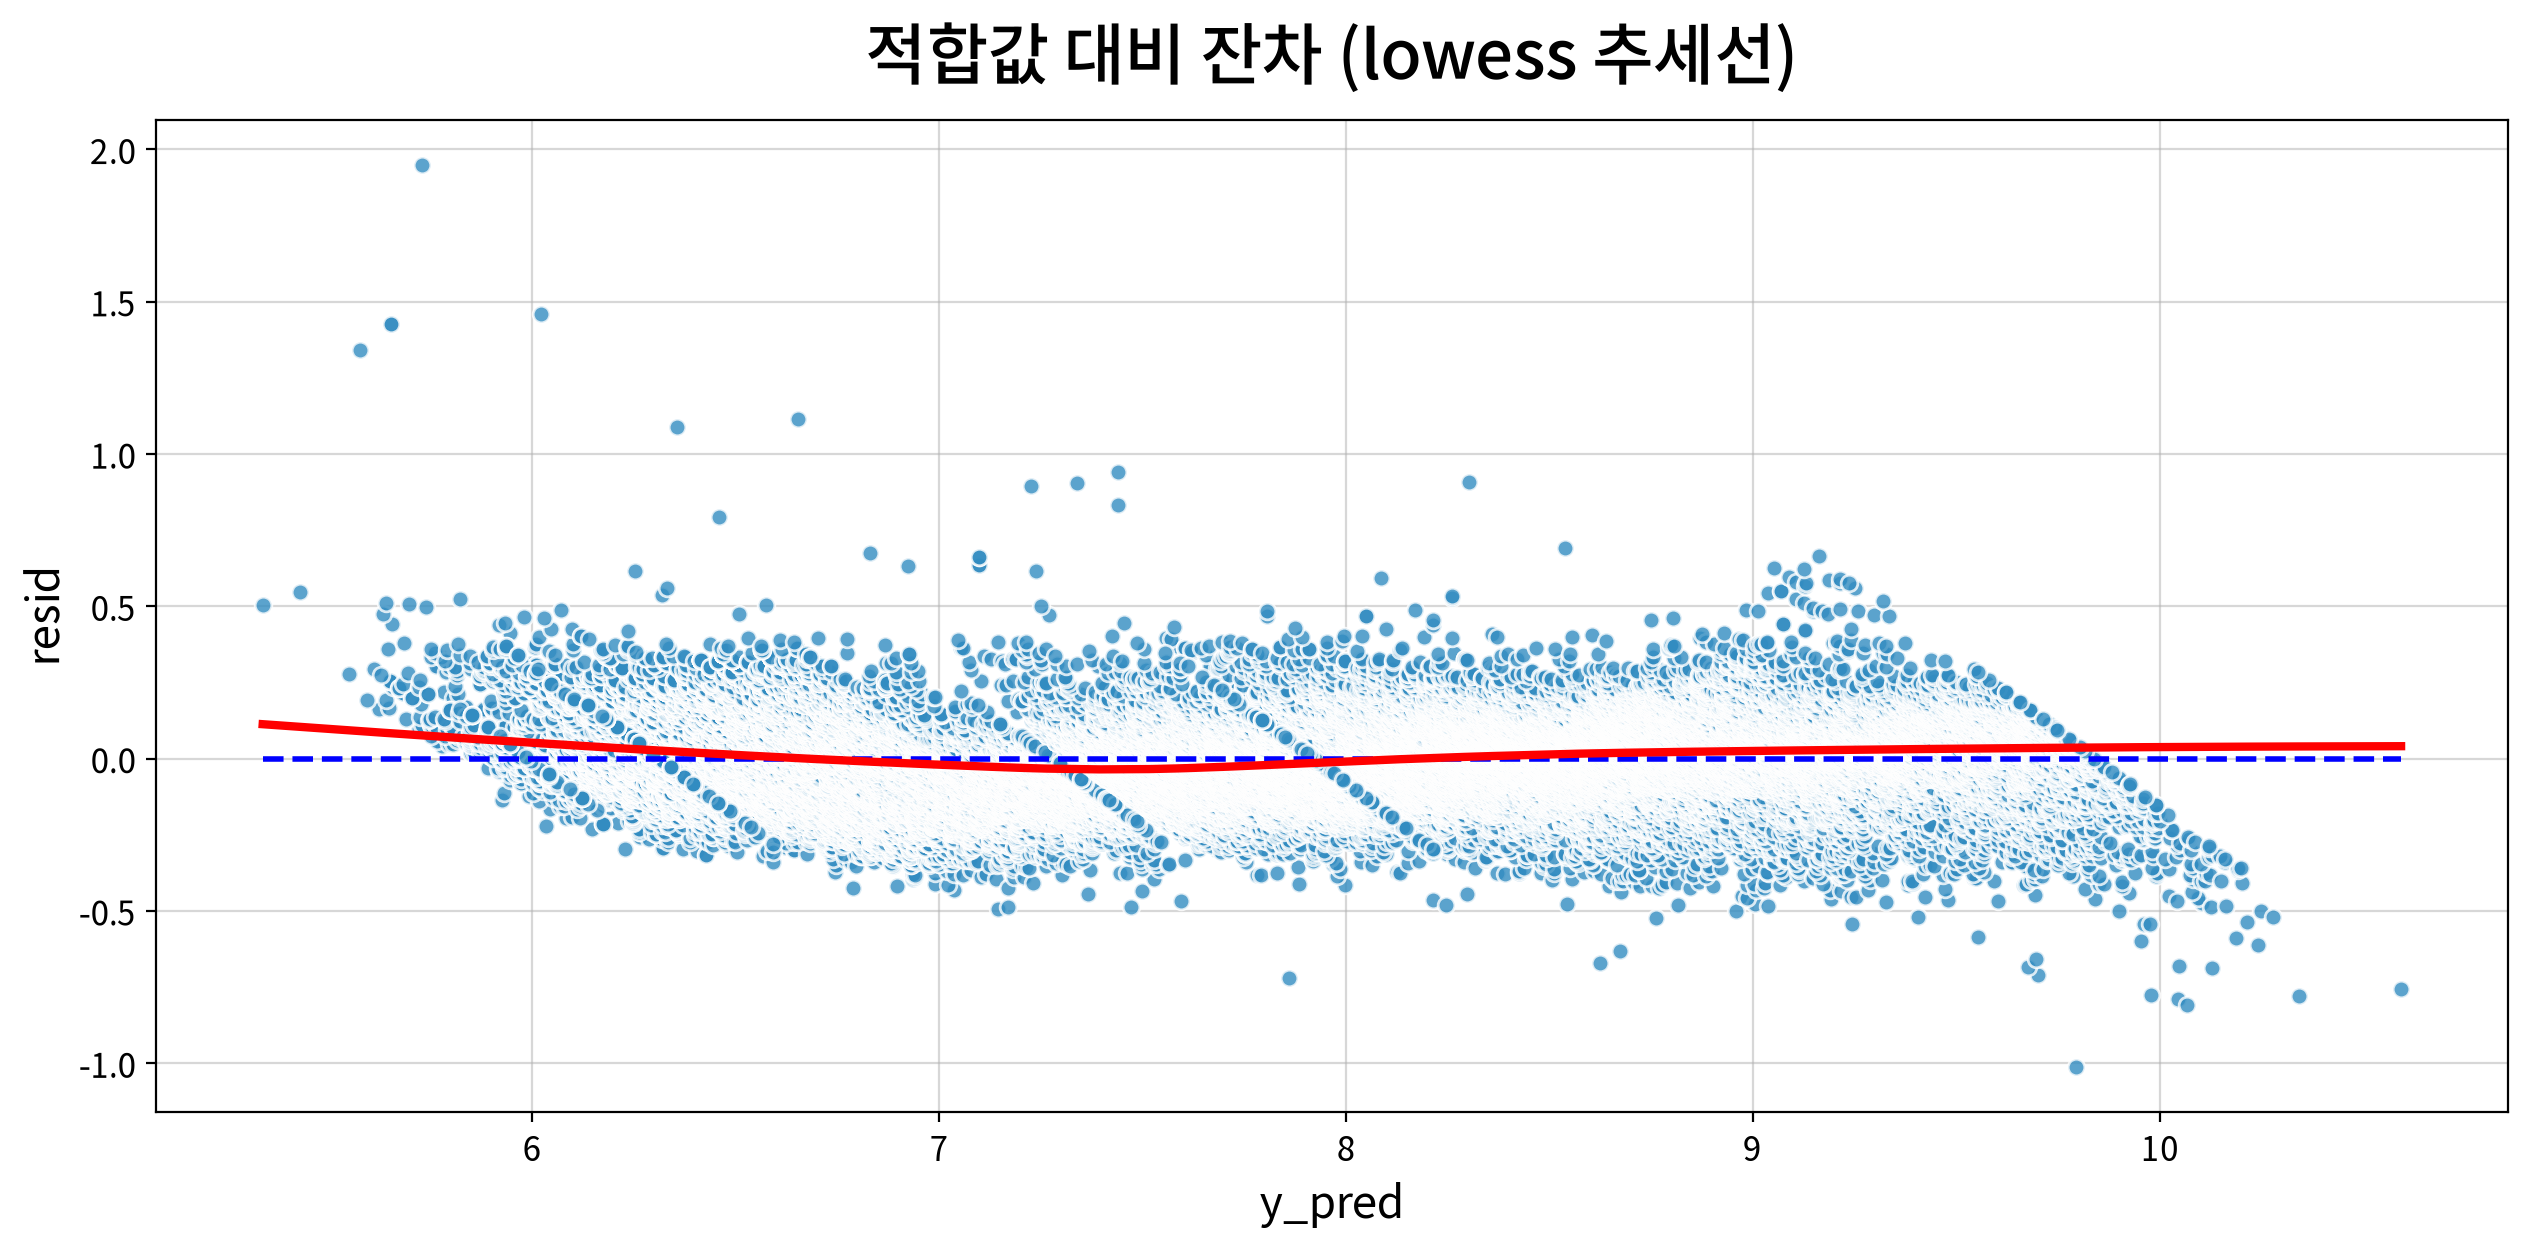

#### 2) 정규성 검정

▶ 검정통계량을 이용한 정규성 검정

,statistic,p-value,normality,result
Kolmogorov-Smirnov,0.018,0.000,False,대립가설 채택 → 정규성 위배


▶ Q-Q 플롯을 이용한 정규성 검정

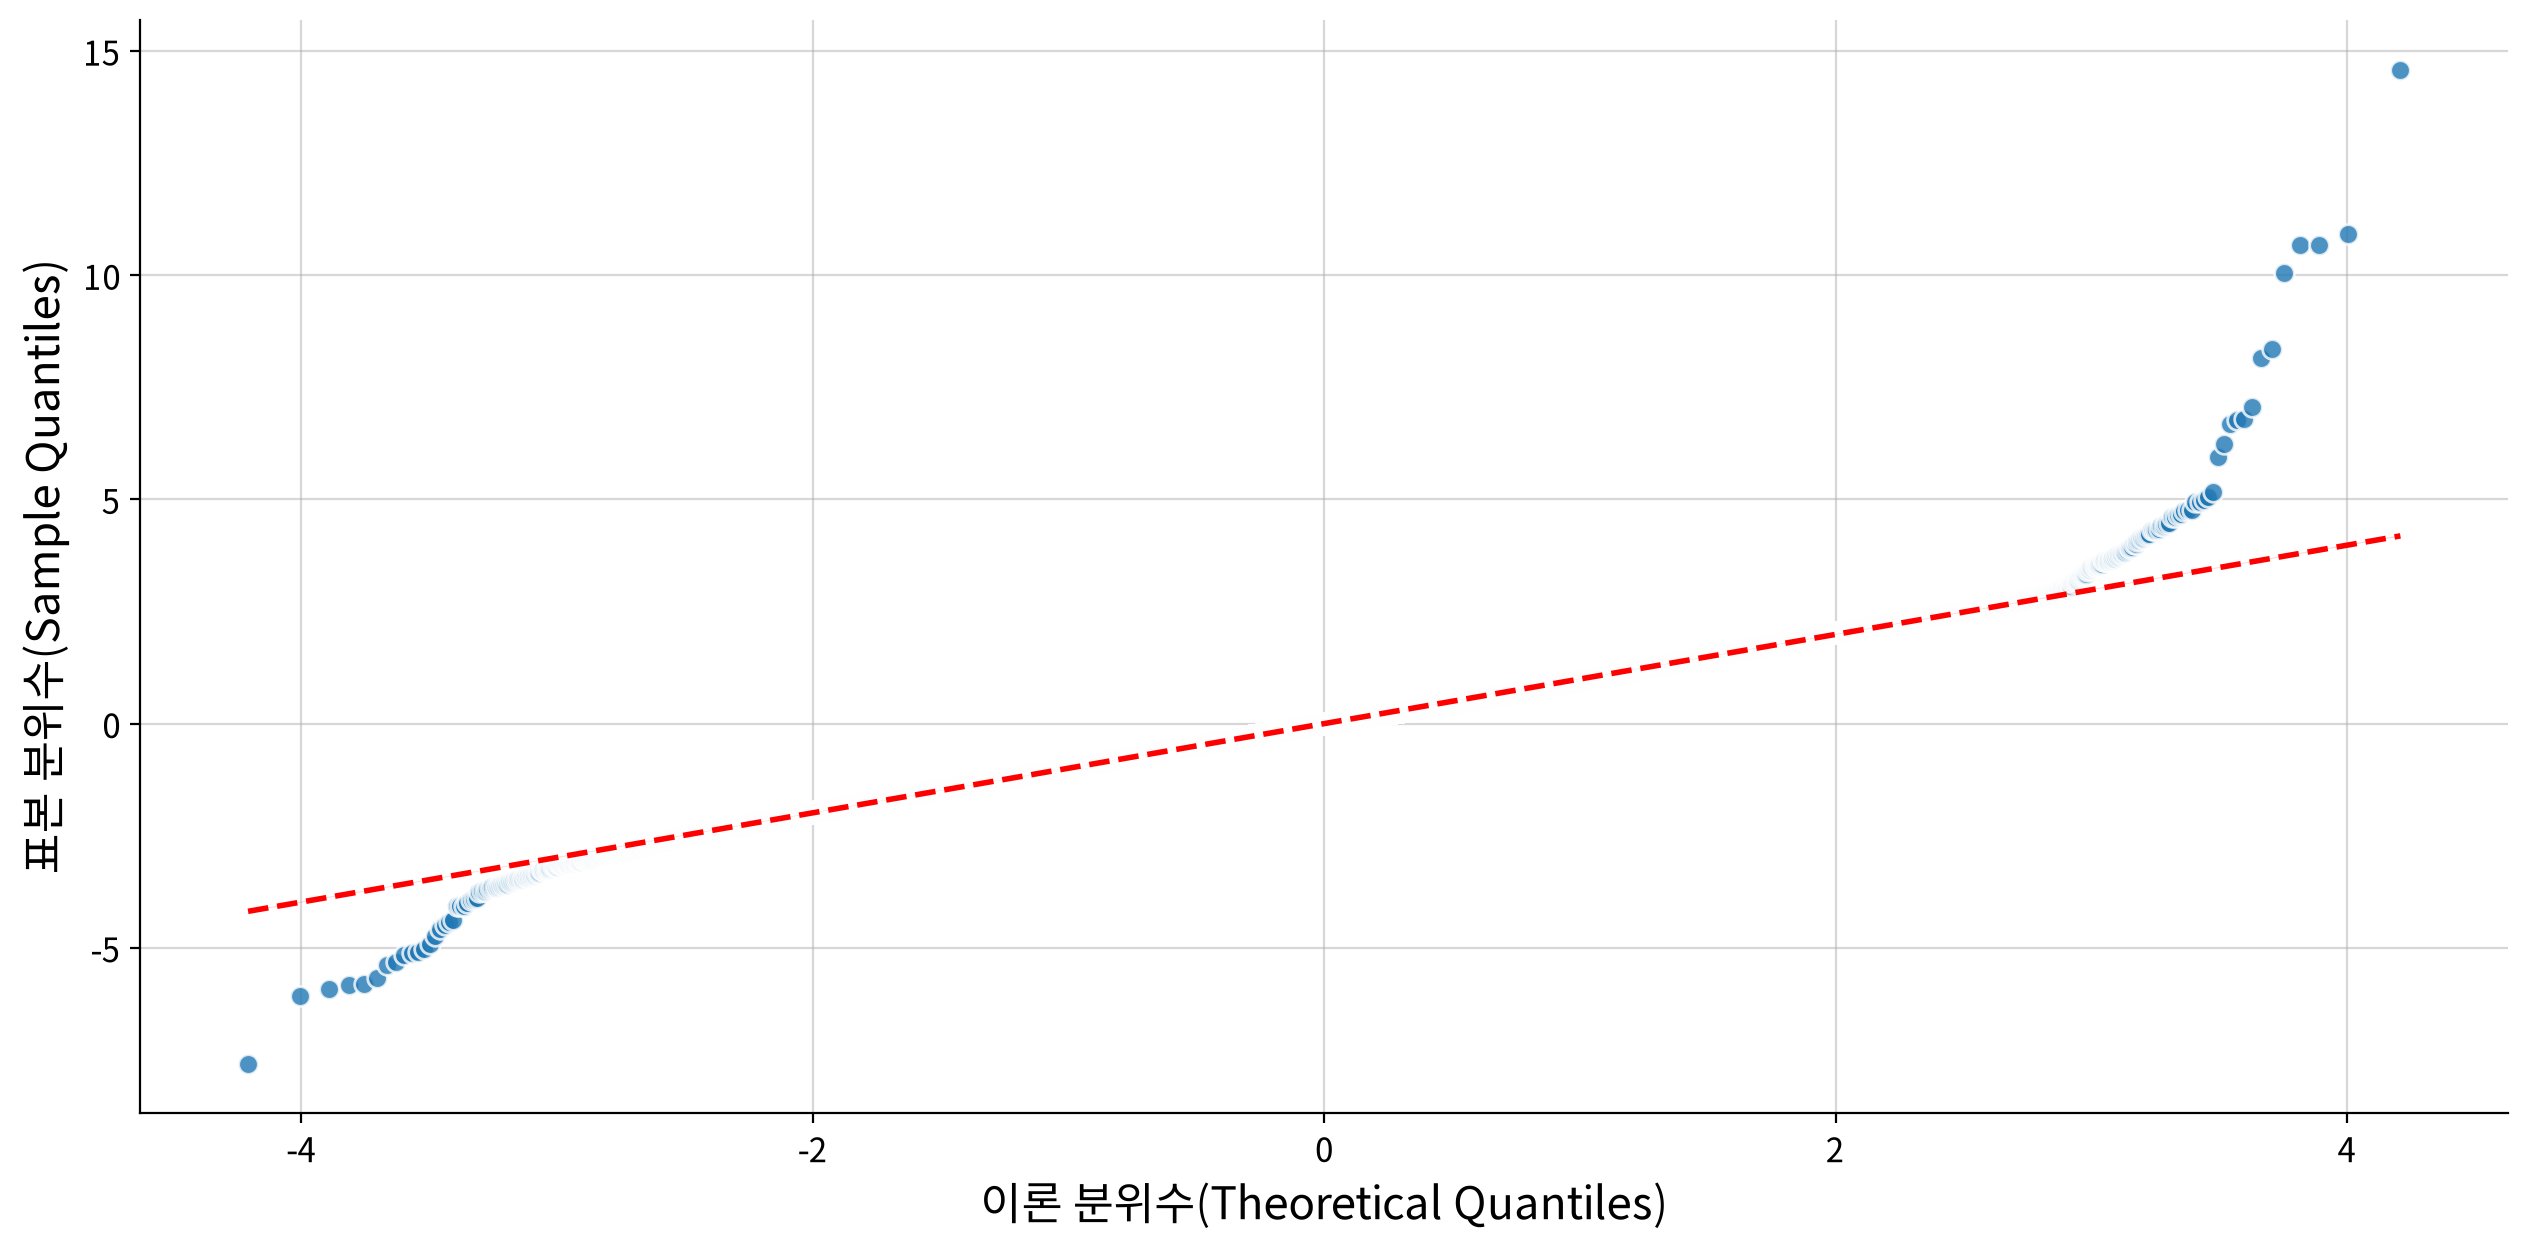

▶ √MSE 구간 규칙을 이용한 정규성 검정

,기대(%),허용 구간(%),실제(%),판정
구간,,,,
±1√MSE,68.000,68~68,69.740,위배
±2√MSE,95.000,95~95,95.420,위배
±3√MSE,99.700,100~100,99.600,위배


√MSE = 0.13 · 구간 규칙 판정: 정규성 위배


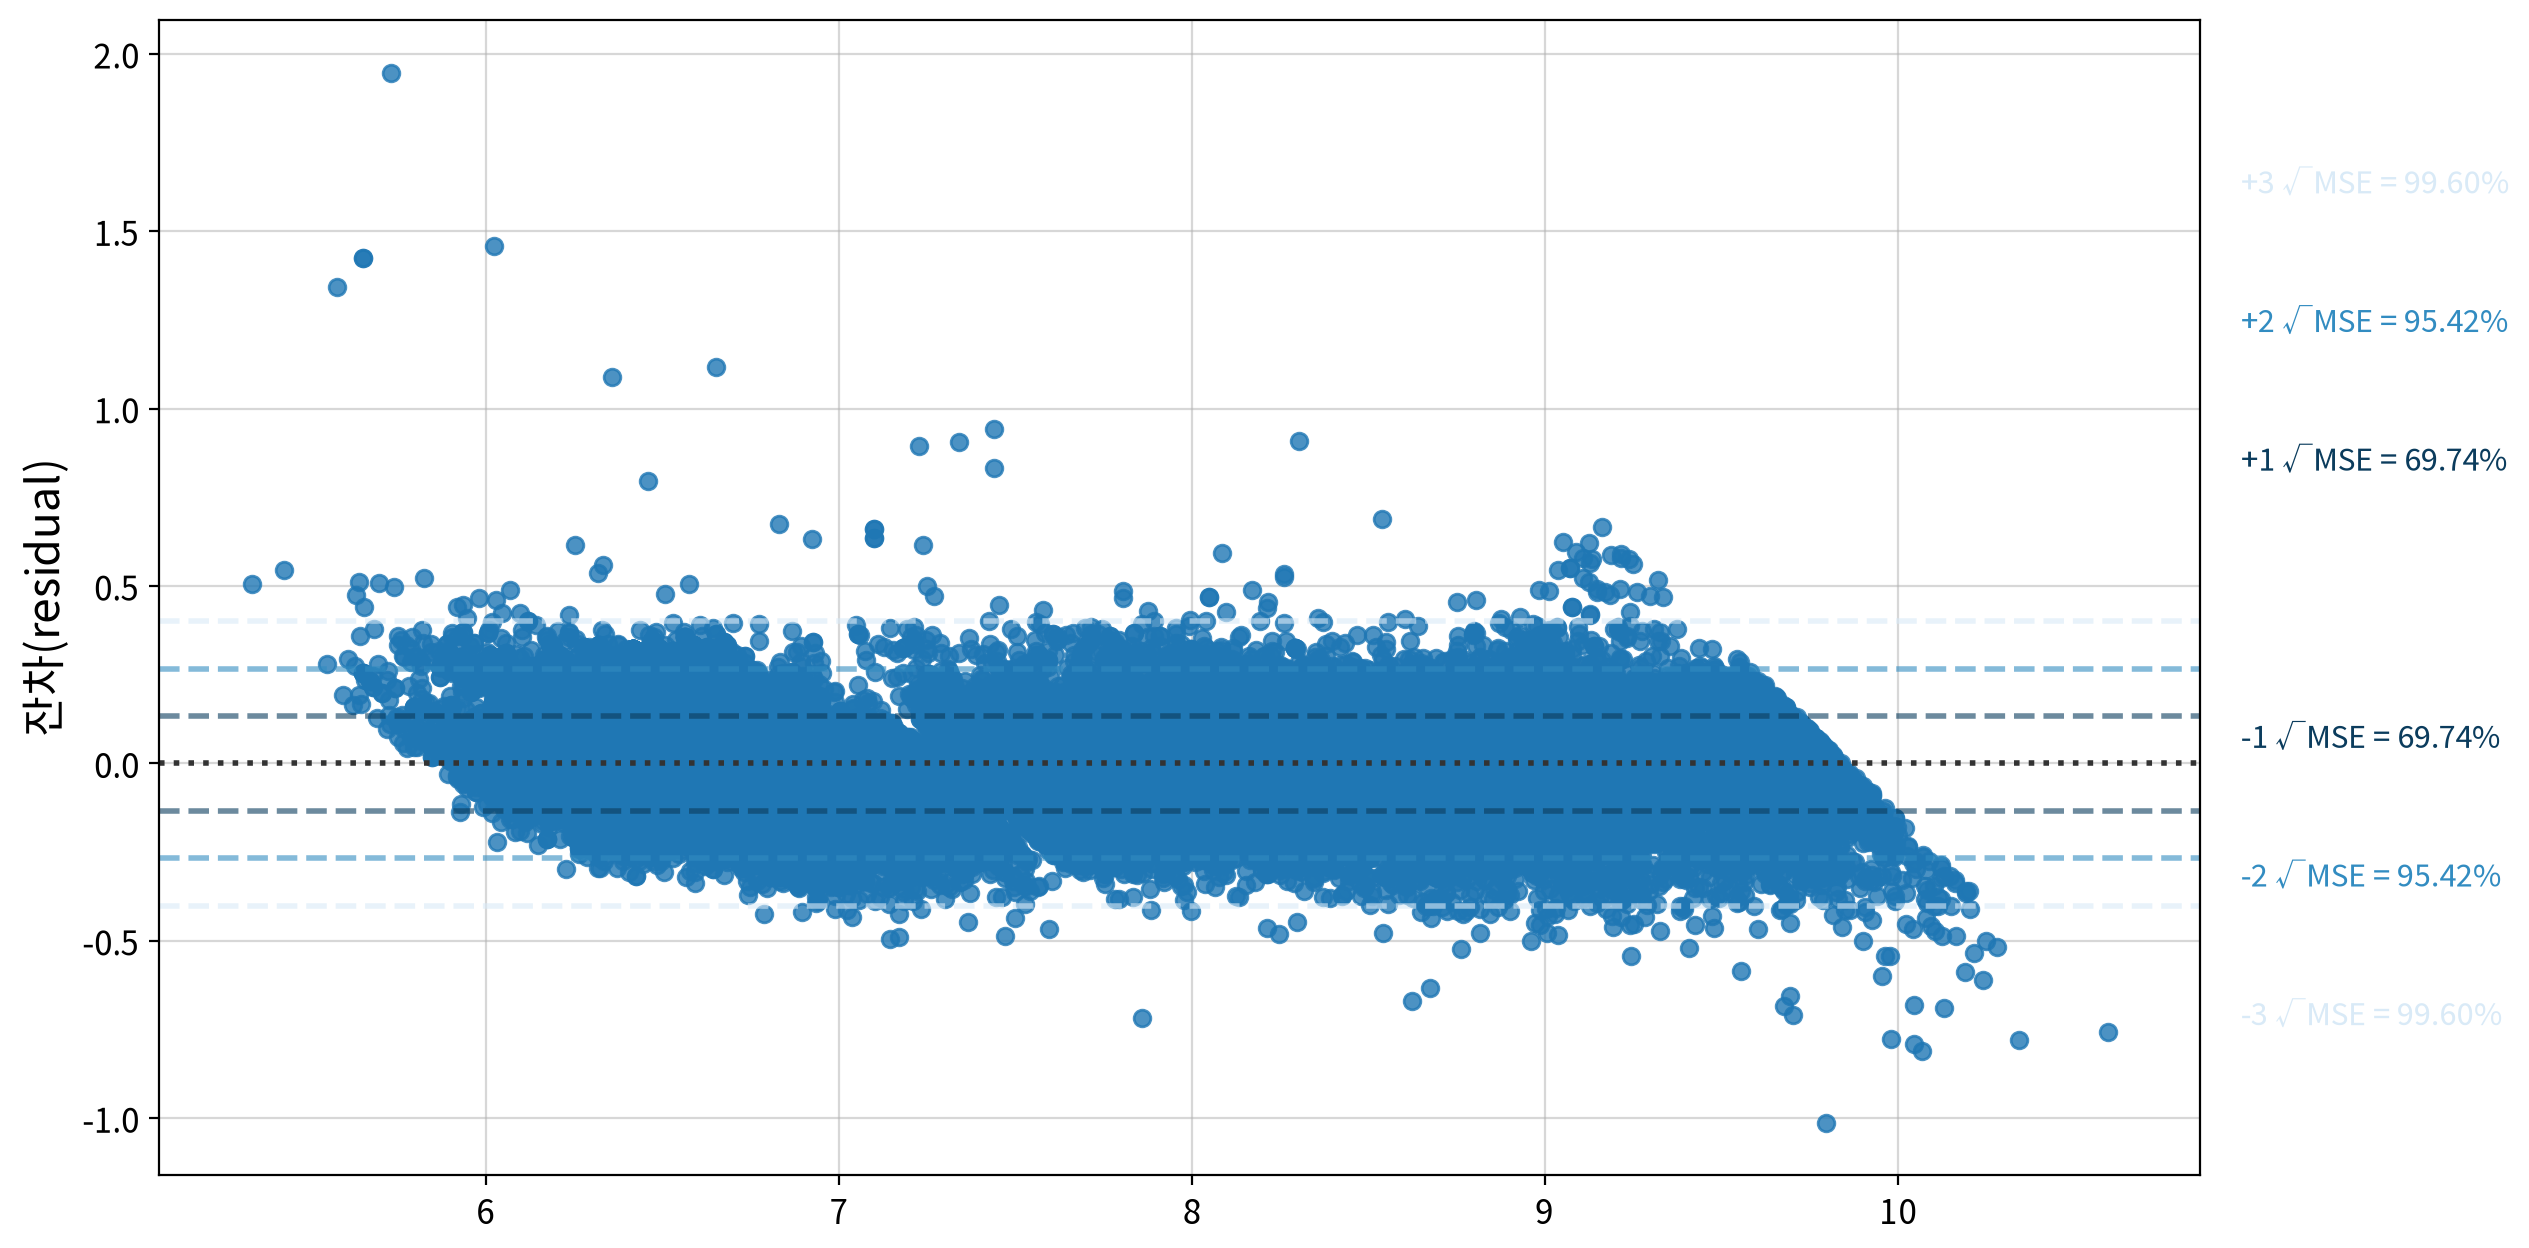

#### 3) 등분산성 검정

,LM Statistic,LM p-value,F Statistic,F p-value,homoscedasticity
Breusch-Pagan,"1,333.789",0.000,75.957,0.000,False


F p-value = 0.0000 · 등분산성 판정: 대립가설 채택 → 등분산성 위배



#### 4) 독립성 검정

,statistic,independence,result
Durbin-Watson,1.252,False,독립성 위반 (양(+)의 자기상관)


In [29]:
my_ols.report_model(final_fit)

> 💡 **인사이트 — 최종 모델: 로그-로그 모델**
>
> - 최종 모델은 **`7_도메인_이상치대체`** 다. `log(price)`와 `log(carat)`을 쓰는 **로그-로그 모델**이고, `carat`의 이상치를 대체했다.
> - **F(18, 53753) = 169,308, p < .001, R² = 0.983** — log(가격) 변동의 98.3%를 설명한다.
> - **중량이 압도적이다**: `carat` β = 1.085로, 2위(`clarity_5` = VS2, β = 0.306)의 3.5배다.
> - `carat`의 계수 **B = 1.884는 탄력성**이다 — **중량이 1% 늘면 가격은 약 1.88% 오른다.** 2배 무거우면 약 2^1.884 ≈ **3.7배** 비싸다. 큰 다이아몬드가 '가파르게' 비싼 이유다.
> - **중량을 통제하자 등급 순서가 완벽하게 복원됐다** (더미 이름은 알파벳 순 라벨, 아래는 원래 등급으로 풀어 쓴 것):
>
> | 등급 | 기준 범주 | 기준 대비 가격 차이 (낮은 등급 → 높은 등급) | 순서 일치 |
> |---|---|---|---|
> | cut | Fair | Good +8.4% → Very Good +12.5% → Premium +15.0% → Ideal +17.5% | ✅ |
> | color | D (최고) | E −5.3% → F −9.0% → G −14.8% → H −22.2% → I −31.1% → J −40.0% | ✅ |
> | clarity | I1 (최하) | SI2 +53% → SI1 +81% → VS2 +110% → VS1 +125% → VVS2 +158% → VVS1 +177% → IF +204% | ✅ |
>
> - `color`만 계수가 모두 음수인 것은, `labeling`이 알파벳 순으로 번호를 매겨 **최고 등급 D가 기준 범주**가 됐기 때문이다. 'D보다 얼마나 싼가'로 읽으면 된다.
> - EDA에서 '나쁜 등급이 더 비싸다'던 역설이 **같은 중량이라면 좋은 등급이 비싸다**는 상식으로 돌아왔다. 투명도 IF는 I1보다 **약 3배** 비싸다.
> - 가정 검정: 네 가지 모두 위배다. 다만 **n = 53,772처럼 표본이 크면 아주 작은 차이도 유의**하게 나온다. √MSE 구간 규칙에서 실제 비율(69.7% / 95.4% / 99.6%)이 기대(68 / 95 / 99.7%)와 거의 같아 정규성 위배는 실질적으로 미미하다. DW = 1.25는 원본 데이터가 **가격 순으로 정렬**돼 있어 생긴 현상이다. 등분산 위배는 HC3로 보정했다.

---

# 📌 종합 인사이트

### 1. 가격은 '중량'이 결정하고, 그 관계는 가파르게 체증한다
- 로그-로그 모델의 `carat` 탄력성 **1.884**: 중량이 2배면 가격은 약 3.7배.
- 표준화 계수 β = 1.085로 2위(`clarity` VS2, 0.306)의 **3.5배**다. 단일 변수로는 중량의 영향이 압도적이다.

### 2. 단순 평균은 거짓말을 한다 — 등급의 역설
- 평균만 보면 최저 색상 J(5,326달러)가 최고 색상 D(3,173달러)보다, 최저 투명도 I1(3,927달러)이 최고 투명도 IF(2,871달러)보다 비쌌다. **큰 원석일수록 낮은 등급에 몰리는** 교란(confounding) 때문이다.
- 중량을 통제한 회귀에서는 cut · color · clarity **세 등급 모두 순서가 완벽하게 복원**됐다.

### 3. VIF는 '무엇을' 남길지 모른다
- 상관이 거의 같은 크기 변수 넷 중 VIF가 남긴 것은 `z`(깊이)였고, RMSE가 **1,663달러**로 도메인 모델(796달러)의 **2배가 넘었다.**
- 도메인 지식으로 `carat`만 남긴 모델이 **RMSE 796달러로 최고 성능**을 냈다. 크기 변수를 모두 넣은 기계적 최선 모델(RMSE 833달러, 21개)보다 **변수도 3개 적다.**

### 4. 품질 점검이 '불가능한 값'을 잡아냈다
- 기술통계의 최솟값 · 최댓값에서 치수 0mm · 58.9mm · 31.8mm 같은 **물리적으로 불가능한 값**을 찾아, 입력 오류 22행을 제거했다.

### ⚠️ 한계
- 선형성 위배(RESET)가 남아 있다. 중량 구간별로 탄력성이 다를 수 있다(예: 1캐럿 경계 프리미엄).
- 등급 효과는 모든 중량에서 같다고 가정했다. 실제로는 큰 돌일수록 등급 프리미엄이 커질 수 있다(`carat × clarity` 상호작용).
- 성능(RMSE 796달러)은 모델을 학습시킨 데이터로 평가한 값(in-sample)이다. 처음 보는 데이터에서의 예측력은 train/test 분할이나 교차검증으로 확인해야 한다.

### ✅ 최종 모델
| 항목 | 값 |
|---|---|
| 모델 | `7_도메인_이상치대체` |
| 형태 | `log(price)` ~ `log(carat)` + cut · color · clarity 더미 (18개) |
| 성능 (달러) | **RMSE 796** · MAE 403 · R² 0.960 (원본 척도) |
| 가장 큰 영향 | `carat` (β = 1.085, 탄력성 1.884) |